# Does Model Complexity Earn Its Keep? An Exploratory 48-Hour Forecasting Study

### Executive summary

I compared **32 forecasting procedures** for predicting hourly ads watched in
one Zeptolab mobile game. Each procedure issued the next **48 hours at once**.
That horizon shaped the whole comparison: which lagged observations were
available, how I tuned models, and which future paths I scored.

After **336 initial training hours**, I evaluated **29 nonoverlapping development
paths** from August 17 through October 13, 2017. I selected the deployment
procedure by its lowest mean per-origin MASE (Mean Absolute Scaled Error), using
a 24-hour seasonal-naive forecast as the benchmark. Six later paths supplied
**288 historical validation hours**, from October 14 through October 25. I had
already examined those validation outcomes during research, so this is an
exploratory comparison rather than a fresh confirmatory holdout experiment.

The selected procedure was **SARIMA (1,0,0)(0,1,1) with seasonal period 24 and
weekly Fourier regressors (period 168)**, choosing **K from {2,3,4} by AIC at
each origin on a common likelihood sample within each search**. Its mean
development MASE was **0.954947**. It also led the reported historical validation
comparison at **1.016**, versus **1.319** for seasonal naive. These results
support this complete refit-and-select procedure on the observed targets;
they leave its performance on new periods open to evaluation.

Several plausible additions produced mixed or unsuccessful results. The
Box-Cox variants remained worse than raw SARIMA on matched paths, and a small
contrast between transformed-order strategies reversed across executions.
Regression, boosting, Prophet, and combinations provided useful alternatives,
but greater flexibility did not consistently reduce the selected loss.

The clearest distinction was between **point accuracy and interval calibration**.
The selected procedure's nominal **80% pointwise** band covered **70.83%
(204/288)** of validation hours, with prominent upper-sided misses across only
six potentially dependent paths. Its favorable point-error ranking therefore
needs to be read alongside a material weakness in uncertainty quantification.

I finished by refitting the selected procedure on all **2,085 observations**,
including the **69-hour tail excluded from evaluation targets**, and forecasting
**2017-10-28 21:00 through 2017-10-30 20:00**. Calibration paths began at midnight,
so using those horizon-specific bands for a 21:00 start requires an unverified
schedule transfer. There are no observed future actuals for this final path.

The notebook follows the investigation from data and seasonal structure through
the complete model comparison, statistical evidence, interval assessment, and
final forecast. I retain unsuccessful experiments because they help delimit what
the observed improvement means. The [README](README.md) provides the environment
and reproduction instructions.

**Data and acknowledgments.** The Zeptolab dataset and initial lag-feature/PCA
setup came through mlcourse.ai's time-series materials. I extended that starting
point with temporal comparisons, statistical inference, and uncertainty
assessment. The references credit sources and adapted educational material.
Third-party data and material retain their own terms; this project makes no
new grant of rights over them.


**Contents**

- Section 0: Setup and Data Checks
- Section 1: Forecast Design and Information Sets
- Section 2: Forecast Quality Metrics
- Section 3: Understanding the Development Series
- Section 4: Benchmarks and Retrospective Anomaly Sensitivity
- Section 5: Classical Smoothing
- Section 6: SARIMA Search and Residual Diagnostics
- Section 7: Representing Weekly Structure
- Section 8: Box-Cox and Forecast Functionals
- Section 9: Feature-Based Machine Learning
- Section 10: Prophet
- Section 11: Forecast Combination
- Section 12: Residual Intervals and Proper Scoring
- Section 13: Development Comparison and Statistical Evidence
- Section 14: Historical Temporal Validation
- Section 15: Forecast Beyond the Observed Data
- Section 16: Limitations and What I Learned
- References


## Section 0: Setup and Data Checks


In [1]:
%matplotlib inline
import warnings, logging, random, time, itertools
from functools import partial

# Convergence and KPSS interpolation warnings are
# suppressed here; audited SARIMAX convergence and KPSS endpoint bounds must be read explicitly.
from statsmodels.tools.sm_exceptions import ConvergenceWarning, InterpolationWarning
warnings.simplefilter("ignore", ConvergenceWarning)
warnings.simplefilter("ignore", InterpolationWarning)
warnings.simplefilter("ignore", FutureWarning)
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)

SEED = 42
random.seed(SEED)
import numpy as np
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

import scipy, sklearn, statsmodels, xgboost, prophet
print("Imported runtime versions (a record, not an environment lock or replay guarantee):")
for _n, _m in [("numpy", np), ("pandas", pd), ("scipy", scipy), ("statsmodels", statsmodels),
               ("scikit-learn", sklearn), ("xgboost", xgboost), ("prophet", prophet)]:
    print(f"  {_n:<14s} {_m.__version__}")
# Read-only result reporting.
"""Read-only descriptions of existing objects; no fitting or resampling.

Embedded after setup imports. These reports run only when the notebook is later
executed. They do not alter scores, models, partitions, random state or selection.
"""
import numpy as np
import pandas as pd


def _c_kpss_p(p):
    """Statsmodels' tabulated KPSS endpoints are bounds, not exact p-values."""
    prefix = "<=" if p <= 0.01 else ">=" if p >= 0.10 else ""
    return prefix + f"{p:.4f}"


def _c_show_partition(frame, development, validation, horizon):
    dev_start = development["validation_start"].min()
    test_end = validation["validation_end"].max()
    rows = [
        ("warm-up history", frame.index.min(), dev_start-pd.Timedelta(hours=1), 0),
        ("development targets", dev_start, development["validation_end"].max(), len(development)),
        ("validation targets", validation["validation_start"].min(), test_end, len(validation)),
        ("excluded evaluation tail", test_end+pd.Timedelta(hours=1), frame.index.max(), 0),
    ]
    table = pd.DataFrame([
        dict(block=label, start=start, end=end, folds=folds,
             hours=int(((frame.index >= start) & (frame.index <= end)).sum()))
        for label, start, end, folds in rows
    ]).set_index("block")
    print(f"Computed partition; {horizon}-hour forecast targets. Excluded tail is retained for final refitting.")
    display(table)


def _c_show_development(frame, hourly_profile, weekday_profile):
    y = frame["y"]
    table = pd.Series({
        "development-region start (includes warm-up)": frame.index.min(),
        "development-region end": frame.index.max(),
        "observations": len(frame), "sample mean": y.mean(), "sample std": y.std(ddof=1),
        "minimum": y.min(), "maximum": y.max(),
        "first seven-day mean": y.iloc[:168].mean(),
        "last seven-day mean": y.iloc[-168:].mean(),
        "last/first seven-day mean ratio": y.iloc[-168:].mean()/y.iloc[:168].mean(),
        "hour-profile peak/trough minus one": hourly_profile.max()/hourly_profile.min()-1,
        "weekday-profile peak/trough minus one": weekday_profile.max()/weekday_profile.min()-1,
    }, name="computed value")
    print("Descriptive development values, not a stationarity or causal seasonal-effect test:")
    display(table.to_frame())


def _c_show_ablation(raw_scores, fixed_scores, researched_scores):
    fixed = fixed_scores.set_index("fold")["MASE"]
    researched = researched_scores.set_index("fold")["MASE"]
    raw = raw_scores.set_index("fold")["MASE"]
    if any(s.index.has_duplicates for s in (fixed, researched, raw)):
        raise ValueError("Ablation reporting requires unique fold IDs")
    if set(fixed.index) != set(researched.index) or not set(fixed.index).issubset(raw.index):
        raise ValueError("Ablation reports require the same matched forecast targets")
    table = pd.concat([
        raw.reindex(fixed.index).rename("raw SARIMA, matched folds"),
        fixed.rename("Box-Cox, fixed raw order"),
        researched.reindex(fixed.index).rename("Box-Cox, re-searched order"),
    ], axis=1)
    print(f"Matched ablation only: {len(table)} identical fold IDs; unrounded stored MASE.")
    display(table.mean().rename("matched mean MASE").to_frame())
    print("Re-search minus fixed-order mean MASE (negative means lower observed loss): "
          f"{(table.iloc[:, 2]-table.iloc[:, 1]).mean():+.6f}")


def _c_show_lasso(coefficients, parameters):
    table = coefficients.rename("standardized-feature coefficient").to_frame()
    table["retained"] = coefficients != 0
    print(f"Last-development-origin probe: alpha={parameters['m__alpha']}; "
          f"{int(table['retained'].sum())}/{len(table)} coefficients are nonzero.")
    display(table.loc[table["retained"]].sort_values("standardized-feature coefficient"))
    print("This probe does not describe every outer-fold feature selection or causal effects.")


def _c_show_model_spread(results, benchmark):
    base = results[benchmark].set_index("fold")["MASE"]
    rows = []
    if base.index.has_duplicates:
        raise ValueError("Spread reporting requires unique benchmark fold IDs")
    for name, scores in results.items():
        loss_series = scores.set_index("fold")["MASE"]
        if loss_series.index.has_duplicates or set(loss_series.index) != set(base.index):
            raise ValueError("Spread reporting requires identical forecast targets")
        loss_series = loss_series.reindex(base.index)
        rows.append(dict(model=name, mean_MASE=loss_series.mean(), median_MASE=loss_series.median(),
                         fold_MASE_sd=loss_series.std(ddof=1),
                         mean_dMASE=(loss_series-base).mean(),
                         folds_below_benchmark=int((loss_series < base).sum()), n_folds=len(loss_series)))
    table = pd.DataFrame(rows).set_index("model")
    table["sd_rank_all_configurations"] = table["fold_MASE_sd"].rank(method="min")
    print("Observed accuracy and fold variability are separate quantities; lower SD alone is not better forecasting.")
    display(table.sort_values("mean_MASE"))


def _c_show_candidate_counts(fitted_names, published_names, score_results):
    fitted, published = set(fitted_names), set(published_names)
    constructed = set(score_results)-fitted
    rows = pd.Series({
        "registered configurations refitted": len(fitted),
        "published candidates": len(published),
        "refitted supporting configurations only": len(fitted-published),
        "constructed combinations": len(constructed),
        "constructed combinations not published": len(constructed-published),
    }, name="count")
    print("Counts distinguish refits from derived combinations and the published candidate set:")
    display(rows.to_frame())
    print("Supporting refits:", sorted(fitted-published))


def _c_show_forecast(point, benchmark, lower, upper, n_calibration, future_dates, development_folds):
    point, benchmark, lower, upper = [np.asarray(x) for x in (point, benchmark, lower, upper)]
    if not (point.shape == benchmark.shape == lower.shape == upper.shape == (len(future_dates),)):
        raise ValueError("Forecast reporting requires aligned paths and interval endpoints")
    contained = (benchmark >= lower) & (benchmark <= upper)
    calibration_hours = sorted(development_folds["forecast_origin"].dt.hour.unique().tolist())
    deployment_hour = int((future_dates[0]-pd.Timedelta(hours=1)).hour)
    table = pd.Series({
        "point forecast minimum": point.min(), "point forecast maximum": point.max(),
        "mean pointwise half-width": np.mean((upper-lower)/2),
        "calibration paths": int(n_calibration),
        "benchmark steps inside pointwise band": int(contained.sum()),
        "forecast steps": len(point), "benchmark containment fraction": float(contained.mean()),
        "entire benchmark path inside pointwise band": bool(contained.all()),
        "calibration origin hours": str(calibration_hours),
        "deployment origin hour": deployment_hour,
        "deployment origin hour represented in calibration": deployment_hour in calibration_hours,
    }, name="computed value")
    display(table.to_frame())
    print("Benchmark containment is not actual future coverage or evidence of forecast equivalence.")
    print("A new origin hour requires an unverified transfer assumption for these horizon-specific bands.")


Imported runtime versions (a record, not an environment lock or replay guarantee):
  numpy          1.26.4
  pandas         2.3.3
  scipy          1.15.2
  statsmodels    0.14.5
  scikit-learn   1.7.2
  xgboost        3.0.5
  prophet        1.4.0


In [2]:
DATA_PATH = "data/ads_hour.csv"
DATE_FORMAT = "%m/%d/%y %H:%M"          # e.g. "8/3/17 0:00" -- stated explicitly so a silent
raw = pd.read_csv(DATA_PATH, parse_dates=["Date"], date_format=DATE_FORMAT)  # parse failure cannot pass unnoticed
raw = raw.rename(columns={"Date": "ds", "ads": "y"})
print(f"Shape: {raw.shape}")
raw.head()

Shape: (2085, 2)


,ds,y
0,2017-08-03 00:00:00,49136
1,2017-08-03 01:00:00,46450
2,2017-08-03 02:00:00,46355
3,2017-08-03 03:00:00,43748
4,2017-08-03 04:00:00,42281


I checked the time index before constructing lags or forecast paths. Parsing,
ordering, duplicates, missing values, and hourly continuity matter because a
24-row lag should represent 24 hours. Positivity also matters: Box-Cox requires
positive inputs, and the MAPE implementation divides by observed counts.

These checks found a complete, positive hourly series. They support the indexing
and metric calculations while leaving the interpretation of sharp drops to the
later investigation. A complete record can still contain unusual activity or a
measurement problem.

I also recorded the imported library versions to make the computational setting
visible. They describe the environment used here; the README explains its
package-metadata discrepancies and the limits of reproducing it from version
strings alone.


In [3]:
expected_index = pd.date_range(raw["ds"].min(), raw["ds"].max(), freq="h")
audit = pd.Series({
    "Rows": len(raw),
    "Missing / unparseable values": int(raw.isna().sum().sum()),
    "Unparsed timestamps (NaT)": int(raw["ds"].isna().sum()),
    "Duplicate timestamps": int(raw["ds"].duplicated().sum()),
    "Expected hourly rows (min..max)": len(expected_index),
    "Missing hourly timestamps": len(expected_index.difference(raw["ds"])),
    "Non-positive y values": int((raw["y"] <= 0).sum()),
    "Chronologically sorted": bool(raw["ds"].is_monotonic_increasing),
    "Earliest timestamp": raw["ds"].min(),
    "Latest timestamp": raw["ds"].max(),
})
display(audit.to_frame("value"))

assert raw["ds"].notna().all(), (
    f"{int(raw['ds'].isna().sum())} timestamps failed to parse -- check DATE_FORMAT against the file")
df = raw.set_index("ds").sort_index().asfreq("h")
assert df.index.freq is not None, "index must carry an explicit hourly frequency"
assert not df["y"].isna().any(), "no gaps permitted after asfreq"
assert (df["y"] > 0).all(), "strictly positive values required for MAPE and Box-Cox"
assert len(df) == len(raw), "asfreq introduced or dropped rows"
print(f"\nAudit passed. Working frame: {len(df)} hourly observations, "
      f"{df.index.min()} -> {df.index.max()}")

,value
Rows,2085
Missing / unparseable values,0
Unparsed timestamps (NaT),0
Duplicate timestamps,0
Expected hourly rows (min..max),2085
Missing hourly timestamps,0
Non-positive y values,0
Chronologically sorted,True
Earliest timestamp,2017-08-03 00:00:00
Latest timestamp,2017-10-28 20:00:00



Audit passed. Working frame: 2085 hourly observations, 2017-08-03 00:00:00 -> 2017-10-28 20:00:00


## Section 1: Forecast Design and Information Sets

I defined a fixed-origin task: issue all 48 predictions using observations
available at the origin, then advance 48 hours and refit. Predicting one hour
at a time with new observations arriving between predictions would be a
different experiment. The consequences of this horizon are especially important
for the lag features in Section 9.

Within a clean run, the partition is fixed before development EDA and fitting.
My broader research was adaptive: I examined the development region when
choosing representations, transformations, and diagnostics. Some observations
that are future targets of early retrospective folds therefore informed the
surrounding specification choices. I distinguish that research history from
the training data supplied to an estimator at a particular origin.

The tutorials below explain differencing, temporal structure, and leakage.
Their mathematical examples illustrate the methods rather than report results
from this dataset. My development EDA includes both the warm-up history and
the development targets, as the partition table makes explicit.


<details>
<summary><span style="color:red"><strong>📘 About that differencing plan I just mentioned above: Why Do We Remove Trend or Seasonality by Differencing in Time-Series Forecasting?</strong></span></summary>

<br>

>In time-series analysis, trend refers to the long-term direction or underlying movement of a series over time, such as a gradual increase, decrease, or more complex change in its level, whereas seasonality refers to systematic patterns that repeat at regular, predictable intervals, such as hourly, daily, weekly, or yearly cycles. For example, an hourly website-traffic series might exhibit an upward trend as the platform grows over several years, while also showing daily seasonality (higher traffic during certain hours) and weekly seasonality (different traffic patterns on weekdays versus weekends). The key distinction is that trend describes how the underlying level of a series evolves over time, while seasonality describes recurring fluctuations around that level.

> Holt’s method models the level and trend of a time series, but it does not include a seasonal component. When the data contain recurring daily, weekly, or monthly patterns—as the advertising series appears to do—a seasonal extension is required. This leads to triple exponential smoothing, also known as the Holt–Winters method.

> A unit root at one occurs in $Y_t=\phi Y_{t-1}+\varepsilon_t$ when $\phi=1$. For fixed $Y_0$ and independent innovations of positive finite variance, the random-walk variance grows with t. First differencing gives $\Delta Y_t=\varepsilon_t$. These conditions explain the familiar example; a visible trend alone does not establish that a stochastic unit root generated the data.


## 1. The Main Idea

**We do not necessarily want to eliminate trend or seasonality from our forecasts. We want to remove certain patterns temporarily from the series being modeled when doing so makes the remaining process easier to model.**

This distinction is particularly important for **ARIMA and SARIMA**.

Many classical time-series models, including stationary ARMA models, assume that the underlying process is **weakly stationary**.

A weakly stationary time series satisfies three conditions:

1. **Constant mean:** The expected value does not change over time.
2. **Constant, finite variance:** The variance does not change over time.
3. **Time-invariant autocovariance:** Covariance between observations depends only on their lag, not on their absolute positions in time.

Mathematically:

$$
\mathbb{E}[Y_t]=\mu
$$

$$
\operatorname{Var}(Y_t)=\sigma^2<\infty
$$

$$
\operatorname{Cov}(Y_t,Y_{t-k})=\gamma(k)
$$

A time series containing a stochastic trend may violate these assumptions.

**Differencing is one way to remove certain nonstationary components and make the remaining process stationary.**

## 2. First-Order Differencing: Removing Certain Types of Trend

Consider a time series with a deterministic linear trend:

$$
Y_t=a+bt+\varepsilon_t
$$

where:

- $a$: Intercept.
- $b$: Slope of the linear trend.
- $t$: Time index.
- $\varepsilon_t$: Stationary noise process.

The expected value changes over time:

$$
\mathbb{E}[Y_t]=a+bt
$$

Therefore, the original series is not stationary when $b\neq 0$.

### Apply first-order differencing

First-order differencing is defined as:

$$
\boxed{\Delta Y_t=Y_t-Y_{t-1}}
$$

Substitute the original model:

$$
\begin{aligned}
\Delta Y_t
&=(a+bt+\varepsilon_t)\\
&\quad-[a+b(t-1)+\varepsilon_{t-1}]\\[4pt]
&=b+\varepsilon_t-\varepsilon_{t-1}
\end{aligned}
$$

Therefore:

$$
\boxed{\Delta Y_t=b+\varepsilon_t-\varepsilon_{t-1}}
$$

Notice that the time-dependent term $bt$ has disappeared.

If $\varepsilon_t$ is weakly stationary, a finite linear difference of it is weakly stationary. This deterministic-trend example shows that differencing can yield a stationary process, not that it is the necessary or best treatment of a deterministic trend.

### Numerical example

Suppose the original series is:

| Time | Original $Y_t$ | First difference $\Delta Y_t$ |
|---|---:|---:|
| 1 | 10 | — |
| 2 | 12 | 2 |
| 3 | 14 | 2 |
| 4 | 16 | 2 |
| 5 | 18 | 2 |
| 6 | 20 | 2 |

The original series grows linearly, whereas the differenced series is constant at 2.

**Interpretation:** Instead of modeling the continually increasing level, we model how much the series changes between consecutive observations.

### What about stochastic trends?

Consider a random walk with drift:

$$
Y_t=Y_{t-1}+c+\varepsilon_t
$$

Applying first-order differencing gives:

$$
\boxed{\Delta Y_t=c+\varepsilon_t}
$$

If the innovations are stationary, the differenced series is stationary.

This is an especially important use of differencing in ARIMA: **removing stochastic unit-root nonstationarity**.

**Important:** First-order differencing does not automatically make every trending series stationary. Its appropriateness depends on the underlying process.

## 3. Seasonal Differencing: Removing Certain Repeating Patterns

Suppose an hourly time series has a stable daily seasonal pattern.

We can write:

$$
Y_t=m+s_t+\varepsilon_t
$$

where:

- $m$: Constant baseline.
- $s_t$: Deterministic daily seasonal component.
- $\varepsilon_t$: Stationary noise.

Assume the seasonal component repeats every 24 hours:

$$
s_t=s_{t-24}
$$

### Apply seasonal differencing

Seasonal differencing with period $s$ is defined as:

$$
\boxed{\Delta_sY_t=Y_t-Y_{t-s}}
$$

For daily seasonality in hourly data:

$$
\Delta_{24}Y_t=Y_t-Y_{t-24}
$$

Substituting:

$$
\begin{aligned}
\Delta_{24}Y_t
&=(m+s_t+\varepsilon_t)\\
&\quad-(m+s_{t-24}+\varepsilon_{t-24})\\[4pt]
&=\varepsilon_t-\varepsilon_{t-24}
\end{aligned}
$$

Therefore:

$$
\boxed{\Delta_{24}Y_t=\varepsilon_t-\varepsilon_{t-24}}
$$

The repeating deterministic seasonal component disappears.

### Common seasonal periods for hourly data

| Seasonal pattern | Period $s$ |
|---|---:|
| Daily | 24 |
| Weekly | 168 |

For example, weekly seasonal differencing is:

$$
\boxed{\Delta_{168}Y_t=Y_t-Y_{t-168}}
$$

This compares each hour with the corresponding hour of the previous week.

**Important distinction:** Seasonal differencing is not always necessary just because seasonality is present.

Stable deterministic seasonality can often be modeled explicitly, for example through seasonal indicators, Fourier terms, or seasonal components.

Seasonal differencing is particularly useful when the seasonal structure contains nonstationarity that an appropriate seasonal difference can remove.

## 4. But Don't We Lose Important Information?

This is the crucial distinction.

**Differencing changes the series used for modeling, but forecasts are ordinarily reconstructed on the original scale.**

Therefore, removing trend or seasonality from the transformed series does not mean that the final forecasts cannot contain these patterns.

### Example: Reconstructing a forecast after first differencing

Suppose we model:

$$
Z_t=Y_t-Y_{t-1}
$$

The model predicts the next difference:

$$
\hat Z_{T+1}=3
$$

And the latest observed value is:

$$
Y_T=100
$$

Since:

$$
Z_{T+1}=Y_{T+1}-Y_T
$$

we reconstruct:

$$
\hat Y_{T+1}=Y_T+\hat Z_{T+1}
$$

Therefore:

$$
\boxed{\hat Y_{T+1}=100+3=103}
$$

The model is not predicting that the original series will remain at 3.

It is predicting an **increase of 3**, resulting in an original-scale forecast of 103.

### Multi-step forecasting

For a horizon of $h$ steps:

$$
\boxed{
\hat Y_{T+h}
=
Y_T+\sum_{j=1}^{h}\hat Z_{T+j}
}
$$

The predicted differences are accumulated to reconstruct the original level.

### Reconstructing after seasonal differencing

For seasonal differencing:

$$
Z_t=Y_t-Y_{t-s}
$$

we have:

$$
Y_t=Z_t+Y_{t-s}
$$

Therefore:

$$
\boxed{
\hat Y_{T+h}
=
\hat Z_{T+h}+\tilde Y_{T+h-s}
}
$$

where $\tilde Y_{T+h-s}$ is:

- The observed historical value when $T+h-s\leq T$.
- An earlier reconstructed forecast when $T+h-s>T$.

**The original seasonal pattern can therefore reappear in the reconstructed forecasts.**

## 5. Do All Forecasting Models Require Differencing?

**No. Different model families handle trend and seasonality differently.**

| Model | Treatment of trend and seasonality |
|---|---|
| **ARIMA** | May use regular differencing to address nonstationarity; ARMA terms describe remaining dependence. |
| **SARIMA** | May use regular and seasonal differencing, along with seasonal AR and MA terms. |
| **Prophet** | Models trend and seasonal components explicitly. |
| **Holt–Winters** | Models level, trend, and seasonal components explicitly. |
| **Feature-based ML** | Can learn temporal patterns from lag features, calendar variables, rolling statistics, and other predictors. |
| **Seasonal Naive** | Repeats values from a previous seasonal period. |

### Example: Prophet

An additive Prophet model can be represented as:

$$
\boxed{
Y_t=g(t)+s(t)+h(t)+\varepsilon_t
}
$$

where:

- $g(t)$: Trend component.
- $s(t)$: Seasonal component.
- $h(t)$: Holiday or special-event component.
- $\varepsilon_t$: Residual error.

Prophet explicitly represents trend and seasonality rather than generally requiring differencing before fitting.

**Therefore, differencing is a model-dependent choice, not a universal preprocessing requirement.**

## 6. Deterministic Trend vs. Stochastic Trend

A subtle but important distinction is that **not all nonstationary series should be treated the same way**.

### Case A: Deterministic trend

Consider:

$$
Y_t=a+bt+\varepsilon_t
$$

One possible approach is to estimate the deterministic trend and subtract it:

$$
R_t=Y_t-\widehat{a+bt}
$$

Then model the residual process $R_t$.

Differencing is possible, but not necessarily required.

### Case B: Stochastic trend

Consider:

$$
Y_t=Y_{t-1}+\varepsilon_t
$$

This is a random walk with a unit root.

A deterministic linear trend cannot generally remove its stochastic nonstationarity.

First differencing gives:

$$
\boxed{\Delta Y_t=\varepsilon_t}
$$

which is stationary if the innovations are stationary.

**This is one reason why diagnosing the nature of nonstationarity matters before selecting the differencing order.**

### What is over-differencing?

Applying more differencing than necessary is called **over-differencing**.

It can:

- Introduce unnecessary autocorrelation.
- Amplify short-term noise.
- Make the model harder to estimate.
- Reduce forecasting accuracy.

For example, if $Y_t$ is already white noise, differencing it creates:

$$
\Delta Y_t=\varepsilon_t-\varepsilon_{t-1}
$$

This is an MA(1)-type process with negative lag-1 autocorrelation, despite the original series having no temporal dependence.


## 7. What Does This Mean for a 48-Hour Forecasting Study?

Suppose we are comparing forecasting methods on a strongly seasonal hourly time series.

A **differencing plan** should address questions such as:

1. Is the original series stationary, or does it exhibit nonstationarity?
2. Is an observed trend deterministic or stochastic?
3. Are daily or weekly seasonal patterns present?
4. Is seasonal differencing necessary, or can the seasonal structure be modeled directly?
5. Should we apply regular differencing, seasonal differencing, both, or neither?
6. Does differencing improve the model's out-of-sample forecasting performance?

For SARIMA, the general notation is:

$$
\boxed{
\operatorname{SARIMA}(p,d,q)(P,D,Q)_s
}
$$

where:

- $p$: Nonseasonal autoregressive order.
- $d$: Regular differencing order.
- $q$: Nonseasonal moving-average order.
- $P$: Seasonal autoregressive order.
- $D$: Seasonal differencing order.
- $Q$: Seasonal moving-average order.
- $s$: Seasonal period.

The differencing operator is:

$$
\boxed{
(1-B)^d(1-B^s)^D Y_t
}
$$

where $B$ is the backshift operator:

$$
BY_t=Y_{t-1}
$$

The choices of $d$, $D$, and $s$ are therefore important model-design decisions.

In a leakage-aware forecasting study, these choices should be informed by the **development data**, not by patterns discovered in the final held-out evaluation period.



### General Mathematical Formula of SARIMA

Here's a more explicit version of the **general multiplicative SARIMA formula**, showing the AR, MA, and differencing components:

$$
\boxed{
\underbrace{\left(1-\sum_{i=1}^{p}\phi_i B^i\right)}_{\text{Nonseasonal AR}}
\underbrace{\left(1-\sum_{j=1}^{P}\Phi_j B^{js}\right)}_{\text{Seasonal AR}}
\underbrace{(1-B)^d(1-B^s)^D}_{\text{Differencing}}
Y_t
=
c+
\underbrace{\left(1+\sum_{i=1}^{q}\theta_i B^i\right)}_{\text{Nonseasonal MA}}
\underbrace{\left(1+\sum_{j=1}^{Q}\Theta_j B^{js}\right)}_{\text{Seasonal MA}}
\varepsilon_t
}
$$

Where:

- **$p,P$:** Nonseasonal and seasonal AR orders.
- **$q,Q$:** Nonseasonal and seasonal MA orders.
- **$d,D$:** Nonseasonal and seasonal differencing orders.
- **$s$:** Seasonal period (e.g., 24 for daily seasonality in hourly data).
- **$B$:** Backshift operator, $B^kY_t=Y_{t-k}$.
- **$\phi_i,\Phi_j$:** Nonseasonal and seasonal AR coefficients.
- **$\theta_i,\Theta_j$:** Nonseasonal and seasonal MA coefficients.
- **$\varepsilon_t$:** White-noise innovation.
- **$c$:** Constant term, when included.

**In short:** SARIMA combines nonseasonal and seasonal autoregressive terms, nonseasonal and seasonal moving-average terms, and differencing to model time series with seasonal structure.


## 8. Final Takeaway

**We do not difference a time series because trend and seasonality are useless. We difference it because removing certain nonstationary components can make the remaining process easier to model using methods that assume stationarity.**

Three ideas are especially important:

1. **Trend and seasonality are valuable predictive information.** Differencing does not necessarily discard them from the final forecast.

2. **Differencing is not always necessary.** Some models represent trend and seasonality explicitly, while others benefit from appropriate differencing.

3. **Unnecessary differencing can hurt forecasting performance.** Its use should be justified by the structure of the series and evaluated with time-aware validation.

> **Key distinction:** Trend and seasonality are patterns worth predicting. Differencing is one way to model them indirectly, not an attempt to throw them away.

</details>



<details>
<summary><strong><span style="color:red">📘 Why Can Exploratory Data Analysis (EDA) Cause Data Leakage?</span></strong></summary>

<br>

### An Important Statistical Consideration

Suppose we have an hourly time series covering **2020 through 2025**.

We want to use data from **2020–2024 for model development** and reserve **2025 for final evaluation**.

Now imagine that, before splitting the data, we perform Exploratory Data Analysis (EDA) on the entire series (2020–2025).

During this analysis, we discover a particular seasonal pattern in 2025. Based on this observation, we decide to include an additional seasonal component in our forecasting model.

**What is the problem?**

Even if the model is never directly trained on the 2025 observations, information from the held-out evaluation period has already influenced the model's structure.

This is a form of **data leakage during model design**.

### How Can We Prevent It?

Instead, we should:

1. **Fix the temporal partition first:** Define the development period (2020–2024) and the final evaluation period (2025).
2. **Perform model-design EDA only on the development data:** Investigate trends, seasonality, variability, anomalies, and other relevant patterns without examining the held-out period.
3. **Make modeling decisions using only development data:** Select candidate transformations, seasonal periods, differencing strategies, features, and anomaly-handling policies.
4. **Keep the final evaluation period isolated:** Use the held-out data only after the modeling procedure has been selected and finalized.

This ensures that decisions about model design are not influenced by patterns observed in the final evaluation period.

### Key Takeaway

**EDA is not merely a preliminary step for understanding the data. It can directly influence model selection, feature engineering, transformations, and hyperparameter choices.**

Therefore, to preserve the independence of the final evaluation from the model-development process, **the temporal partition should be fixed before performing EDA that informs modeling decisions**.

### An Important Qualification: Preliminary Data Audits

As noted in the original discussion, certain basic data-integrity checks may need to be performed before partitioning.

For example:

- Checking row counts and column names.
- Verifying timestamp formats.
- Identifying missing timestamps or gaps.
- Checking whether values satisfy basic domain constraints, such as non-negativity.

Such checks can be acceptable before the split **provided their findings are not used to select, tune, or modify the forecasting models**.

However, examining the full dataset is not the same as complete analyst blindness. Even preliminary audits should be documented transparently, particularly when their findings could potentially influence later decisions.

> **Bottom line:** A model can suffer from data leakage even when it is never directly trained on the test set. If information from the held-out period influences how the model is designed, the evaluation is no longer fully independent of model development.

</details>



<details>
<summary><strong><span style="color:red">📘 What Is a Unit Root in Time-Series Analysis, and Why Does Differencing Help?</span></strong></summary>

<br>

### 1. Start with an AR(1) Model

An **autoregressive model of order 1**, AR(1), is:

$$
Y_t=\phi Y_{t-1}+\varepsilon_t
$$

where:

- $Y_t$: Current observation.
- $Y_{t-1}$: Previous observation.
- $\phi$: Autoregressive coefficient.
- $\varepsilon_t$: Random innovation, assumed to be independent white noise.

The value of $\phi$ determines how shocks propagate over time. Stationary AR(1) claims assume the causal stationary initialization (or discuss the long-run limit), zero-mean white-noise innovations and finite positive innovation variance. A fixed arbitrary starting value can cause transient time-varying moments even when $|\phi|<1$.

| Value | Behavior |
|---|---|
| $\lvert\phi\rvert<1$ | A stationary causal AR(1) solution exists; shocks decay. |
| $\phi=1$ | Unit root; shocks persist permanently. |
| $\phi>1$ | Explosive process; shocks grow over time. |
| $\phi=-1$ | Unit root at $-1$; shocks persist with alternating signs. |

**Key point:** In the standard AR(1) model, $\phi=1$ means the process has a unit root at $z=1$.


### 2. Why Is It Called a "Unit Root"?

Using the **backshift operator**:

$$
BY_t=Y_{t-1}
$$

we rewrite the AR(1) model:

$$
(1-\phi B)Y_t=\varepsilon_t
$$

The corresponding autoregressive polynomial is:

$$
P(z)=1-\phi z
$$

Setting it equal to zero:

$$
1-\phi z=0
$$

gives:

$$
\boxed{z=\frac{1}{\phi}}
$$

If $\phi=1$:

$$
\boxed{z=1}
$$

The polynomial has a **root equal to 1**, hence the name *unit root*.

More generally, a unit root is a root on the complex unit circle:

$$
\boxed{|z|=1}
$$

**Important:** The term refers to a root of the autoregressive polynomial, not directly to the coefficient $\phi$.


### 3. Why Does a Unit Root Cause Nonstationarity?

When $\phi=1$, the AR(1) model becomes:

$$
Y_t=Y_{t-1}+\varepsilon_t
$$

This is a **random walk**.

Expanding recursively:

$$
\begin{aligned}
Y_t
&=Y_{t-1}+\varepsilon_t\\
&=Y_{t-2}+\varepsilon_{t-1}+\varepsilon_t\\
&=\cdots\\
&=Y_0+\sum_{i=1}^{t}\varepsilon_i
\end{aligned}
$$

Assuming independent innovations with variance $\sigma^2$ and a fixed initial value $Y_0$:

$$
\boxed{\operatorname{Var}(Y_t)=t\sigma^2}
$$

The variance grows with time, violating the constant-variance requirement of stationarity.

**Intuition:** Each shock permanently changes the level of the series rather than gradually fading away.

### 4. Why Does Differencing Work?

Starting with the random walk:

$$
Y_t=Y_{t-1}+\varepsilon_t
$$

Apply first-order differencing:

$$
\Delta Y_t=Y_t-Y_{t-1}
$$

Therefore:

$$
\boxed{\Delta Y_t=\varepsilon_t}
$$

If the innovations are stationary, the differenced series is stationary.

**Differencing removes the stochastic unit root by transforming the random walk into its innovations.**

### 5. Final Takeaway

- **Stationary AR(1), $|\phi|<1$:** Shocks decay over time.
- **Unit-root AR(1), $\phi=1$:** Shocks persist permanently, producing a nonstationary random walk.
- **Explosive AR(1), $\phi>1$:** Shocks grow over time.
- **First differencing:** Removes the unit root at $z=1$ and can make the series stationary.

> **Remember:** A unit root is a root of the autoregressive polynomial lying on the unit circle. In the familiar AR(1) random-walk case, $\phi=1$ gives a root at $z=1$, and first differencing removes that stochastic nonstationarity.

</details>


<details>
<summary><strong><span style="color:red">📘 ARMA Mathematical Formulas — AR(p), MA(q), and ARMA(p,q)</span></strong></summary>

<br>

**ARMA** stands for **Autoregressive Moving Average**. It combines two components: **AR(p)** and **MA(q)**.

### 1. AR(p) — Autoregressive

The current value depends on its previous values:

$$
\boxed{Y_t=c+\sum_{i=1}^{p}\phi_iY_{t-i}+\varepsilon_t}
$$

- $p$: Number of lagged observations.
- $\phi_i$: Autoregressive coefficients.
- $\varepsilon_t$: Random innovation.

### 2. MA(q) — Moving Average

The current value depends on current and previous random innovations:

$$
\boxed{Y_t=\mu+\varepsilon_t+\sum_{j=1}^{q}\theta_j\varepsilon_{t-j}}
$$

- $q$: Number of lagged innovations.
- $\theta_j$: Moving-average coefficients.

**Important:** MA refers to past *errors (innovations)*, not a moving average of observed values.

### 3. ARMA(p, q) — Combined Model

$$
\boxed{Y_t=c+\sum_{i=1}^{p}\phi_iY_{t-i}+\varepsilon_t+\sum_{j=1}^{q}\theta_j\varepsilon_{t-j}}
$$

For example, **ARMA(1,1)**:

$$
\boxed{Y_t=c+\phi_1Y_{t-1}+\varepsilon_t+\theta_1\varepsilon_{t-1}}
$$

**In short:**

- **AR:** Uses past observations.
- **MA:** Uses current and past innovations.
- **ARMA:** Combines both.

ARMA models are commonly specified with AR roots outside the unit circle for a causal stationary solution; MA roots outside the unit circle ensure invertibility. Merely writing the equation does not impose those restrictions. With zero-mean innovations, the ARMA constant c corresponds to unconditional mean $c/(1-\sum_i\phi_i)$ when stationary, so c and the MA formula's mean $\mu$ are different conventions. ARIMA adds differencing for selected forms of nonstationarity. The SARIMA fits later deliberately do not enforce stationary/invertible parameters; their numerical eligibility policy is disclosed separately.

</details>


<span style="font-size:24px; color:hotpink;">

ARMA is typically used for **stationary time series**. ARIMA extends it by introducing differencing to handle certain forms of nonstationarity.
</span>

<span style="font-size:24px; color:hotpink;">

In an AR(1) model:

$$
Y_t=\phi Y_{t-1}+\varepsilon_t
$$

A **shock** generally refers to a particular realization of the random innovation $\varepsilon_t$ at time $t$.

</span>


<details>
<summary><strong><span style="color:red">📘 What Is a Shock in an AR(1) Model, and How Does It Affect Future Observations?</span></strong></summary>

<br>

In an AR(1) model:

$$
Y_t=\phi Y_{t-1}+\varepsilon_t
$$

A **shock** generally refers to a particular realization of the random innovation $\varepsilon_t$ at time $t$.

The innovation represents the new, unpredictable change in the series that is not explained by its previous value.

### How Does a Shock Affect Future Observations?

Suppose a shock occurs at time $t$:

$$
\varepsilon_t=5
$$

Its contribution to subsequent observations is:

| Time | Effect of the shock |
|---|---|
| $t$ | $5$ |
| $t+1$ | $5\phi$ |
| $t+2$ | $5\phi^2$ |
| $t+3$ | $5\phi^3$ |
| $t+k$ | $5\phi^k$ |

In general, the effect of a shock of size $\varepsilon_t$ after $k$ time steps is:

$$
\boxed{
\text{Shock effect after }k\text{ steps}
=
\phi^k\varepsilon_t
}
$$

This isolates the contribution of that shock, holding subsequent innovations unchanged.

### Three Important Cases

- **$|\phi|<1$:** The effect gradually disappears.
- **$\phi=1$:** The effect persists permanently (unit root).
- **$|\phi|>1$:** The magnitude of the effect grows over time (explosive).

### An Important Distinction

The innovation $\varepsilon_t$ is a **random variable** before it is observed.

A *shock* usually refers to its **realized value**, especially when that value represents an unexpected disturbance.

> **Key takeaway:** In an AR(1) model, a shock is an unexpected innovation at a particular time. Its effect on future observations is determined by $\phi$: it can decay, persist permanently, or grow over time.

</details>


### How I organized the comparison

I used 14 days of initial history, followed by 48-hour target blocks: 29 for
development and six for historical validation. The table below gives their
dates and the excluded tail. Target blocks do not overlap, while training
histories do. Related conditions can persist across origins, so the fold count
is a count of forecast occasions rather than independent replications. More
densely overlapping origins could contain information too; that was not the
evaluation schedule used here.

I applied the following rules throughout the comparison:

1. I used the 24-hour seasonal-naive benchmark and mean per-origin MASE to select
   a deployment procedure.
2. At each origin I fitted and tuned using the available history. Development
   EDA informed the specifications across the development region, as discussed
   above.
3. I examined paired losses with HAC comparisons, circular-block bootstrap,
   multiplicity adjustments, and a Model Confidence Set, using the assumptions
   explained in Section 13.
4. Development results determined the deployment winner and validation shortlist
   before the validation loop began. Their names followed from the results,
   rather than being fixed in advance of development.
5. I reported that shortlist and the benchmark. Additional component refits
   supplied the combinations; I counted them separately from reported candidates.
6. Validation outcomes stayed outside the implemented tuning and selection rules.
   My prior exposure to those outcomes limits the evidential role of validation,
   which I address with its results in Section 14.

The identifier `PREREGISTERED` refers to this development-derived shortlist,
rather than an external preregistration. Each validation origin refits from
scratch using all observations then available, including observations from
earlier validation paths. That is chronological updating under the specified
rule; model selection and combination weights remain development-derived.

### Why I included an illustrative power calculation

The number of forecast occasions limits what a statistical comparison can
resolve. For independent identically distributed paired loss differences with
standard deviation sigma, a two-sided normal approximation gives

$$\delta_{\rm MDE}\approx
\frac{(z_{0.975}+z_{0.8})\sigma}{\sqrt n}
\approx\frac{2.80\sigma}{\sqrt n}.$$

I included this calculation to put the fold count in context. It is an
illustration, rather than an estimate of achieved power or an exact small-sample
t calculation. The pilot variability is uncertain, and the formula leaves out
multiplicity and adaptive model development.

For a stationary weakly dependent difference sequence, the corresponding
large-sample scale is its long-run variance:

$$\Omega=\gamma_0+2\sum_{k\ge1}\gamma_k,\qquad
\operatorname{Var}(\bar d)\approx\Omega/n.$$

A useful heuristic is `n_eff = n*gamma_0/Omega` when these quantities exist.
Positive persistence often reduces it, while negative dependence can increase
it. Training overlap alone identifies neither its value nor its relation to n.
The short, changing series and post-selection setting make both approximations
tentative here. I use the table to explain the limits of small studies, not to
declare adequate power or predict an inevitable validation nonsignificance.


<details>
<summary><strong><span style="color:red">📘 Fitting versus tuning</span></strong></summary>

**Fitting** estimates parameters from a training history, such as SARIMA coefficients or Fourier regression coefficients. **Tuning** selects a configuration, such as the number of weekly harmonics $K\in\{2,3,4\}$ by AIC. Each candidate configuration requires its own fit; after selection, the complete procedure is evaluated on future targets.

</details>


<details>
<summary><strong><span style="color:red">📘 HAC Comparisons, Circular-Block Bootstrap, Multiplicity Adjustments, and Model Confidence Set (MCS): </span></strong></summary>

- HAC Comparisons (Heteroskedasticity and Autocorrelation Consistent): Statistical comparisons that account for unequal error variances (heteroskedasticity) and correlation between observations over time (autocorrelation).

- Circular-Block Bootstrap: A resampling technique that samples consecutive blocks of observations to preserve temporal dependence. The series is treated as circular, allowing blocks to wrap from the end back to the beginning.

- Multiplicity Adjustments: Statistical corrections, such as Holm and Benjamini–Hochberg (BH), that reduce the risk of misleading significant results when performing multiple hypothesis tests.

- Model Confidence Set (MCS): A statistical procedure that identifies a set of models whose predictive performance cannot be statistically distinguished at a chosen significance level.

In short: These methods help assess whether observed differences in forecasting performance are statistically meaningful, while accounting for temporal dependence and multiple comparisons.

</details>

<details>
<summary><strong><span style="color:red">📘 Why Are the p-Values from the 29 Development Folds Not Confirmatory?</span></strong></summary>

<br>

### The Main Statistical Issue: Post-Selection Inference

Suppose we evaluate **10 different models across 29 development folds**.

After examining the results, we decide to modify the seasonal structure of one model, adjust its hyperparameters, and select the model that performs best.

Now, imagine we perform a statistical hypothesis test on **those same 29 folds** and obtain a small $p$-value.

**What's the problem?**

We have used the same data for two purposes:

1. **Model development and hypothesis formation:** We used the results to modify models, choose hyperparameters, and decide which model or hypothesis to investigate.
2. **Hypothesis testing:** We then used those same results to test the hypothesis that emerged from the development process.

This creates a **post-selection inference problem**.

The resulting $p$-value does not necessarily have its usual interpretation under a pre-specified confirmatory test, because the model-selection process can change the sampling distribution of the test statistic.

**Does this make the statistical test useless?**

No! It means the results should be interpreted as **exploratory evidence or sensitivity analysis**, rather than as definitive confirmation that the selected model is statistically superior.

### Three Distinct Stages of Evidence

**Development → Temporal Validation → Genuine Confirmation**

**1. Development**

Models are designed, hyperparameters are selected, and hypotheses are formed using the development data.

The results are primarily **exploratory**.

**2. Temporal Validation**

The selected pipeline is evaluated on a held-out temporal block.

This provides useful out-of-sample evidence about its forecasting performance.

However, because this block's outcomes were already known to the analyst during research, it is not fully independent of the analyst's design decisions.

**3. Genuine Confirmation**

For this previously exposed dataset, stronger prospective confirmation would require new untouched observations and a frozen protocol. In general, a genuinely untouched temporal holdout from the same series can support a pre-specified confirmatory analysis; same-series membership alone does not invalidate it. Dependence, selection and the validity of the test still need attention.

These observations can provide a genuinely new test of the previously selected pipeline and its performance claims.

### Final Takeaway

A model may perform extremely well in historical evaluations, but **strong statistical claims of superiority require more than favorable error metrics or small p-values**.

We must also consider:

- **Model-selection effects:** Were the same data used to develop and test the hypothesis?
- **Prior exposure to results:** Had the analyst already examined the supposedly held-out outcomes?
- **Independence of evaluation evidence:** Was the final evaluation genuinely separate from the decisions that produced the selected model?

> **Key distinction:** Exploratory analysis helps us discover promising models and formulate hypotheses. Confirmatory analysis evaluates those hypotheses using appropriately independent evidence and a pre-specified testing procedure.

</details>


In [4]:
HORIZON       = 48              # hours: two full daily cycles
WARMUP_HOURS  = 24 * 14         # 14 days of history before any validation window
N_TEST_FOLDS  = 6
SEASON        = 24

# Preserve the historical exposure cutoff and aligned fold construction. The excluded target
# tail includes incomplete/grid-crossing hours; it is later included in the final deployment fit.
TAINTED_FROM = df.index.max() - pd.Timedelta(hours=47)

first_start = df.index.min() + pd.Timedelta(hours=WARMUP_HOURS)
windows, i = [], 0
while True:
    s = first_start + pd.Timedelta(hours=HORIZON * i)
    e = s + pd.Timedelta(hours=HORIZON - 1)
    if e > df.index.max(): break
    windows.append((s, e)); i += 1
usable = [(s, e) for s, e in windows if e < TAINTED_FROM]

def _fold_frame(pairs, kind, offset=0):
    return pd.DataFrame([{
        "fold": offset + j, "block": kind, "forecast_origin": s - pd.Timedelta(hours=1),
        "validation_start": s, "validation_end": e,
        "n_train": int((df.index < s).sum()),
        "n_val": int(((df.index >= s) & (df.index <= e)).sum())}
        for j, (s, e) in enumerate(pairs, start=1)])

DEV_FOLDS  = _fold_frame(usable[:-N_TEST_FOLDS], "development")
TEST_FOLDS = _fold_frame(usable[-N_TEST_FOLDS:], "validation", offset=len(usable) - N_TEST_FOLDS)
DEV_END    = DEV_FOLDS["validation_end"].max()

# Development EDA frame, including warm-up. The retrospective cleaning illustration makes a
# separate full-frame copy. Code separation cannot undo historical analyst exposure.
df_dev = df.loc[:DEV_END]

print(f"{len(windows)} windows fit the series; {len(usable)} end before the tainted tail")
print(f"DEVELOPMENT     : {len(DEV_FOLDS)} folds  {DEV_FOLDS['validation_start'].min()} -> {DEV_END}")
print(f"VALIDATION BLOCK: {len(TEST_FOLDS)} folds  {TEST_FOLDS['validation_start'].min()} -> {TEST_FOLDS['validation_end'].max()}")
print(f"DISCARDED       : {TEST_FOLDS['validation_end'].max() + pd.Timedelta(hours=1)} -> {df.index.max()}")
print(f"\ndf_dev: {len(df_dev)} hours -- development statistical EDA frame, including warm-up")

assert (DEV_FOLDS["n_val"] == HORIZON).all() and (TEST_FOLDS["n_val"] == HORIZON).all()
assert DEV_FOLDS["n_train"].is_monotonic_increasing
assert (DEV_FOLDS["validation_start"].iloc[1:].to_numpy()
        > DEV_FOLDS["validation_end"].iloc[:-1].to_numpy()).all(), "dev folds must not overlap"
assert TEST_FOLDS["validation_start"].min() > DEV_END
assert TEST_FOLDS["validation_end"].max() < TAINTED_FROM
assert df_dev.index.max() == DEV_END
display(pd.concat([DEV_FOLDS.head(3), DEV_FOLDS.tail(2), TEST_FOLDS]).reset_index(drop=True))
# Read-only result reporting.
_c_show_partition(df, DEV_FOLDS, TEST_FOLDS, HORIZON)


36 windows fit the series; 35 end before the tainted tail
DEVELOPMENT     : 29 folds  2017-08-17 00:00:00 -> 2017-10-13 23:00:00
VALIDATION BLOCK: 6 folds  2017-10-14 00:00:00 -> 2017-10-25 23:00:00
DISCARDED       : 2017-10-26 00:00:00 -> 2017-10-28 20:00:00

df_dev: 1728 hours -- development statistical EDA frame, including warm-up


,fold,block,forecast_origin,validation_start,validation_end,n_train,n_val
0,1,development,2017-08-16 23:00:00,2017-08-17,2017-08-18 23:00:00,336,48
1,2,development,2017-08-18 23:00:00,2017-08-19,2017-08-20 23:00:00,384,48
2,3,development,2017-08-20 23:00:00,2017-08-21,2017-08-22 23:00:00,432,48
3,28,development,2017-10-09 23:00:00,2017-10-10,2017-10-11 23:00:00,1632,48
4,29,development,2017-10-11 23:00:00,2017-10-12,2017-10-13 23:00:00,1680,48
5,30,validation,2017-10-13 23:00:00,2017-10-14,2017-10-15 23:00:00,1728,48
6,31,validation,2017-10-15 23:00:00,2017-10-16,2017-10-17 23:00:00,1776,48
7,32,validation,2017-10-17 23:00:00,2017-10-18,2017-10-19 23:00:00,1824,48
8,33,validation,2017-10-19 23:00:00,2017-10-20,2017-10-21 23:00:00,1872,48
9,34,validation,2017-10-21 23:00:00,2017-10-22,2017-10-23 23:00:00,1920,48


Computed partition; 48-hour forecast targets. Excluded tail is retained for final refitting.


,start,end,folds,hours
block,,,,
warm-up history,2017-08-03,2017-08-16 23:00:00,0,336
development targets,2017-08-17,2017-10-13 23:00:00,29,1392
validation targets,2017-10-14,2017-10-25 23:00:00,6,288
excluded evaluation tail,2017-10-26,2017-10-28 20:00:00,0,69


In [5]:
from scipy import stats as sps

print("Illustrative iid normal-approximation |dMASE| threshold for 80% power, alpha=0.05:\n")
print(f"{'sd of fold differences':>24s}" + "".join(f"{('n=%d'%k):>9s}" for k in (5,10,20,29,36)))
for sd in (0.30, 0.40, 0.50):
    print(f"{sd:>24.2f}" + "".join(f"{2.8*sd/np.sqrt(k):>9.3f}" for k in (5,10,20,29,36)))
print("\nThe table uses 2.8*sd/sqrt(n), with assumed SD values; it is not measured achieved power.")
print("Dependence, multiplicity, pilot uncertainty, small-sample effects and adaptive design are omitted.")
print("The available development fold count is not proved sufficient or minimal by this table.")

Illustrative iid normal-approximation |dMASE| threshold for 80% power, alpha=0.05:

  sd of fold differences      n=5     n=10     n=20     n=29     n=36
                    0.30    0.376    0.266    0.188    0.156    0.140
                    0.40    0.501    0.354    0.250    0.208    0.187
                    0.50    0.626    0.443    0.313    0.260    0.233

The table uses 2.8*sd/sqrt(n), with assumed SD values; it is not measured achieved power.
Dependence, multiplicity, pilot uncertainty, small-sample effects and adaptive design are omitted.
The available development fold count is not proved sufficient or minimal by this table.


## Section 2: Forecast Quality Metrics

I selected procedures using mean per-origin MASE so that each 48-hour error
was assessed against the scale of that origin's training history. I also
reported MAE, RMSE, and MAPE to retain views of error magnitude and aggregation.
The definitions below explain what each summary measures.

Let $e_{i,h}=y_{i,h}-a_{i,h}$ denote the actual observation minus its forecast at origin $i$ and horizon $h$.

$$\operatorname{MAE}_i=H^{-1}\sum_h|e_{i,h}|,\quad
\operatorname{RMSE}_i=\sqrt{H^{-1}\sum_h e_{i,h}^2},\quad
c_i=\frac{1}{n_i-s}\sum_{t=s+1}^{n_i}|y_t-y_{t-s}|,\quad
\operatorname{MASE}_i=\operatorname{MAE}_i/c_i.$$

Where:

- $H$: The forecast horizon, measured in hours (48 in this study).
- $n_i$: The number of training observations available at forecast origin $i$.
- $s$: The seasonal period (24 hours in this study).
- $c_i$: The historical error scale calculated from the training data available at forecast origin $i$.

The denominator of MASE is positive and computed from each origin's training history
only. It is the historical one-step seasonal-naive absolute-difference scale,
not that benchmark's measured 48-hour error. Consequently MASE>1 means the
forecast MAE exceeds that historical scale. To compare with the actual benchmark
on the forecast targets, compare their paired fold losses directly.

A shared constant would merely change MAE's units. With origin-specific scales,
mean fold MASE is **an average of scaled MAEs**, not a normalized weighted
average of raw MAEs. For n origins,

$$\overline{\operatorname{MASE}}=
\frac1n\sum_i\frac{\operatorname{MAE}_i}{c_i}
=\left(\frac1n\sum_i c_i^{-1}\right)
\sum_i w_i\operatorname{MAE}_i,\qquad
w_i=\frac{c_i^{-1}}{\sum_j c_j^{-1}}.$$

The raw-MAE coefficients `1/(n*c_i)` do not generally sum to one. Thus mean MASE
is **proportional to** normalized inverse-scale-weighted MAE, with the displayed
factor common to models scored on these same origins and training histories.
Mean MASE is dimensionless; a normalized weighted raw MAE retains the target's
units. Changing scales changes relative origin weights. It can reduce level
effects but does not guarantee complete trend normalization or a uniquely
meaningful aggregation. Volatile training histories receive larger scales.
I interpret mean MASE alongside raw MAE and pooled RMSE.

Expected absolute loss is minimized by a conditional median. Expected squared
loss is minimized by the conditional mean when moments exist. Because `c_i` is
known at origin i, scaling its absolute loss does not change that origin's
median target. Pooled RMSE is a monotone transform of pooled MSE on fixed
targets. Mean block RMSE is a different, nonadditive aggregation; the familiar
mean-optimality theorem is for squared loss, not every expected finite-block
square-root loss. For equal block sizes, concavity gives

$$\frac1n\sum_i\operatorname{RMSE}_i
\le\sqrt{\frac1n\sum_i\operatorname{RMSE}_i^2}.$$

Both aggregations are reported without treating either as a bias correction.

MAPE is `100*mean(|y-a|/y)` for these positive actuals. At a fixed y, equal-sized
over- and under-forecast errors receive equal penalties. Across random positive
actuals, small y receives more weight, so its optimal point is a `1/y`-weighted
conditional median, generally different from the ordinary median. It is retained
for familiarity and is not the selection criterion.

### Distributional scores

For a central prediction interval `[l,u]` with a nominal coverage level of `(1-alpha)`, the interval score (IS) is defined as:


$$IS_\alpha(l,u;y)=(u-l)+\frac2\alpha(l-y)1\{y<l\}
+\frac2\alpha(y-u)1\{y>u\}.$$

Where:

- $l$: The lower bound of the prediction interval.
- $u$: The upper bound of the prediction interval.
- $y$: The actual observed value.
- $\alpha$: The nominal probability of the actual value falling outside the prediction interval.
- $\mathbf{1}\{\cdot\}$: The indicator function, which equals 1 when the specified condition is true and 0 otherwise.

Its expected value is minimized by the `alpha/2` and `1-alpha/2` quantiles
(uniquely when those quantiles are unique). It assesses those endpoints, not an
entire predictive distribution. A finite realized score difference alone does
not establish population calibration or superiority.

For a predictive cumulative distribution function (CDF) F with finite first moment,

$$CRPS(F,y)=\int_{-\infty}^{\infty}(F(z)-1\{y\le z\})^2\,dz
=E_F|X-y|-\tfrac12E_F|X-X'|.$$

Here, $X$ and $X'$ are independent draws from $F$. The continuous ranked probability score (CRPS) is strictly proper for the full predictive distribution under its moment conditions.
The implemented ensemble formula scores the empirical signed-residual
distribution actually issued. It does not score or validate the separately
constructed residual bands. Coverage, width, interval score and CRPS answer
related but distinct questions:

- **Coverage:** What proportion of actual observations fall within the prediction intervals?
- **Width:** How wide are the prediction intervals?
- **Interval Score:** How well do the intervals perform in terms of their width and the extent to which actual observations fall outside their bounds?
- **CRPS:** How well does the entire predictive probability distribution agree with the observed outcomes?

These scoring properties concern expected loss
under the data-generating distribution, not a promise about rankings in this
finite, adaptively developed study.
> A predictive distribution assigns probabilities to possible future outcomes. Its CDF, $F(z)$, gives the probability that the outcome is at most $z$.


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return float(np.mean(np.abs((y_true - y_pred) / y_true)) * 100)

def mase_scale(train, season=SEASON):
    """
    MASE denominator: in-sample seasonal-naive MAE of THIS origin's training data.
    Per-origin by design. A single global constant only rescales MAE; moving scales change
    relative fold weights but do not guarantee complete removal of level or regime effects.
    """
    y = train["y"].to_numpy(dtype=float)
    if len(y) <= season:
        raise ValueError("insufficient history for a MASE scale")
    scale = float(np.mean(np.abs(y[season:] - y[:-season])))
    if not scale > 0:
        raise FloatingPointError("degenerate MASE scale")
    return scale

def point_scores(y_true, y_pred, scale):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    return {"MAE": mae, "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "MAPE": mape(y_true, y_pred), "MASE": mae / scale}

def pinball_loss(y_true, q_pred, q):
    y_true, q_pred = np.asarray(y_true), np.asarray(q_pred)
    d = y_true - q_pred
    return float(np.mean(np.maximum(q * d, (q - 1) * d)))

def interval_score(y_true, lower, upper, alpha):
    """Winkler score for a central (1-alpha) interval. Charges width plus exceedance."""
    y_true, lower, upper = np.asarray(y_true), np.asarray(lower), np.asarray(upper)
    return float(np.mean((upper - lower)
                         + (2 / alpha) * (lower - y_true) * (y_true < lower)
                         + (2 / alpha) * (y_true - upper) * (y_true > upper)))

# Synthetic, so these identities depend on no observation at all -- not even development data.
_y = np.linspace(40_000, 120_000, 200)
assert np.isclose(mape(_y, _y * 1.05), 5.0)
assert np.isclose(pinball_loss(_y, _y * 1.05, 0.5), 0.5 * mean_absolute_error(_y, _y * 1.05))
assert interval_score(_y, _y - 1, _y + 1, 0.2) == 2.0

# Demonstrate the point above rather than asserting it: a constant denominator preserves ratios.
_demo = np.array([4000.0, 9000.0])
assert np.isclose((_demo[1]/4625)/(_demo[0]/4625), _demo[1]/_demo[0]), "constant C cannot renormalise"
print("Metric definitions verified.")
_first = mase_scale(df_dev.loc[df_dev.index < DEV_FOLDS["validation_start"].iloc[0]])
_last  = mase_scale(df_dev.loc[df_dev.index < DEV_FOLDS["validation_start"].iloc[-1]])
print(f"per-origin MASE scale across development: {_first:,.0f} (fold 1) to {_last:,.0f} (fold {len(DEV_FOLDS)}).")
print("A single constant could not have rescaled these relative to one another.")

Metric definitions verified.
per-origin MASE scale across development: 3,037 (fold 1) to 4,688 (fold 29).
A single constant could not have rescaled these relative to one another.


### Putting procedures on common forecast targets

I used a shared forecasting harness to pass each registered procedure its
training frame and the next 48 timestamps. 

The forecasting harness performed the following checks and operations:

- **Prediction Shape:** Verified that the forecast output had the expected dimensions and structure.
- **Finiteness:** Ensured that predicted values were finite, containing neither `NaN` nor infinite (`inf`) values.
- **Hourly Forecasts:** Retained the individual hourly predictions.
- **Fold Scores:** Stored the evaluation scores for each forecast fold.

Named dictionary
entries replace earlier entries when a cell is re-executed. The development
runner rejects targets beyond `DEV_END`; validation has a separate loop.

This makes target paths and scoring consistent. The procedures still differ in
flexibility, assumptions, and tuning budgets, so I compare the achieved results
of those complete specifications. Dependence between their losses remains a
question for the statistical comparison.

The helper `compare` rounds its descriptive pivot to three decimals. The main
ranking and detailed reporting tables use unrounded stored scores before
formatting. I use those detailed tables for small numerical contrasts; the
display precision explains some differences between views.


In [7]:
dev_results, dev_curves, MODEL_REGISTRY = {}, {}, {}

def _run(fit_predict, name, folds):
    rows, curves = [], []
    for _, r in folds.iterrows():
        train = df.loc[df.index < r["validation_start"]]
        val_dates = pd.date_range(r["validation_start"], r["validation_end"], freq="h")
        preds = np.asarray(fit_predict(train, val_dates), dtype=float)
        assert preds.shape == (len(val_dates),), f"{name}: expected {len(val_dates)} predictions"
        assert np.isfinite(preds).all(), f"{name}: non-finite prediction at fold {int(r['fold'])}"
        actual = df.loc[val_dates, "y"].to_numpy()
        rows.append({"model": name, "fold": int(r["fold"]), "block": r["block"],
                     "n_train": int(r["n_train"]),
                     **point_scores(actual, preds, mase_scale(train))})   # per-origin scale
        curves.append(pd.DataFrame({"model": name, "fold": int(r["fold"]), "block": r["block"],
                                    "ds": val_dates, "h": np.arange(1, len(val_dates) + 1),
                                    "actual": actual, "pred": preds,
                                    "abs_err": np.abs(actual - preds)}))
    return pd.DataFrame(rows), pd.concat(curves, ignore_index=True)

def run_harness(fit_predict, name, folds=None, record=True, verbose=True):
    """Score on DEVELOPMENT folds. The validation block is structurally refused."""
    folds = DEV_FOLDS if folds is None else folds
    assert (folds["validation_end"] <= DEV_END).all(), (
        "run_harness is development-only -- the validation block is scored once, in Section 14")
    t0 = time.time()
    scores, curves = _run(fit_predict, name, folds)
    if record:
        dev_results[name], dev_curves[name], MODEL_REGISTRY[name] = scores, curves, fit_predict
    if verbose:
        print(f"{name:<44s} {len(scores)} folds   mean MASE {scores['MASE'].mean():.3f}   "
              f"[{time.time()-t0:.1f}s]")
    return scores

def compare(*names, metric="MASE"):
    tbl = pd.concat([dev_results[n] for n in names if n in dev_results], ignore_index=True)
    assert not tbl.duplicated(["model", "fold"]).any(), "duplicate (model, fold) rows"
    return tbl.pivot(index="fold", columns="model", values=metric).round(3)

def _assert_unique(frame, keys=("fold", "h", "model")):
    """pivot_table silently AVERAGES duplicate keys; pivot raises. Fail loudly instead."""
    if frame.duplicated(list(keys)).any():
        raise ValueError(f"duplicate rows on {keys} -- a model was scored twice")
    return frame

def fmt_p(x):
    """Never display a p-value as 0.0000 -- report the bound the computation supports."""
    if pd.isna(x): return "n/a"
    return "<0.0001" if x < 1e-4 else f"{x:.4f}"

def show_p(frame, cols):
    """Display a frame with p-value columns bounded rather than rounded to zero."""
    return frame.style.format({c: fmt_p for c in cols if c in frame.columns})

BENCHMARK = "Seasonal naive (24h)"
print("Harness ready. Development folds:", len(DEV_FOLDS))

Harness ready. Development folds: 29


## Section 3: Understanding the Development Series

I used Exploratory Data Analysis (EDA) to examine four questions:

1. **Daily and Weekly Profiles:** What daily and weekly patterns were visible in the data?
2. **Persistence After Differencing:** How much temporal dependence remained after differencing?
3. **Variability and Level:** How did the variability of the series change as its level changed?
4. **Retrospective Decomposition:** Which sharp or unusual deviations did the retrospective decomposition identify?

The analysis uses `df_dev`, including the warm-up history. Its first week
averaged about **42,664** ads per hour and its last week about **71,511**, a
ratio of **1.68**. That changing level makes both forecast representation and
error scaling worth examining.

These development observations helped shape the candidate procedures. I treat
their later retrospective forecast scores as part of the same investigation,
rather than independent confirmation of choices made from the EDA. The anomaly
demonstration creates a copy of the full frame, but chooses flags from development
data only; the role of its retrospective information is explained with the
sensitivity results.


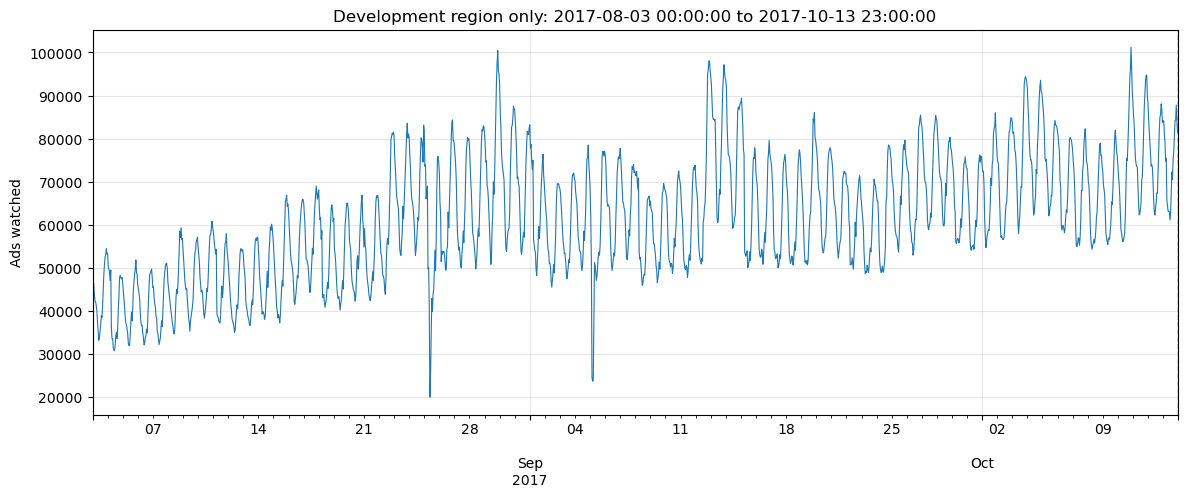

First week 42,664   last development week 71,511   ratio 1.68x


In [8]:
fig, ax = plt.subplots(figsize=(14, 5))
df_dev["y"].plot(ax=ax, lw=0.8)
ax.axvline(DEV_END, color="red", ls="--", lw=1)
ax.set_title(f"Development region only: {df_dev.index.min()} to {DEV_END}")
ax.set_ylabel("Ads watched"); ax.set_xlabel("")
plt.show()

first_wk, last_wk = df_dev["y"].iloc[:24*7].mean(), df_dev["y"].iloc[-24*7:].mean()
print(f"First week {first_wk:,.0f}   last development week {last_wk:,.0f}   ratio {last_wk/first_wk:.2f}x")

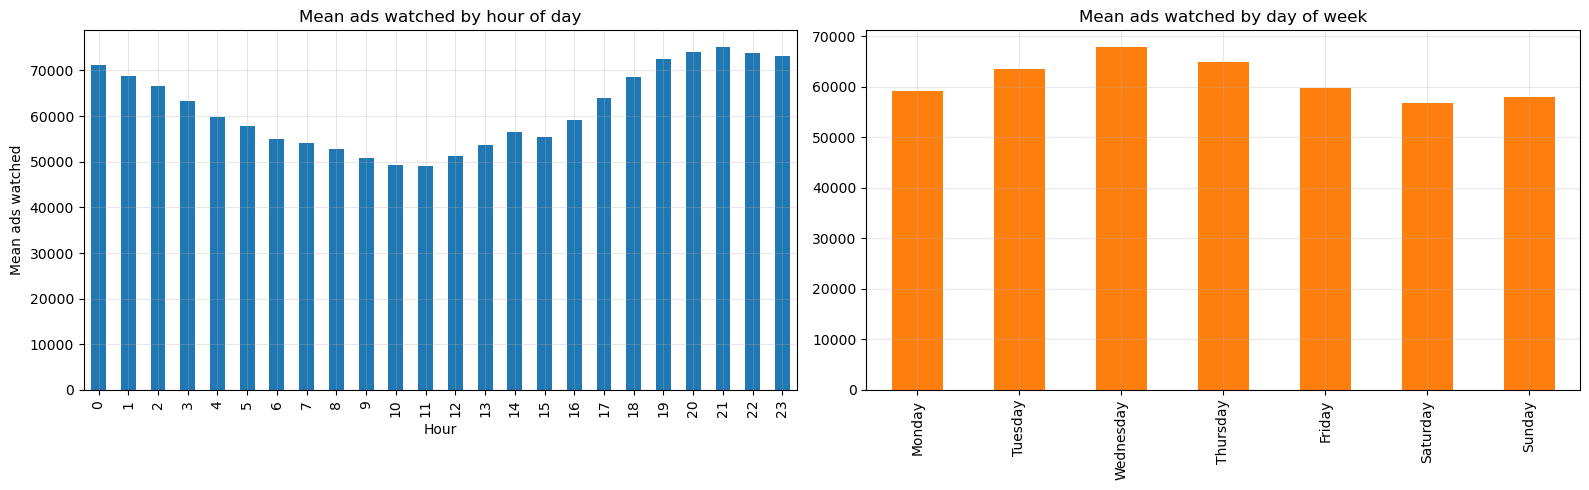

hour-of-day : trough 49,052 (h11)  peak 75,048 (h21)  swing 53%
day-of-week : trough 56,747 (Saturday)  peak 67,810 (Wednesday)  swing 19%
Descriptive development values, not a stationarity or causal seasonal-effect test:


,computed value
development-region start (includes warm-up),2017-08-03 00:00:00
development-region end,2017-10-13 23:00:00
observations,1728
sample mean,61486.884259
sample std,14046.264888
minimum,19986
maximum,101215
first seven-day mean,42664.482143
last seven-day mean,71510.803571
last/first seven-day mean ratio,1.67612


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
hourly = df_dev.groupby(df_dev.index.hour)["y"].mean()
hourly.plot(kind="bar", ax=axes[0], title="Mean ads watched by hour of day")
axes[0].set_xlabel("Hour"); axes[0].set_ylabel("Mean ads watched")
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekday = df_dev.groupby(df_dev.index.day_name())["y"].mean().reindex(order)
weekday.plot(kind="bar", ax=axes[1], color="C1", title="Mean ads watched by day of week")
axes[1].set_xlabel("")
plt.tight_layout(); plt.show()

print(f"hour-of-day : trough {hourly.min():,.0f} (h{hourly.idxmin()})  peak {hourly.max():,.0f} "
      f"(h{hourly.idxmax()})  swing {100*(hourly.max()/hourly.min()-1):.0f}%")
print(f"day-of-week : trough {weekday.min():,.0f} ({weekday.idxmin()})  peak {weekday.max():,.0f} "
      f"({weekday.idxmax()})  swing {100*(weekday.max()/weekday.min()-1):.0f}%")
# Read-only result reporting.
_c_show_development(df_dev, hourly, weekday)


### From calendar profiles to seasonal models

The development hourly profile was lowest near **11:00** and highest near
**21:00**, with the peak about **53%** above the trough. Weekday averages differed
by about **19%** from lowest to highest. These marginal profiles combine
calendar structure with the changing level and sample composition. They give
me reasons to compare seasonal representations, rather than isolated causal
effects of a particular hour or weekday.

I examined the ACF after a 24-hour difference to see what temporal structure
remained. Its value at lag 168 was **0.407**. A separately parameterized weekly
profile was therefore worth investigating, although daily SARIMA can itself
generate dependence at weekly lags. For example, a stationary seasonal AR(1)

$$X_t=\Phi X_{t-24}+\varepsilon_t,\quad |\Phi|<1,$$


Where:

- $X_t$: The value of the time series at time $t$.
- $\Phi$: The seasonal autoregressive coefficient.
- $X_{t-24}$: The value of the time series 24 hours earlier.
- $\varepsilon_t$: The random error or innovation term.

For the stationary solution of this model, the autocorrelation function at lags that are multiples of 24 is given by:

$$
\rho(24k)=\Phi^k
$$

Therefore, at lag 168, corresponding to seven days:

$$
\rho(168)=\Phi^7
$$

This value can be nonzero.

Thus, **observing autocorrelation at a weekly lag does not necessarily imply the presence of a separate weekly seasonal component**, because such dependence may arise solely from the daily autoregressive structure.

Multiplicative SARIMA polynomials also generate cross-lag effects.
A model with `s=24` lacks a separately parameterized day-of-week mean pattern;
Fourier regressors provide one way to add that structure. This series ACF is
distinct from the fitted-model residual diagnostics in Section 6.


<details>
<summary><strong><span style="color:red;">📘 The Autocorrelation Function (ACF) at lag 168 after 24-hour differencing</span></strong></summary>

The ACF at lag 168 after 24-hour differencing measures the correlation between the differenced series at time $t$ and the same differenced series 168 hours earlier.

First, define the 24-hour differenced series:

$$
X_t = y_t - y_{t-24}
$$

Then the mathematical relationship is:

$$
\boxed{
\begin{aligned}
\rho_X(168)
&= \operatorname{Corr}(X_t,X_{t-168})\\[4pt]
&= \operatorname{Corr}\left(
y_t-y_{t-24},\;
y_{t-168}-y_{t-192}
\right)
\end{aligned}
}
$$

The sample estimate of this autocorrelation in the development data was:

$$
\boxed{\hat{\rho}_X(168)=0.407}
$$

### How was 0.407 calculated?

A common sample ACF estimator is:

$$
\hat{\rho}_X(168)
=
\frac{
\displaystyle\sum_{t=169}^{N}
(X_t-\bar X)(X_{t-168}-\bar X)
}{
\displaystyle\sum_{t=1}^{N}
(X_t-\bar X)^2
}
\approx 0.407
$$

where $N$ is the number of observations in the differenced series and $\bar X$ is their mean.

### What does this mean?

The value **0.407** indicates a positive autocorrelation between the 24-hour changes in ads watched and those occurring exactly one week earlier.

For example, if $X_t$ represents the difference between the number of ads watched today at 21:00 and yesterday at 21:00, then $X_{t-168}$ represents the corresponding day-over-day difference one week earlier.

**Important:** The value 0.407 was estimated from the observed development data. It was not mathematically derived from the lag of 168 itself, and it does not necessarily indicate a separate weekly seasonal component.

</details>

### What the stationarity tests contributed

On the raw series, ADF gave **p=0.1122**, while KPSS rejected level stationarity at its lower tabulation boundary. After 24-hour differencing, ADF rejected its unit-root null and KPSS did not reject level stationarity. These results were consistent with investigating a stationary model for the differenced series; neither test proves stationarity.

I used ADF with an intercept and AIC-based lag selection, and KPSS with an intercept and automatic bandwidth selection. Boundary KPSS p-values are bounds, even when warnings are suppressed. The hypotheses are summarized below.

The diagnostics motivated fixing the SARIMA candidates at $d=0$, $D=1$, and $s=24$: no additional nonseasonal difference, one daily seasonal difference. With the backshift operator $By_t=y_{t-1}$,

$$
(1-B^{24})y_t=y_t-y_{t-24},\qquad
1-B^{24}=(1-B)(1+B+\cdots+B^{23}).
$$

The factorization matters: daily differencing includes a zero-frequency unit-root factor as well as seasonal factors. Neither test here is a dedicated seasonal unit-root test, so their changed results do not identify the original source of nonstationarity. Deterministic terms, lag choices, breaks, sample size, and seasonal dependence can affect the diagnostics.

These fixed differencing orders define the candidates evaluated later. The tests do not establish that this choice is necessary, sufficient, or optimal for forecasting.


<details>
<summary><strong><span style="color:red;">📘 Reading ADF and KPSS together</span></strong></summary>

The tests start from different null hypotheses:

| Test | Null hypothesis in this notebook | Interpretation of a small p-value |
|---|---|---|
| ADF (Augmented Dickey–Fuller) | A unit root is present. | Evidence against that unit-root model. |
| KPSS (Kwiatkowski–Phillips–Schmidt–Shin) | The series is stationary around a constant level. | Evidence against level stationarity. |

KPSS can also be configured to test stationarity around a deterministic trend; that is a different specification from the one used here. Failure to reject either null means the evidence was insufficient to reject it under the test assumptions.

</details>


In [10]:
from statsmodels.tsa.stattools import adfuller, kpss, acf

def stationarity_report(series, label):
    adf_p = adfuller(series, autolag="AIC")[1]
    kpss_p = kpss(series, regression="c", nlags="auto")[1]
    verdict = ("ADF does not reject; KPSS rejects" if (adf_p > 0.05 and kpss_p < 0.05) else
               "ADF rejects; KPSS does not reject" if (adf_p < 0.05 and kpss_p > 0.05)
               else "joint result does not settle a simple stationary/unit-root description")
    _f = lambda p: "<0.0001" if p < 1e-4 else f"{p:.4f}"
    print(f"{label:<28s} ADF p={_f(adf_p):>7s} (H0: unit root)   "
          f"KPSS p={_c_kpss_p(kpss_p):>9s} (H0: level-stationary)   -> {verdict}")
    return adf_p, kpss_p

stationarity_report(df_dev["y"], "raw series (dev)")
y_sdiff = df_dev["y"].diff(SEASON).dropna()
stationarity_report(y_sdiff, "after 24h seasonal diff")

raw series (dev)             ADF p= 0.1122 (H0: unit root)   KPSS p= <=0.0100 (H0: level-stationary)   -> ADF does not reject; KPSS rejects
after 24h seasonal diff      ADF p=<0.0001 (H0: unit root)   KPSS p= >=0.1000 (H0: level-stationary)   -> ADF rejects; KPSS does not reject


(1.9698244857644097e-08, 0.1)

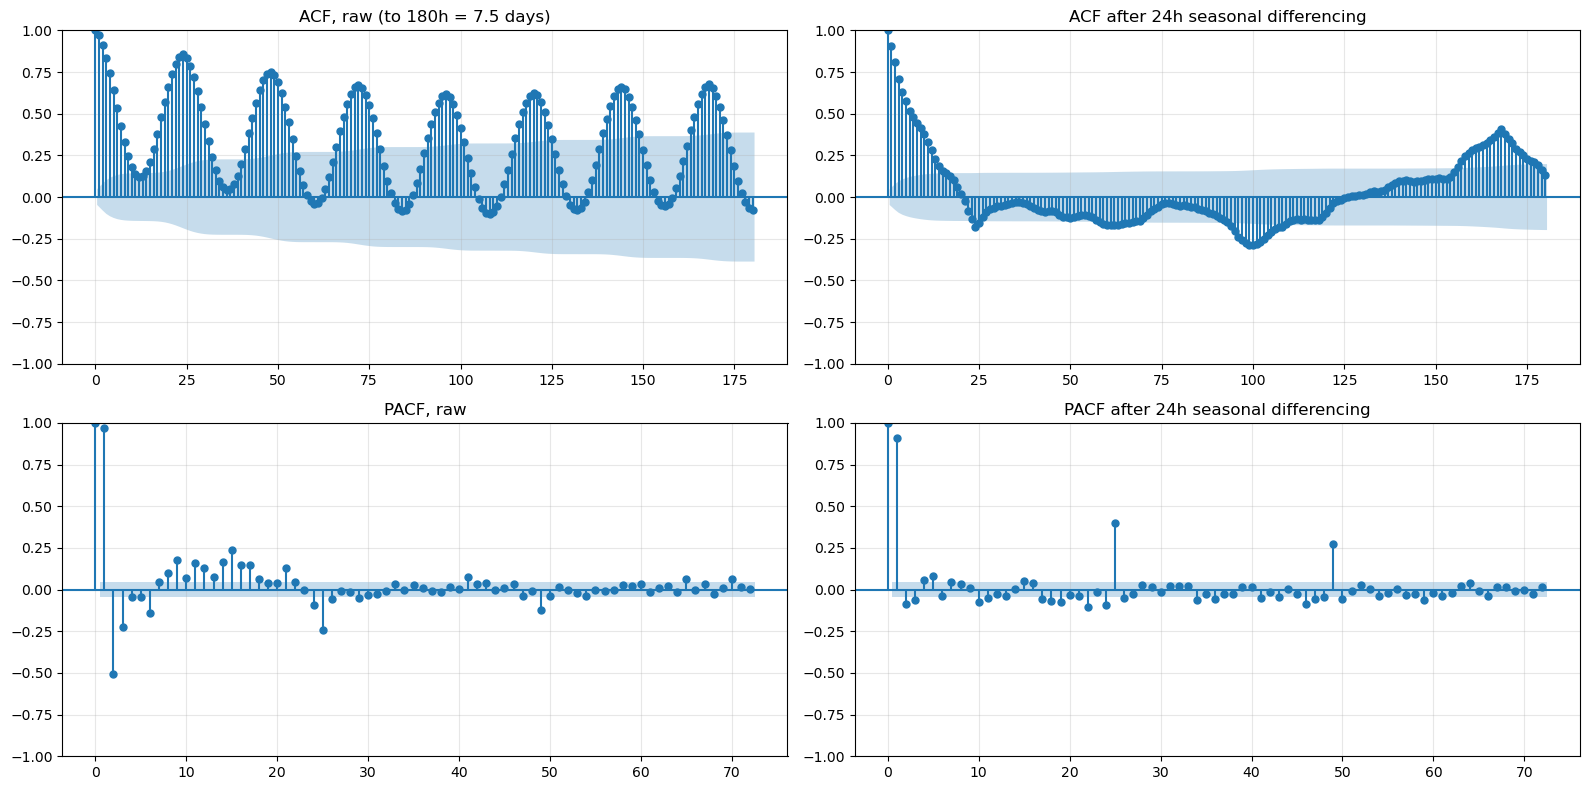

   lag       raw   seas.diff
    24     0.857      -0.181
    48     0.753      -0.119
    72     0.673      -0.086
   168     0.675       0.407

lag 168 = one week. Daily SARIMA can induce dependence there; a distinct weekly profile is a modeling hypothesis.


In [11]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 2, figsize=(16, 8))
plot_acf(df_dev["y"], lags=180, ax=axes[0,0]); axes[0,0].set_title("ACF, raw (to 180h = 7.5 days)")
plot_pacf(df_dev["y"], lags=72, ax=axes[1,0], method="ywm"); axes[1,0].set_title("PACF, raw")
plot_acf(y_sdiff, lags=180, ax=axes[0,1]); axes[0,1].set_title("ACF after 24h seasonal differencing")
plot_pacf(y_sdiff, lags=72, ax=axes[1,1], method="ywm"); axes[1,1].set_title("PACF after 24h seasonal differencing")
plt.tight_layout(); plt.show()

a_raw, a_sd = acf(df_dev["y"], nlags=180), acf(y_sdiff, nlags=180)
print(f"{'lag':>6s}{'raw':>10s}{'seas.diff':>12s}")
for L in (24, 48, 72, 168):
    print(f"{L:>6d}{a_raw[L]:>10.3f}{a_sd[L]:>12.3f}")
print("\nlag 168 = one week. Daily SARIMA can induce dependence there; a distinct weekly profile is a modeling hypothesis.")

### Examining how variability changes with level

I compared daily means, standard deviations, and coefficients of variation (CV) to investigate whether a transformation might stabilize variability. The fitted log-log relationship describes

$$
\operatorname{sd}(Y)\approx C\mu^b,
$$

where $\mu$ is the mean, $C>0$ is a scale constant, and $b$ describes how standard deviation changes with level. Taylor's ecological law is usually expressed for **variance**, $\operatorname{Var}(Y)\approx a\mu^p$, so its corresponding standard-deviation exponent is $b=p/2$.

For positive observations, the Box–Cox family is

$$
g_\lambda(y)=
\begin{cases}
(y^\lambda-1)/\lambda,&\lambda\ne0,\\
\log y,&\lambda=0.
\end{cases}
$$

The parameter $\lambda$ controls the transformation's curvature. A first-order **delta-method** approximation uses its local slope, $g'_\lambda(\mu)=\mu^{\lambda-1}$, to describe the transformed variability:

$$
\operatorname{sd}\{g_\lambda(Y)\}
\approx |g'_\lambda(\mu)|\operatorname{sd}(Y)
\approx C\mu^{\lambda-1+b}.
$$

Setting the exponent to zero gives the heuristic $\boxed{\lambda\approx1-b}$: the transformed standard deviation would then be approximately independent of level.

This argument relies on a useful local mean-variability relationship and an adequate first-order approximation. Daily standard deviations also reflect the intraday cycle and changing level; they do not isolate innovation variance. The regression's displayed OLS interval and p-value are unadjusted for temporal dependence in these estimated daily summaries.

I compared that heuristic with SciPy's Box–Cox profile-likelihood estimate, explained below. Both use the same development observations, with different working assumptions, so they provide motivation for a forecasting comparison rather than independent evidence that transformation is necessary. Their practical value is assessed on original-scale forecast errors in Section 8.


<details>
<summary><strong><span style="color:red;">📘 Box–Cox MLE: density, likelihood, and the Jacobian</span></strong></summary>

The next code cell calls `stats.boxcox(df_dev["y"].to_numpy())` to estimate an exploratory transformation parameter. All counts in this dataset are strictly positive, so the input is **$x_i=y_i$, with no added offset**. Section 8 separately estimates $\lambda$ from each origin's available training history.

### 1. Probability density versus likelihood

The same expression has two interpretations:

$$
L(\theta;x)=f(x\mid\theta).
$$

As a **density**, $\theta$ is fixed and possible observations $x$ vary. As a **likelihood**, the observed $x$ is fixed and candidate parameters $\theta$ vary. Likelihood is not a probability distribution over parameters and need not integrate to one over parameter space.

For example, with one observation $x=5$ and a normal model with known variance 1,

$$
L(\mu;5)=\frac{1}{\sqrt{2\pi}}
\exp\left[-\frac{(5-\mu)^2}{2}\right].
$$

It is maximized at $\hat\mu=5$. This chooses the mean giving the observed value the highest density within the specified model; it does not assign a posterior probability to $\mu$.

### 2. Why the transformation needs a Jacobian

Write $z_i(\lambda)=g_\lambda(x_i)$ using the Box–Cox definition above. SciPy's usual profile criterion uses an iid-normal working model for the transformed observations. Its change-of-variables calculation contains

$$
f_X(x_i\mid\lambda,\mu,\sigma^2)
=f_Z(g_\lambda(x_i)\mid\mu,\sigma^2)
\left|g'_\lambda(x_i)\right|,
\qquad |g'_\lambda(x_i)|=x_i^{\lambda-1}.
$$

The **Jacobian** adjusts density for how the transformation stretches or compresses an interval: corresponding probabilities satisfy $f_X(x)\,dx=f_Z(z)\,|dz|$. Without this adjustment, a transformation could appear preferable simply because it compresses the numerical scale.

For $\lambda\ne0$, the Box–Cox range is restricted, whereas an unrestricted normal distribution has support on the whole real line. The conventional criterion therefore uses a Gaussian working approximation; Section 8 returns to this support issue for inverse forecasts. Temporal dependence is another departure from the iid assumption here.

### 3. From the working likelihood to a one-dimensional objective

Multiplying the Gaussian contributions and Jacobians, then taking logarithms, gives

$$
\begin{aligned}
\ell(\lambda,\mu,\sigma^2)
={}&-\frac n2\log(2\pi\sigma^2)
-\frac{1}{2\sigma^2}\sum_i[z_i(\lambda)-\mu]^2\\
&+(\lambda-1)\sum_i\log x_i.
\end{aligned}
$$

For each fixed $\lambda$, the transformed values are known. The derivatives with respect to $\mu$ and $v=\sigma^2$ are

$$
\frac{\partial\ell}{\partial\mu}
=\frac{1}{v}\sum_i(z_i-\mu),\qquad
\frac{\partial\ell}{\partial v}
=-\frac{n}{2v}+\frac{\sum_i(z_i-\mu)^2}{2v^2}.
$$

Setting them to zero yields

$$
\hat\mu(\lambda)=\bar z(\lambda),\qquad
\hat\sigma^2(\lambda)=\frac1n\sum_i[z_i(\lambda)-\bar z(\lambda)]^2.
$$

For nonconstant observations these maximize the Gaussian criterion at fixed $\lambda$. The variance denominator is $n$, because the objective is maximum likelihood; the unbiased sample-variance estimator with denominator $n-1$ serves a different purpose.

Substituting the estimates leaves the **profile log-likelihood**, up to constants independent of $\lambda$:

$$
\boxed{
\ell_p(\lambda)
=-\frac n2\log\hat\sigma^2(\lambda)
+(\lambda-1)\sum_i\log x_i
}.
$$

This is the criterion calculated by `stats.boxcox_llf`. The first term rewards smaller fitted variance; the second compensates for the change of scale. Together they define the transformation criterion, rather than directly minimizing skewness.

### 4. Numerical optimization and a small example

The estimate is $\hat\lambda=\arg\max_\lambda\ell_p(\lambda)$. Under the default settings used here, SciPy uses Brent's scalar optimization method. It searches continuously, rather than testing only a few named transformations.

For the **synthetic** observations `x = np.array([1, 2, 3, 4, 9, 15])`:

| $\lambda$ | Profile log-likelihood |
|---:|---:|
| -1.00 | -9.1998 |
| 0.00 | -7.4638 |
| 0.25 | -7.6498 |
| 0.50 | -8.0728 |
| 1.00 | -9.5202 |

Continuous optimization gives $\hat\lambda\approx-0.05893$, close to a log transformation. These illustrative values are separate from the ads results.

The following focused example connects the objective to this notebook's actual EDA input:

```python
from scipy import optimize, stats

x = df_dev["y"].to_numpy()  # Strictly positive counts; no offset
result = optimize.minimize_scalar(
    lambda lmbda: -stats.boxcox_llf(lmbda, x),
    bracket=(-2, 2),
    method="brent",
)
transformed_y, lambda_scipy = stats.boxcox(x)
lambda_manual = result.x
```

The two estimates should agree up to numerical tolerances for these data. `stats.boxcox_normmax` instead defaults to a Pearson-correlation criterion; specifying `method="mle"` selects the likelihood criterion. When `lmbda` is omitted, `stats.boxcox` returns both the transformed observations and the fitted parameter.

This estimate characterizes the data under the working criterion. It does not guarantee normality, independence, or improved forecasting accuracy. In the later forecasting experiment, `stats.boxcox(train["y"].to_numpy())` repeats estimation using only the history available at that origin.

</details>


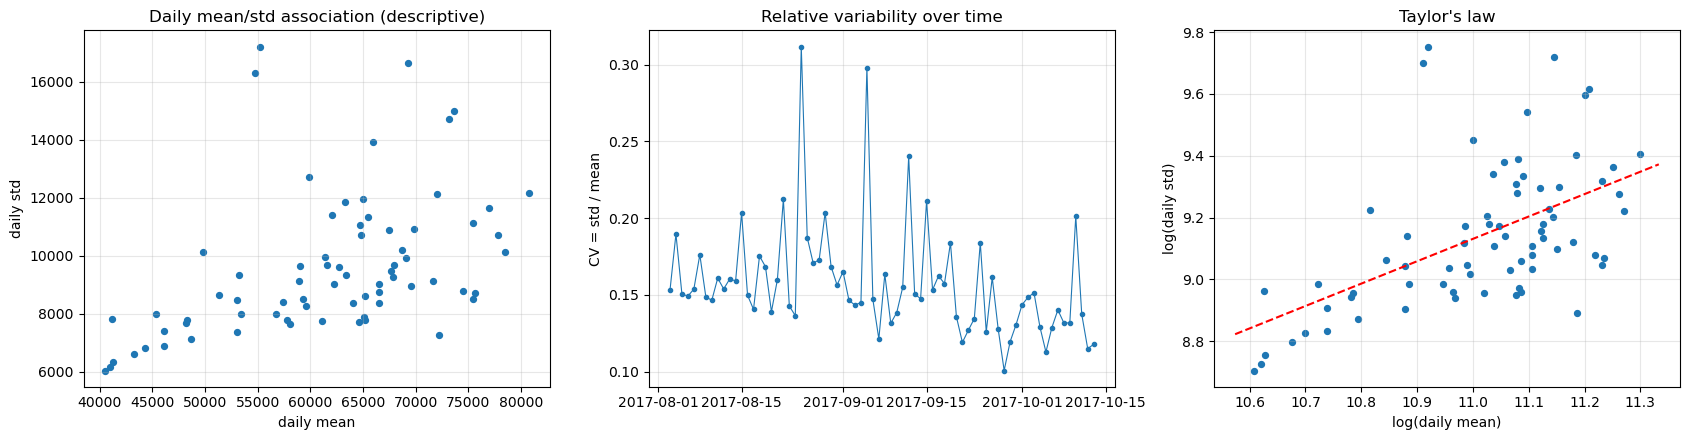

corr(daily mean, daily std) = 0.458   <- trend, composition and seasonal amplitude may contribute
corr(daily mean, daily CV)  = -0.216   <- relative variability vs level
Log-std/log-mean slope b     = 0.724  (naive OLS 95% interval 0.467 .. 0.981, p=5.3e-07)
implied Box-Cox lambda ~ 1-b = 0.276
iid-normal profile Box-Cox lambda = 0.723   <- development region (NOT whole series)


In [12]:
from scipy import stats

daily = df_dev["y"].resample("D").agg(["mean", "std"]).dropna()
daily["cv"] = daily["std"] / daily["mean"]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].scatter(daily["mean"], daily["std"], s=18)
axes[0].set_xlabel("daily mean"); axes[0].set_ylabel("daily std"); axes[0].set_title("Daily mean/std association (descriptive)")
axes[1].plot(daily.index, daily["cv"], marker=".", lw=0.8)
axes[1].set_ylabel("CV = std / mean"); axes[1].set_title("Relative variability over time")
axes[2].scatter(np.log(daily["mean"]), np.log(daily["std"]), s=18)
axes[2].set_xlabel("log(daily mean)"); axes[2].set_ylabel("log(daily std)"); axes[2].set_title("Taylor's law")
b, icept, _r, b_p, b_se = stats.linregress(np.log(daily["mean"]), np.log(daily["std"]))
_x = np.linspace(*axes[2].get_xlim(), 50); axes[2].plot(_x, icept + b*_x, "r--")
plt.tight_layout(); plt.show()

_, LAMBDA_MLE_DEV = stats.boxcox(df_dev["y"].to_numpy())      # development region only
print(f"corr(daily mean, daily std) = {daily['mean'].corr(daily['std']):.3f}   <- trend, composition and seasonal amplitude may contribute")
print(f"corr(daily mean, daily CV)  = {daily['mean'].corr(daily['cv']):.3f}   <- relative variability vs level")
print(f"Log-std/log-mean slope b     = {b:.3f}  (naive OLS 95% interval {b-1.96*b_se:.3f} .. {b+1.96*b_se:.3f}, p={b_p:.2g})")
print(f"implied Box-Cox lambda ~ 1-b = {1-b:.3f}")
print(f"iid-normal profile Box-Cox lambda = {LAMBDA_MLE_DEV:.3f}   <- development region (NOT whole series)")

The daily mean–standard-deviation correlation was **0.458**, and the fitted log-log slope was **0.724**. Its naive OLS 95% interval, unadjusted for temporal dependence, was **[0.467, 0.981]**. The heuristic therefore gave $\lambda\approx1-0.724=0.276$, compared with **0.723** from the iid-Gaussian profile criterion. I used this disagreement to motivate the original-scale forecasting comparison in Section 8.

### Investigating the sharp drops

I fitted **robust STL** (Seasonal-Trend Decomposition using LOESS) to development data with period 24. It separates the fitted daily pattern and trend from residual variation. Weekly effects, breaks, and other unmodeled changes can remain in those residuals; a large residual alone does not establish a measurement error.

The code scores each residual $R_t$ after centering it at the residual median:

$$
z_t^{\mathrm{robust}}=
\frac{R_t-\operatorname{median}(R)}{1.4826\operatorname{MAD}},
\qquad
\operatorname{MAD}=\operatorname{median}|R_t-\operatorname{median}(R)|.
$$

The factor 1.4826 makes scaled MAD consistent for standard deviation under normal sampling. These scores are descriptive robust scales, without calibrated Gaussian tail probabilities. I displayed several cutoffs; a threshold of **15** flagged **seven hours across August 25 and September 5, 2017**. Two dates do not establish two independent events.

STL and the subsequent interpolation use information from the full development region, including observations unavailable at some early forecast origins. I therefore use the replacements only for an **ex post sensitivity analysis**. The primary comparison retains the original training observations and targets.


<details>
<summary><strong><span style="color:red;">📘 STL and ex post sensitivity analysis</span></strong></summary>

STL decomposes an observed series as

$$Y_t=T_t+S_t+R_t,$$

where $T_t$ is trend, $S_t$ seasonality, and $R_t$ the remaining variation. **LOESS** (Locally Estimated Scatterplot Smoothing) fits locally weighted regressions to estimate smooth components. With `robust=True`, STL reduces the influence of large residuals during fitting.

STL is a decomposition method; forecasting requires an additional extrapolation rule. A retrospective decomposition can use later observations to estimate an earlier trend or seasonal component.

An **ex post sensitivity analysis** asks how results change when an already-observed dataset is handled differently. Here, replacing flagged hours helps assess their influence. A real-time cleaning procedure would additionally need to identify and replace them using only information available at each origin. That prospective procedure was not tested.

</details>


Hours flagged at each threshold (the cut-off is a judgement call, so make it visible):
  |z| > 4   :  147 hours
  |z| > 6   :   67 hours
  |z| > 8   :   33 hours
  |z| > 10  :   15 hours
  |z| > 15  :    7 hours
  |z| > 20  :    4 hours

These are retrospective robust residual scores, not calibrated Gaussian sigma tests.
A threshold flag does not establish a data error or identify an event mechanism.

At |z| > 15: 7 hours in 2 distinct flagged dates
  2017-08-25 09:00:00   y =   19,986   z = -23.6
  2017-08-25 10:00:00   y =   24,640   z = -18.2
  2017-08-25 18:00:00   y =   49,313   z = -15.8
  2017-09-05 03:00:00   y =   24,513   z = -30.1
  2017-09-05 04:00:00   y =   23,731   z = -28.7
  2017-09-05 05:00:00   y =   23,745   z = -27.4
  2017-09-05 06:00:00   y =   38,109   z = -16.3


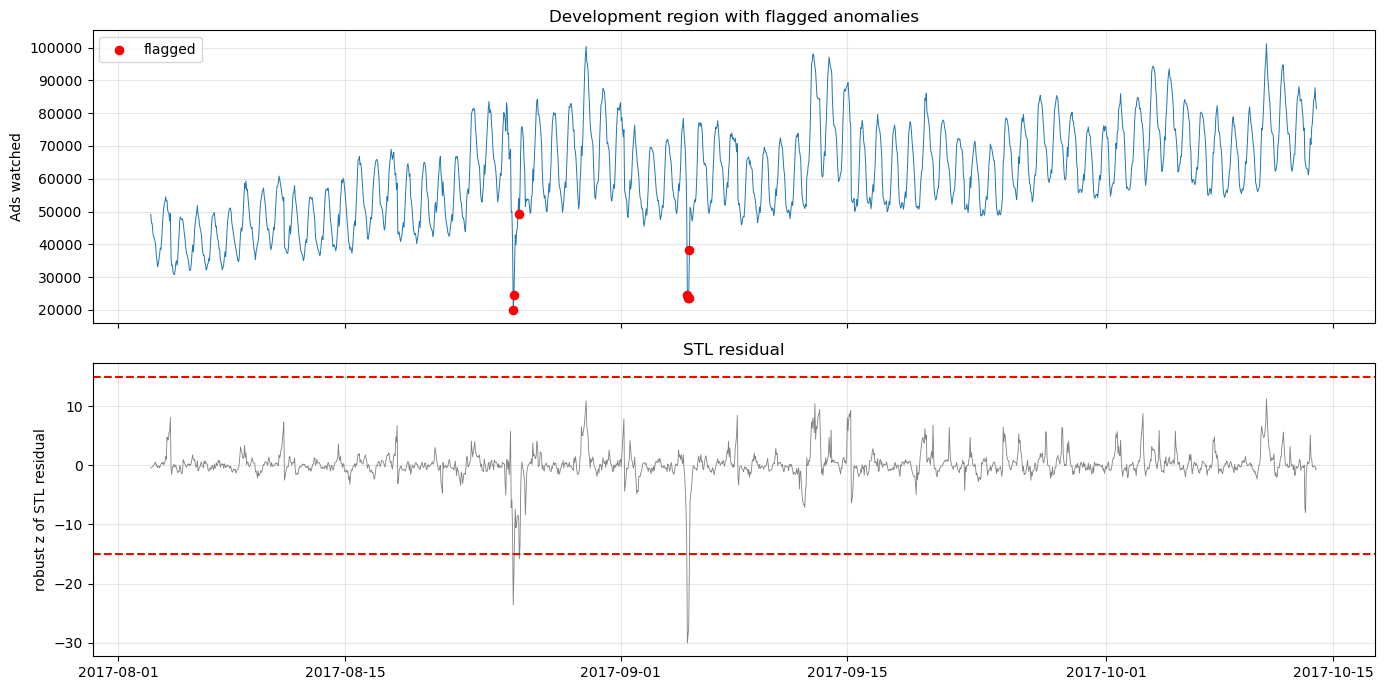

In [13]:
from statsmodels.tsa.seasonal import STL

stl = STL(df_dev["y"], period=SEASON, robust=True).fit()
resid = stl.resid
mad = np.median(np.abs(resid - resid.median()))
robust_z = (resid - resid.median()) / (1.4826 * mad)

print("Hours flagged at each threshold (the cut-off is a judgement call, so make it visible):")
for thr in (4, 6, 8, 10, 15, 20):
    print(f"  |z| > {thr:<3d} : {int((np.abs(robust_z) > thr).sum()):>4d} hours")
print("\nThese are retrospective robust residual scores, not calibrated Gaussian sigma tests.")
print("A threshold flag does not establish a data error or identify an event mechanism.")

ANOMALY_Z = 15
anomalies = df_dev.index[np.abs(robust_z) > ANOMALY_Z]
print(f"\nAt |z| > {ANOMALY_Z}: {len(anomalies)} hours in "
      f"{len(pd.Series(anomalies.date).unique())} distinct flagged dates")
for ts in anomalies:
    print(f"  {ts}   y = {df_dev.loc[ts,'y']:>8,.0f}   z = {robust_z.loc[ts]:+.1f}")

df_clean = df.copy()                       # cleaning is applied to the full frame for Section 4,
df_clean.loc[anomalies, "y"] = np.nan      # but the anomalies were IDENTIFIED on development only
df_clean["y"] = df_clean["y"].interpolate("time")

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(df_dev.index, df_dev["y"], lw=0.7, color="C0")
axes[0].scatter(anomalies, df_dev.loc[anomalies, "y"], color="red", s=35, zorder=5, label="flagged")
axes[0].set_ylabel("Ads watched"); axes[0].legend(); axes[0].set_title("Development region with flagged anomalies")
axes[1].plot(df_dev.index, robust_z, lw=0.6, color="gray")
axes[1].axhline(ANOMALY_Z, color="red", ls="--"); axes[1].axhline(-ANOMALY_Z, color="red", ls="--")
axes[1].set_ylabel("robust z of STL residual"); axes[1].set_title("STL residual")
plt.tight_layout(); plt.show()

## Section 4: Benchmarks and Retrospective Anomaly Sensitivity

I used last-value naive as a simple level reference and **24-hour seasonal naive**
as the primary benchmark. The latter repeats the last observed daily cycle
through the two-day horizon. Given the visible intraday pattern, it asks a
candidate to improve on an existing seasonal forecast rather than merely
rediscover that hours differ.

Their mean development MASEs were **3.130** and **1.393**, respectively. That
gap makes the choice of reference consequential: improving on last-value naive
can still leave a procedure behind seasonal naive. The benchmark is a concrete
comparison for this task, not a universal boundary between skill and no skill.


<details>
<summary><strong><span style="color:red">📘 Understanding the Difference Between the Two Naive Forecasting Methods:</span></strong></summary>

#### 1. Last-Value Naive

This method assumes that **all future observations will equal the most recently observed value**.

$$
\hat{y}_{T+h}=y_T
$$

where $T$ is the last observed time and $h$ is the forecast horizon.

For example, if the latest recorded value is 50,000, the model predicts **50,000 for every hour of the next 48 hours**.

#### 2. 24-Hour Seasonal Naive

This method assumes that **the pattern observed over the previous 24 hours will repeat over the next two days**.

$$
\hat{y}_{T+h}
=
y_{T+h-24\lceil h/24\rceil},
\qquad h=1,\ldots,48
$$

where $\lceil h/24\rceil$ is the ceiling function, which rounds $h/24$ up to the nearest integer.

Instead of predicting a constant value, the model repeats the hourly fluctuations observed during the previous day.

</details>


In [14]:
def naive_last_value(train, val_dates):
    return np.full(len(val_dates), train["y"].iloc[-1])

def seasonal_naive(train, val_dates, season=SEASON):
    last = train["y"].iloc[-season:].to_numpy()
    return np.tile(last, int(np.ceil(len(val_dates) / season)))[:len(val_dates)]

run_harness(naive_last_value, "Naive (last value)")
run_harness(seasonal_naive, BENCHMARK)
compare("Naive (last value)", BENCHMARK).describe().loc[["mean", "50%", "min", "max"]].round(3)

Naive (last value)                           29 folds   mean MASE 3.130   [0.0s]
Seasonal naive (24h)                         29 folds   mean MASE 1.393   [0.0s]


model,Naive (last value),Seasonal naive (24h)
mean,3.130,1.393
50%,3.026,1.138
min,1.906,0.488
max,6.973,3.564


### How much did the flagged hours affect the benchmarks?

I compared forecasts fitted to original histories with forecasts fitted after interpolating the flagged hours. Both were scored against the **same original targets**, so only the training-history treatment changed.

Seasonal naive uses the latest daily cycle; the hour-of-day mean averages each hour across the available history. Their different reliance on recent observations makes this a useful sensitivity contrast.

The flags and replacement values use full-development information. These scores describe the influence of replacing the observations, whose causes remain unresolved. They do not evaluate an origin-by-origin cleaning procedure. All primary model comparisons use the original histories.


In [15]:
def hour_of_day_mean(train, val_dates):
    return train["y"].groupby(train.index.hour).mean().reindex(val_dates.hour).to_numpy()

def _mae_on(frame, fn, folds=DEV_FOLDS):
    out = []
    for _, r in folds.iterrows():
        tr = frame.loc[frame.index < r["validation_start"]]
        vd = pd.date_range(r["validation_start"], r["validation_end"], freq="h")
        out.append(mean_absolute_error(df.loc[vd, "y"].to_numpy(), fn(tr, vd)))
    return np.array(out)

sens = pd.DataFrame(index=[f"fold_{i}" for i in DEV_FOLDS["fold"]])
for label, fn in [("seasonal_naive", seasonal_naive), ("hour_of_day_mean", hour_of_day_mean)]:
    a, b = _mae_on(df, fn), _mae_on(df_clean, fn)
    sens[f"{label}_raw"], sens[f"{label}_clean"] = a.round(0), b.round(0)
    sens[f"{label}_chg%"] = (100 * (b / a - 1)).round(2)
sens["anomalies_in_train"] = [int((anomalies < s).sum()) for s in DEV_FOLDS["validation_start"]]

print("Retrospective raw/interpolated-history sensitivity; not origin-available cleaning:\n")
print(sens[[c for c in sens.columns if c.endswith("chg%")] + ["anomalies_in_train"]]
      .describe().loc[["mean", "min", "max"]].round(3).to_string())
print(f"\nfolds where seasonal-naive changed at all : "
      f"{int((sens['seasonal_naive_chg%'].abs() > 0.005).sum())} of {len(sens)}")
print(f"largest change for the full-history model : {sens['hour_of_day_mean_chg%'].abs().max():.2f}%")

Retrospective raw/interpolated-history sensitivity; not origin-available cleaning:

      seasonal_naive_chg%  hour_of_day_mean_chg%  anomalies_in_train
mean               -1.281                 -0.861               5.103
min               -37.160                 -3.820               0.000
max                 0.000                  0.000               7.000

folds where seasonal-naive changed at all : 1 of 29
largest change for the full-history model : 3.82%


Replacing flagged hours changed seasonal-naive forecasts in **one of 29 development folds**, reducing that fold's MAE by **37.160%**. For the hour-of-day mean, the largest absolute percentage change in MAE was **3.82%**. A small average effect can therefore conceal substantial sensitivity on a particular forecast occasion. I retained the original observations for the primary comparison.

## Section 5: Classical Smoothing

I compared ways to extrapolate the changing level and daily cycle. The 24-hour moving average produces a flat forecast; the recursive weighted average can evolve toward a stable level. Exponential smoothing then adds explicit state updates: SES estimates level, Holt adds trend, and additive Holt-Winters adds daily seasonality. The table and optional equations below show those distinctions before the common 48-hour evaluation.


### Understanding the Differences Between SES, Holt, and Holt-Winters

All three methods belong to the **Exponential Smoothing** family, but they differ in the components they explicitly model.

| Method | Level | Trend | Seasonality |
|---|:---:|:---:|:---:|
| **SES** | ✓ | — | — |
| **Holt** | ✓ | ✓ | — |
| **Additive Holt-Winters** | ✓ | ✓ | ✓ |

In this project, the number of ads watched exhibited both a changing level and a visible daily seasonal pattern.

Comparing these methods therefore helped me investigate whether explicitly incorporating trend and daily seasonality improved forecasting accuracy over the **48-hour horizon**.

However, **greater model complexity does not necessarily guarantee better forecasting performance**. The observed errors on the common development targets determine which methods performed better in this study.



<details>
<summary><strong><span style="color:red">📘 Mathematical Formulations: SES, Holt, and Holt-Winters</span></strong></summary>

All three methods belong to the **Exponential Smoothing** family, but they differ in the components they explicitly model.

### 1. Simple Exponential Smoothing (SES)

SES models only the **level** of a time series, without explicitly modeling trend or seasonality.

**Level update:**

$$
\boxed{
\ell_t=\alpha y_t+(1-\alpha)\ell_{t-1}
}
$$

**Forecast equation:**

$$
\boxed{
\hat{y}_{T+h}=\ell_T
}
$$

Where:

- $y_t$: Observed value at time $t$.
- $\ell_t$: Estimated level at time $t$.
- $\alpha$: Level smoothing parameter, with $0\leq\alpha\leq1$.
- $T$: Last observed time.
- $h$: Number of forecast steps ahead.

**Key idea:** SES produces a flat forecast because all future predictions equal the latest estimated level.

### 2. Holt's Linear Trend Method

Holt extends SES by adding a **trend** component.

**Level update:**

$$
\boxed{
\ell_t=\alpha y_t+(1-\alpha)(\ell_{t-1}+b_{t-1})
}
$$

**Trend update:**

$$
\boxed{
b_t=\beta(\ell_t-\ell_{t-1})+(1-\beta)b_{t-1}
}
$$

**Forecast equation:**

$$
\boxed{
\hat{y}_{T+h}=\ell_T+hb_T
}
$$

Where:

- $\ell_t$: Estimated level at time $t$.
- $b_t$: Estimated trend at time $t$.
- $\alpha$: Level smoothing parameter.
- $\beta$: Trend smoothing parameter.
- $h$: Number of forecast steps ahead.

Both smoothing parameters lie between 0 and 1.

**Key idea:** Unlike SES, Holt allows forecasts to increase or decrease over time by extrapolating the estimated trend.

### 3. Additive Holt-Winters Method

Holt-Winters extends Holt by including a **seasonal component**.

For additive trend and seasonality:

**Level update:**

$$
\boxed{
\ell_t=
\alpha(y_t-s_{t-m})
+(1-\alpha)(\ell_{t-1}+b_{t-1})
}
$$

**Trend update:**

$$
\boxed{
b_t=
\beta(\ell_t-\ell_{t-1})
+(1-\beta)b_{t-1}
}
$$

**Seasonal update:**

$$
\boxed{
s_t=
\gamma(y_t-\ell_t)
+(1-\gamma)s_{t-m}
}
$$

**Forecast equation:**

$$
\boxed{
\hat{y}_{T+h}
=
\ell_T+hb_T+
s_{T-m+1+((h-1)\bmod m)}
}
$$

Where:

- $\ell_t$: Estimated level at time $t$.
- $b_t$: Estimated trend at time $t$.
- $s_t$: Estimated seasonal component at time $t$.
- $m$: Seasonal period (**24 hours** in this study).
- $\alpha$: Level smoothing parameter.
- $\beta$: Trend smoothing parameter.
- $\gamma$: Seasonal smoothing parameter.
- $h$: Number of forecast steps ahead.

The smoothing parameters $\alpha$, $\beta$, and $\gamma$ lie between 0 and 1.

**Key idea:** Additive Holt-Winters can forecast a changing level, an ongoing trend, and a repeating daily seasonal pattern simultaneously.

These are standard undamped formulations; related implementations can use different parameterizations. The additive seasonal update shown here uses the current level.

</details>


In [16]:
def moving_average(train, val_dates, window=24):
    return np.full(len(val_dates), train["y"].iloc[-window:].mean())

def weighted_moving_average(train, val_dates, weights=(0.05, 0.05, 0.1, 0.1, 0.2, 0.5)):
    w = np.asarray(weights, dtype=float); w /= w.sum(); k = len(w)
    hist = list(train["y"].iloc[-k:].to_numpy()); out = []
    for _ in range(len(val_dates)):
        nxt = float(np.dot(w, hist[-k:])); out.append(nxt); hist.append(nxt)
    return np.array(out)

from scipy.optimize import minimize

def _ses_level(series, alpha):
    lvl = series[0]
    for v in series[1:]:
        lvl = alpha * v + (1 - alpha) * lvl
    return lvl

def simple_exp_smoothing(train, val_dates):
    s = train["y"].to_numpy()
    def loss(p):
        a = p[0]
        if not 0 < a < 1: return 1e18
        lvl, se = s[0], 0.0
        for v in s[1:]:
            se += (v - lvl) ** 2; lvl = a * v + (1 - a) * lvl
        return se
    a = float(np.clip(minimize(loss, [0.3], method="Nelder-Mead").x[0], 0.01, 0.99))
    return np.full(len(val_dates), _ses_level(s, a))

def holt_linear(train, val_dates):
    s = train["y"].to_numpy()
    def loss(p):
        a, b = p
        if not (0 < a < 1 and 0 < b < 1): return 1e18
        lvl, tr_, se = s[0], s[1] - s[0], 0.0
        for v in s[1:]:
            se += (v - (lvl + tr_)) ** 2
            nl = a * v + (1 - a) * (lvl + tr_); tr_ = b * (nl - lvl) + (1 - b) * tr_; lvl = nl
        return se
    a, b = np.clip(minimize(loss, [0.3, 0.1], method="Nelder-Mead").x, 0.01, 0.99)
    lvl, tr_ = s[0], s[1] - s[0]
    for v in s[1:]:
        nl = a * v + (1 - a) * (lvl + tr_); tr_ = b * (nl - lvl) + (1 - b) * tr_; lvl = nl
    return np.array([lvl + (h + 1) * tr_ for h in range(len(val_dates))])

for fn, nm in [(moving_average, "Moving average (24h)"), (weighted_moving_average, "Weighted moving average"),
               (simple_exp_smoothing, "Simple exponential smoothing"), (holt_linear, "Holt (double exp.)")]:
    run_harness(fn, nm)
compare(BENCHMARK, "Moving average (24h)", "Weighted moving average",
        "Simple exponential smoothing", "Holt (double exp.)").mean().round(3).to_frame("mean MASE")

Moving average (24h)                         29 folds   mean MASE 2.245   [0.0s]
Weighted moving average                      29 folds   mean MASE 3.167   [0.0s]
Simple exponential smoothing                 29 folds   mean MASE 3.131   [0.9s]
Holt (double exp.)                           29 folds   mean MASE 6.210   [3.3s]


,mean MASE
model,
Holt (double exp.),6.210
Moving average (24h),2.245
Seasonal naive (24h),1.393
Simple exponential smoothing,3.131
Weighted moving average,3.167


### Performance of the simple smoothing methods

All four methods had higher mean development MASE than seasonal naive:

| Forecasting method | Mean development MASE |
|---|---:|
| **24-hour seasonal naive** | **1.393330** |
| 24-hour moving average | 2.244728 |
| Weighted moving average | 3.167361 |
| SES | 3.130770 |
| Holt | 6.210427 |

Repeating the latest daily cycle was a stronger reference than extrapolating level or trend alone on these targets. I retained the unsuccessful fits to show that comparison.

SES and last-value naive produced similar losses here, although their algorithms differ: SES recursively smooths the level, while naive uses the latest observation directly. The later Model Confidence Set preserves separate names even when observed loss vectors coincide.

### Adding daily seasonality with Holt-Winters

For additive Holt-Winters, I tuned the smoothing coefficients on **three inner 48-hour blocks**, using a coarse grid followed by bounded local refinement. I then refitted at each outer origin. SES and Holt instead fitted their coefficients by minimizing training one-step squared errors. The outer comparison evaluates these complete procedures, including their different estimation rules, on common targets.

I also retained the **Brutlag-style deviation bands** for Section 12. They use smoothed absolute deviations around the fitted values as a heuristic uncertainty scale. They are not established multi-step forecast standard deviations; empirical coverage and interval scores assess their usefulness.


In [17]:
def _initial_trend(s, slen):
    return sum((s[i + slen] - s[i]) / slen for i in range(slen)) / slen

def _initial_seasonals(s, slen):
    n = len(s) // slen
    avg = [np.mean(s[slen * j: slen * (j + 1)]) for j in range(n)]
    return {i: float(np.mean([s[slen * j + i] - avg[j] for j in range(n)])) for i in range(slen)}

class HoltWinters:
    """Additive triple exponential smoothing with Brutlag-style deviation bands."""
    def __init__(self, series, slen, alpha, beta, gamma, n_preds, scaling_factor=2.56):
        self.series = np.asarray(series, dtype=float)
        self.slen, self.n_preds, self.scaling_factor = slen, n_preds, scaling_factor
        self.alpha, self.beta, self.gamma = alpha, beta, gamma

    def fit(self):
        res, dev = [], []
        seas = _initial_seasonals(self.series, self.slen)
        smooth = trend = None
        for i in range(len(self.series) + self.n_preds):
            if i == 0:
                smooth, trend = self.series[0], _initial_trend(self.series, self.slen)
                res.append(self.series[0]); dev.append(0.0)
            elif i >= len(self.series):
                m = i - len(self.series) + 1
                res.append(smooth + m * trend + seas[i % self.slen])
                dev.append(dev[-1] * 1.01)
            else:
                v, last = self.series[i], smooth
                smooth = self.alpha * (v - seas[i % self.slen]) + (1 - self.alpha) * (smooth + trend)
                trend = self.beta * (smooth - last) + (1 - self.beta) * trend
                seas[i % self.slen] = self.gamma * (v - smooth) + (1 - self.gamma) * seas[i % self.slen]
                res.append(smooth + trend + seas[i % self.slen])
                dev.append(self.gamma * abs(v - res[i]) + (1 - self.gamma) * dev[-1])
        self.result = np.array(res); self.deviation = np.array(dev)
        self.upper = self.result + self.scaling_factor * self.deviation
        self.lower = self.result - self.scaling_factor * self.deviation
        return self

def hw_cv_score(params, series, slen=SEASON, horizon=HORIZON, n_origins=3):
    a, b, g = params
    if not all(0.0 < v < 1.0 for v in (a, b, g)): return 1e18
    errs = []
    for k in range(n_origins, 0, -1):
        cut = len(series) - k * horizon
        if cut < 3 * slen: continue
        m = HoltWinters(series[:cut], slen, a, b, g, n_preds=horizon).fit()
        errs.append(np.mean(np.abs(series[cut:cut + horizon] - m.result[-horizon:])))
    return float(np.mean(errs)) if errs else 1e18

_A = _G = [0.02, 0.1, 0.3, 0.5, 0.7, 0.9]
_B = [0.01, 0.05, 0.2, 0.5]

def tune_holt_winters(series, slen=SEASON, horizon=HORIZON, n_origins=3):
    best_v, best_p = np.inf, None
    for p in itertools.product(_A, _B, _G):
        v = hw_cv_score(p, series, slen, horizon, n_origins)
        if v < best_v: best_v, best_p = v, p
    opt = minimize(hw_cv_score, x0=list(best_p), args=(series, slen, horizon, n_origins),
                   method="Nelder-Mead", bounds=[(0.01, 0.99)] * 3,
                   options={"maxiter": 120, "xatol": 0.01, "fatol": 1e-3})
    return np.clip(opt.x, 0.01, 0.99) if opt.fun < best_v else np.array(best_p)

def holt_winters(train, val_dates, slen=SEASON):
    s = train["y"].to_numpy()
    a, b, g = tune_holt_winters(s, slen=slen, horizon=len(val_dates))
    return HoltWinters(s, slen, a, b, g, n_preds=len(val_dates)).fit().result[-len(val_dates):]

run_harness(holt_winters, "Holt-Winters")
compare(BENCHMARK, "Holt-Winters").describe().loc[["mean", "50%", "max"]].round(3)

Holt-Winters                                 29 folds   mean MASE 1.638   [33.5s]


model,Holt-Winters,Seasonal naive (24h)
mean,1.638,1.393
50%,1.309,1.138
max,5.066,3.564


### Holt-Winters performance

| Development-fold summary | MASE |
|---|---:|
| Mean | 1.637500 |
| Median | 1.309489 |
| Maximum displayed | 5.066 |

Holt-Winters remained worse than seasonal naive by mean MASE and had some large fold errors. The spread makes those occasions worth examining, but these summaries do not explain their causes. Comparing its median with another model's mean would also fail to establish a typical paired advantage; that requires the fold-level losses.

## Section 6: SARIMA Search and Residual Diagnostics

I next investigated **SARIMA** (Seasonal Autoregressive Integrated Moving Average) models, fixing $d=0$, $D=1$, and $s=24$ as motivated by the daily pattern and differencing diagnostics. At each forecast origin, I searched the specified AR and MA orders using that origin's training history.

### A common likelihood sample for AIC

Different SARIMA orders can exclude different initial observations from their likelihood calculation. Before fitting any candidates in a search, I set a **common likelihood burn-in** to the maximum required by that search. Candidates then calculate likelihood over the same time observations.

The Akaike Information Criterion is

$$\mathrm{AIC}=-2\ell(\hat\theta)+2k,$$

where $\ell(\hat\theta)$ is the fitted log-likelihood and $k$ the parameter count used by AIC. The $2k$ term penalizes additional parameters. AIC selects within each training search; outer MASE evaluates the resulting 48-hour forecasts. Those criteria need not favor the same procedure.

### Numerical eligibility

Eligible fits must converge, return finite quantities, and use the intended effective likelihood sample. The implementation records failures and sample sizes despite suppressing warnings. It uses a fixed recovery policy and raises an error if every candidate is ineligible. Stationarity and invertibility constraints are not enforced.

The primary optimizer is L-BFGS. A finite but nonconvergent fit can receive one Powell continuation from its fitted parameters. Both optimize the same likelihood; forecast scores do not determine this recovery step. A convergence flag records a stopping condition rather than a guarantee of precise or global optimality. Section 8 documents the resulting numerical limitation.

### What the residual diagnostics test

I examined a deeper fit to the development history using the **Ljung–Box statistic**:

$$
Q_m=n(n+2)\sum_{k=1}^{m}\frac{\hat r_k^2}{n-k}.
$$

Here, $n$ is the residual count after removing burn-in, $\hat r_k$ is residual autocorrelation at lag $k$, and $m$ is the maximum included lag. The null is $\rho_1=\cdots=\rho_m=0$; the alternative is at least one nonzero autocorrelation in that range. A test through lag 168 is therefore a joint test of lags 1–168, not a test of weekly correlation alone.

The code uses the approximate reference

$$
Q_m\overset{\mathrm{approx.}}{\sim}
\chi^2_{m-\mathrm{model\_df}},\qquad
\mathrm{model\_df}=\mathrm{len(params)}-1,
$$

excluding the variance parameter from the coefficient count. Conventional ARMA adjustments use estimated AR and MA orders. Counting every fitted coefficient, particularly Fourier regressors, is a broader diagnostic convention with uncertain calibration here. Model selection, integration, and limited samples further complicate the approximation.

For fixed positive $Q_m$, reducing reference degrees of freedom reduces the upper-tail p-value. Omitting an otherwise appropriate adjustment would therefore tend to be more conservative. This directional fact does not validate the particular adjustment used here.

I interpret rejection as evidence of remaining residual dependence under this convention. It does not identify the missing structure or establish which modification would improve 48-hour forecasts. The next tutorial connects model assumptions, likelihood fitting, and AIC selection.


<details>
<summary><strong><span style="color:red">📘 From a model equation to likelihood, Kalman filtering, and AIC</span></strong></summary>

### 1. Add probability assumptions to the equation

Consider an AR(1) model:

$$
y_t=\phi y_{t-1}+\varepsilon_t,\qquad
\varepsilon_t\overset{\mathrm{iid}}{\sim}N(0,\sigma^2).
$$

The equation describes lag dependence; the innovation assumption supplies a probability distribution. With innovations independent of the past,

$$
y_t\mid y_{t-1};\phi,\sigma^2\sim N(\phi y_{t-1},\sigma^2).
$$

The corresponding conditional density is

$$
f(y_t\mid y_{t-1};\phi,\sigma^2)
=\frac1{\sqrt{2\pi\sigma^2}}
\exp\left[-\frac{(y_t-\phi y_{t-1})^2}{2\sigma^2}\right].
$$

The Box–Cox tutorial explained density versus likelihood. Here the same distinction applies: observed $y_1,\ldots,y_n$ are fixed while candidate $(\phi,\sigma^2)$ values vary.

### 2. Construct and maximize the conditional likelihood

Conditional on $y_1$, multiply the sequential densities:

$$
L(\phi,\sigma^2;y_2,\ldots,y_n\mid y_1)
=\prod_{t=2}^{n}f(y_t\mid y_{t-1};\phi,\sigma^2).
$$

Taking logarithms gives

$$
\ell(\phi,\sigma^2)
=-\frac{n-1}{2}\log(2\pi\sigma^2)
-\frac1{2\sigma^2}\sum_{t=2}^{n}(y_t-\phi y_{t-1})^2.
$$

This shows why Gaussian fitting is connected to squared one-step errors. The **conditional** likelihood omits the density of $y_1$; a full likelihood also needs an initial distribution.

Maximum likelihood chooses parameters maximizing $\ell$. Since logarithms preserve ordering, this is equivalent to maximizing $L$, or minimizing $-\ell$. It finds the best fit within the specified probability model without verifying its assumptions.

### 3. Extend the calculation to SARIMA

SARIMA adds seasonal and nonseasonal AR/MA terms and differencing. For example, $D=1$, $s=24$ models dynamics after applying $y_t-y_{t-24}$. MA terms involve unobserved innovations, so evaluating the likelihood requires more than substituting observed lags into the AR(1) density.

The state-space implementation in `statsmodels` SARIMAX uses the **Kalman filter**. For each proposed parameter vector $\theta$, it computes the one-step forecast innovation and its variance:

$$
v_t(\theta)=y_t-\hat y_{t|t-1}(\theta),\qquad
F_t(\theta)=\operatorname{Var}(v_t\mid\mathcal F_{t-1};\theta),
$$

where $\mathcal F_{t-1}$ is the information preceding $y_t$. In the univariate Gaussian calculation,

$$
\ell(\theta)=-\frac12\sum_{t\in\mathcal T}
\left[\log(2\pi)+\log F_t(\theta)+\frac{v_t(\theta)^2}{F_t(\theta)}\right].
$$

$\mathcal T$ denotes the observations included after likelihood burn-in. Initialization and the treatment of initial observations also determine the likelihood calculation.

### 4. Separate the filter from the optimizer

The filter evaluates $\ell(\theta)$ at a proposed parameter vector. The optimizer then proposes new parameters and repeats the evaluation until its stopping rule is met:

$$\hat\theta=\arg\max_\theta\ell(\theta)=\arg\min_\theta[-\ell(\theta)].$$

L-BFGS and Powell are numerical search algorithms for this objective. They do not define different likelihoods. They can nevertheless return different parameter estimates, and convergence does not guarantee the global maximum.

### 5. Connect fitted likelihood to model selection

The fitted value enters $\mathrm{AIC}=-2\ell(\hat\theta)+2k$. Within each search I compare candidates on a common effective likelihood sample, balancing fit against parameter count. I then evaluate the complete refit-and-select procedure using outer MASE on common forecast paths.

The sequence is **probability assumptions → likelihood → numerical fitting → AIC selection → forecast evaluation**. An algorithm that minimizes a prediction loss without specifying a probability model need not define a likelihood at all.

</details>


<details>
<summary><strong><span style="color:red">📘 What is a statistical model?</span></strong></summary>

A statistical model is a family of probability distributions:

$$\mathcal M=\{P_\theta:\theta\in\Theta\}.$$

Here $P_\theta$ describes possible observations for a particular parameter vector $\theta$, and $\Theta$ contains its allowed values. For example,

$$
\mathcal M=\{N(\mu,\sigma^2):\mu\in\mathbb R,\ \sigma^2>0\}
$$

contains normal distributions with different means and variances. Observed data help estimate which parameter values are supported within that family. Specifying this probability model is what makes likelihood construction possible.

</details>


In [18]:
# Audited numerical recovery on the identical likelihood.
"""Numerical recovery: one bounded continuation of a failed likelihood fit.

The primary attempt uses the default L-BFGS settings. Only finite nonconvergent attempts receive
a derivative-free Powell continuation on the identical model and likelihood.
The wrapper enforces convergence, finiteness and sample eligibility after return.
No forecast losses, validation values, new orders, or alternate state initializations
enter this numerical policy.
"""
import numpy as np


def _sarimax_attempt_record(fitted, method, kwargs):
    retvals = fitted.mle_retvals
    return dict(method=method, fit_kwargs=kwargs,
                converged=bool(retvals.get("converged", False)),
                iterations=retvals.get("iterations"), warnflag=retvals.get("warnflag"),
                fcalls=retvals.get("fcalls"),
                gradient=None if "gopt" not in retvals else np.asarray(retvals["gopt"]).tolist(),
                params=np.asarray(fitted.params).tolist(),
                llf=float(fitted.llf), aic=float(fitted.aic),
                loglikelihood_burn=int(fitted.loglikelihood_burn),
                nobs_effective=int(fitted.nobs_effective))


def _fit_with_numerical_recovery(model, audit):
    """Preserve a converged primary fit; never accept a failed primary forecast."""
    try:
        first = model.fit(disp=False)
    except Exception as exc:
        audit["attempts"] = [dict(method="lbfgs", fit_kwargs={"disp": False},
                                  error_type=type(exc).__name__, error=str(exc))]
        raise
    audit["attempts"] = [_sarimax_attempt_record(first, "lbfgs", {"disp": False})]
    audit["numerical_recovery_used"] = False
    if (first.mle_retvals.get("converged", False)
            or not np.isfinite(first.params).all() or not np.isfinite(first.llf)):
        return first
    # Fixed before validation: same objective, same model, one continuation only.
    # ftol matches the scale of L-BFGS's default factr * double precision epsilon.
    options = dict(disp=False, method="powell", maxiter=200,
                   ftol=2.220446049250313e-9, xtol=1e-6)
    audit["numerical_recovery_used"] = True
    audit["recovery_started_from_primary_parameters"] = True
    try:
        recovered = model.fit(start_params=first.params, **options)
    except Exception as exc:
        audit["attempts"].append(dict(method="powell", fit_kwargs={**options, "start_params": np.asarray(first.params).tolist()},
                                      error_type=type(exc).__name__, error=str(exc)))
        raise
    audit["attempts"].append(_sarimax_attempt_record(
        recovered, "powell", {**options, "start_params": np.asarray(first.params).tolist()}))
    if np.isfinite(recovered.llf) and recovered.llf < first.llf - 1e-8*max(1., abs(first.llf)):
        raise RuntimeError("Numerical recovery reduced the identical training likelihood")
    return recovered

"""Comparable conditional likelihoods and audited fits.

Searches use declared grids, comparable likelihood samples and the audited
numerical continuation documented above. A fit must converge and be numerically
usable to win a search.
"""
import itertools

import numpy as np
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox


SARIMAX_FIT_AUDIT = []
SARIMAX_SEARCH_AUDIT = []


class SarimaxFitError(RuntimeError):
    """An attempted fit failed the fixed eligibility policy; audit is retained."""

    def __init__(self, message, audit):
        super().__init__(message)
        self.audit = audit


def _sarimax_model(y, order, seasonal_order, exog=None, loglikelihood_burn=None):
    options = {} if loglikelihood_burn is None else {
        "loglikelihood_burn": loglikelihood_burn
    }
    return sm.tsa.statespace.SARIMAX(
        y, exog=exog, order=order, seasonal_order=seasonal_order,
        enforce_stationarity=False, enforce_invertibility=False, **options,
    )


def _finite_float(value):
    value = float(value)
    return value if np.isfinite(value) else None


def _fit_sarimax(y, order, seasonal_order, exog=None, *,
                 loglikelihood_burn=None, audit_context=None):
    """Fit with the default optimizer, then enforce eligibility.

    Allow one fixed Powell continuation after a finite nonconvergent
    primary fit. The likelihood, orders and final eligibility checks remain fixed.
    All searches and fixed-order refits use this same numerical policy.
    """
    values = np.asarray(y, dtype=float)
    if values.ndim != 1 or not len(values) or not np.isfinite(values).all():
        raise ValueError("SARIMAX requires a nonempty, finite one-dimensional target")
    record = {
        "fit_id": len(SARIMAX_FIT_AUDIT), "context": dict(audit_context or {}),
        "order": list(order), "seasonal_order": list(seasonal_order),
        "n_train": len(values), "status": "pending", "converged": None,
        "loglikelihood_burn": None, "nobs_effective": None,
        "aic": None, "llf": None, "params_finite": None,
        "enforce_stationarity": False, "enforce_invertibility": False,
        "fit_kwargs": {"disp": False},
    }
    SARIMAX_FIT_AUDIT.append(record)
    try:
        model = _sarimax_model(
            values, order, seasonal_order, exog, loglikelihood_burn
        )
        burn = int(model.loglikelihood_burn)
        record["loglikelihood_burn"] = burn
        if not 0 <= burn < len(values):
            raise ValueError("The common likelihood window has no observations")
        fitted = _fit_with_numerical_recovery(model, record)
        record.update({
            "converged": bool(fitted.mle_retvals.get("converged", False)),
            "loglikelihood_burn": int(fitted.loglikelihood_burn),
            "nobs_effective": int(fitted.nobs_effective),
            "aic": _finite_float(fitted.aic), "llf": _finite_float(fitted.llf),
            "params_finite": bool(np.isfinite(fitted.params).all()),
        })
    except Exception as exc:
        record.update(status="fit_error", error_type=type(exc).__name__, error=str(exc))
        raise SarimaxFitError(f"SARIMAX fit {record['fit_id']} failed: {exc}", record) from exc
    if not record["converged"]:
        record["status"] = "nonconverged"
    elif not record["params_finite"] or record["aic"] is None or record["llf"] is None:
        record["status"] = "nonfinite"
    elif (record["loglikelihood_burn"] != burn
          or record["nobs_effective"] != len(values) - burn):
        record["status"] = "likelihood_sample_mismatch"
    else:
        record["status"] = "eligible"
        return fitted
    raise SarimaxFitError(
        f"SARIMAX fit {record['fit_id']} rejected: {record['status']}", record
    )


def sarima_search(series, p_range, q_range, P_range, Q_range,
                  d=0, D=1, s=24, exog=None, audit_context=None):
    """Search the declared grid on a common conditional likelihood sample.

    The maximum default burn-in across constructible candidates depends on model
    structure, not forecast performance. Set it before optimizing every candidate.
    Return the fitted model, specification, AIC and rejection counts. Detailed diagnostics live
    in SARIMAX_SEARCH_AUDIT and SARIMAX_FIT_AUDIT, including unsuccessful attempts.
    """
    values = np.asarray(series, dtype=float)
    if values.ndim != 1 or not len(values) or not np.isfinite(values).all():
        raise ValueError("SARIMA search requires a finite one-dimensional target")
    specs = list(itertools.product(p_range, q_range, P_range, Q_range))
    if not specs:
        raise ValueError("SARIMA candidate grid is empty")
    search = {
        "search_id": len(SARIMAX_SEARCH_AUDIT),
        "context": dict(audit_context or {}), "n_train": len(values),
        "common_burn": None, "nobs_effective": None, "candidates": [],
        "selected_order": None, "selected_fit_id": None, "status": "pending",
    }
    SARIMAX_SEARCH_AUDIT.append(search)
    defaults = []
    for p, q, P, Q in specs:
        order, seasonal = (p, d, q), (P, D, Q, s)
        candidate = {"order": list(order), "seasonal_order": list(seasonal),
                     "default_burn": None, "fit_id": None, "status": "pending"}
        search["candidates"].append(candidate)
        try:
            candidate["default_burn"] = int(
                _sarimax_model(values, order, seasonal, exog).loglikelihood_burn
            )
            defaults.append(candidate["default_burn"])
        except Exception as exc:
            candidate.update(status="construction_error", error_type=type(exc).__name__,
                             error=str(exc))
    if not defaults:
        search["status"] = "no_eligible_candidate"
        raise RuntimeError(f"SARIMA search {search['search_id']}: no constructible candidate")
    burn = max(defaults)
    search.update(common_burn=burn, nobs_effective=len(values) - burn)
    if not 0 <= burn < len(values):
        search["status"] = "empty_likelihood_window"
        raise ValueError("Common SARIMA likelihood burn-in leaves no scored observations")
    best = (np.inf, None, None)
    n_bad = 0
    n_err = sum(c["status"] == "construction_error" for c in search["candidates"])
    for candidate in search["candidates"]:
        if candidate["status"] == "construction_error":
            continue
        order = tuple(candidate["order"])
        seasonal = tuple(candidate["seasonal_order"])
        try:
            fitted = _fit_sarimax(
                values, order, seasonal, exog, loglikelihood_burn=burn,
                audit_context={**search["context"], "search_id": search["search_id"]},
            )
        except SarimaxFitError as exc:
            candidate.update(status=exc.audit["status"], fit_id=exc.audit["fit_id"])
            if exc.audit["status"] == "nonconverged":
                n_bad += 1
            else:
                n_err += 1
            continue
        record = SARIMAX_FIT_AUDIT[-1]
        candidate.update(status="eligible", fit_id=record["fit_id"])
        if fitted.aic < best[0]:
            best = (fitted.aic, (*order, *seasonal), fitted)
            search["selected_fit_id"] = record["fit_id"]
    search.update(not_converged=n_bad, rejected_other=n_err)
    if best[2] is None:
        search["status"] = "no_eligible_candidate"
        raise RuntimeError(
            f"SARIMA search {search['search_id']}: no eligible converged finite fit; "
            "inspect the retained audit records"
        )
    search.update(status="selected", selected_order=list(best[1]))
    return best[2], best[1], best[0], (n_bad, n_err)

QUICK_GRID = dict(p_range=range(0, 2), q_range=range(0, 2), P_range=range(0, 2), Q_range=range(0, 2))

sarima_orders = {}      # forecast origin -> selected order (keyed by date, never consumed positionally)

def sarima(train, val_dates):
    origin = train.index.max()
    fitted, order, aic, (n_bad, n_err) = sarima_search(
        train["y"].to_numpy(), **QUICK_GRID,
        audit_context={"model": "SARIMA", "origin": str(origin)})
    sarima_orders[origin] = {"n_train": len(train), "order": order, "aic": aic,
                             "not_converged": n_bad, "errored": n_err,
                             "loglikelihood_burn": int(fitted.loglikelihood_burn),
                             "nobs_effective": int(fitted.nobs_effective),
                             "converged": True,
                             "search_id": SARIMAX_SEARCH_AUDIT[-1]["search_id"],
                             "fit_id": SARIMAX_SEARCH_AUDIT[-1]["selected_fit_id"]}
    return np.asarray(fitted.get_forecast(steps=len(val_dates)).predicted_mean)

run_harness(sarima, "SARIMA")

_ord = pd.DataFrame(sarima_orders).T
print(f"\nselected orders across {len(_ord)} folds:")
print(_ord["order"].astype(str).value_counts().to_string())
print(f"\ntotal candidates that failed to converge: {_ord['not_converged'].sum()}"
      f"   other rejected candidates: {_ord['errored'].sum()}")
display(_ord[["n_train", "loglikelihood_burn", "nobs_effective", "converged"]])

SARIMA                                       29 folds   mean MASE 1.117   [1066.3s]

selected orders across 29 folds:
order
(1, 0, 1, 0, 1, 1, 24)    10
(1, 0, 1, 1, 1, 1, 24)     8
(1, 0, 0, 1, 1, 1, 24)     6
(1, 0, 0, 0, 1, 1, 24)     5

total candidates that failed to converge: 0   other rejected candidates: 0


,n_train,loglikelihood_burn,nobs_effective,converged
2017-08-16 23:00:00,336,50,286,True
2017-08-18 23:00:00,384,50,334,True
2017-08-20 23:00:00,432,50,382,True
2017-08-22 23:00:00,480,50,430,True
2017-08-24 23:00:00,528,50,478,True
2017-08-26 23:00:00,576,50,526,True
2017-08-28 23:00:00,624,50,574,True
2017-08-30 23:00:00,672,50,622,True
2017-09-01 23:00:00,720,50,670,True
2017-09-03 23:00:00,768,50,718,True


In [19]:
# A deeper one-time search on the development history, with proper residual diagnostics.
DEEP_GRID = dict(p_range=range(0, 3), q_range=range(0, 3), P_range=range(0, 2), Q_range=range(0, 2))
dev_train = df.loc[df.index <= DEV_END, "y"].to_numpy()

t0 = time.time()
sarima_deep, deep_order, deep_aic, (n_bad, n_err) = sarima_search(
    dev_train, **DEEP_GRID, audit_context={"model": "SARIMA deep", "origin": str(DEV_END)})
print(f"deep search: {time.time()-t0:.0f}s, best order {deep_order}, AIC {deep_aic:,.1f} "
      f"({n_bad} non-convergent, {n_err} errored)")

burn = sarima_deep.loglikelihood_burn
mdf = len(sarima_deep.params) - 1                      # exclude sigma2
lb_sarima = acorr_ljungbox(sarima_deep.resid[burn:], lags=[24, 48, 168],
                           model_df=mdf, return_df=True)
print(f"\nLjung-Box on SARIMA residuals (burn-in={burn}, model_df={mdf}):")
display(lb_sarima)
print("lag 168 is one week -- a lag daily seasonal dynamics can affect; a separate weekly profile is optional structure.")

deep search: 245s, best order (1, 0, 2, 1, 1, 1, 24), AIC 30,850.3 (0 non-convergent, 0 errored)

Ljung-Box on SARIMA residuals (burn-in=51, model_df=5):


,lb_stat,lb_pvalue
24,61.782057,2.015384e-06
48,99.570308,2.216414e-06
168,474.168655,3.852311e-32


lag 168 is one week -- a lag daily seasonal dynamics can affect; a separate weekly profile is optional structure.


### Results of the raw SARIMA search

The origin-specific searches achieved **mean development MASE 1.117014**, with selected orders varying across the 29 origins. The quick search used a common burn-in of 50, leaving $336-50=286$ effective likelihood observations at the first origin. The saved table reports sample sizes across origins.

The deeper development-history search selected

$$\operatorname{SARIMA}(1,0,2)(1,1,1)_{24},\qquad \mathrm{AIC}=30{,}850.3.$$

| Component | Orders | Interpretation |
|---|---|---|
| Nonseasonal | $(p,d,q)=(1,0,2)$ | One AR term, no additional difference, two MA terms |
| Daily seasonal | $(P,D,Q)=(1,1,1)$, $s=24$ | One seasonal AR term, one daily difference, one seasonal MA term |

Ljung–Box rejected at maximum lags **24, 48, and 168**, indicating remaining residual dependence under the approximate diagnostic convention above. These are joint tests through each maximum lag; the last rejection does not specifically establish an omitted weekly pattern.

This deeper fit diagnoses one longer-history model. The forecast score instead evaluates repeated origin-specific searches and refits. The residual tests and earlier ACF also use related development data, so they are not independent confirmations of a missing component. I next tested explicitly parameterized weekly profiles through forecast comparisons.


## Section 7: Representing Weekly Structure

The daily models left a useful question: would an explicit **weekly mean profile** improve 48-hour forecasts? A week contains 168 hourly observations. I represented its repeating shape with $K$ Fourier harmonics:

$$
f(t)=\sum_{k=1}^{K}\left[
a_k\sin\left(\frac{2\pi kt}{168}\right)
+b_k\cos\left(\frac{2\pi kt}{168}\right)
\right].
$$

Here $t$ is the hourly time index, and $a_k,b_k$ are fitted coefficients. Each harmonic adds a sine and cosine regressor, giving **$2K$ columns**. Higher $K$ permits a more detailed profile and adds parameters.

Fourier regressors describe a deterministic repeating mean; ARIMA errors describe remaining temporal dynamics. As the seasonal AR example in Section 3 showed, correlation at lag 168 can arise from daily dynamics alone. It motivates investigating a weekly profile without proving one is required.

### Two forecasting representations

I compared a full **dynamic harmonic regression (DHR)** representation with a hybrid retaining daily SARIMA dynamics:

| Feature | Full-Fourier DHR | Weekly-Fourier hybrid |
|---|---|---|
| Daily representation | Fourier terms, $K\in\{4,5\}$ | Seasonal SARIMA, period 24 |
| Weekly representation | Fourier terms, $K\in\{2,3\}$ | Fourier terms, $K\in\{2,3,4\}$ |
| Error model | ARIMA(1,1,1) | SARIMA(1,0,0)(0,1,1)[24] |
| Differencing | $d=1$, $D=0$ | $d=0$, $D=1$ |

The full-Fourier model represents daily and weekly patterns through regressors and uses nonseasonal ARIMA errors. The hybrid combines a daily differenced error model with weekly regressors. AIC selects among the specified harmonic counts at each forecast origin on a common likelihood sample within each search.

These procedures differ in several choices at once: error orders, differencing, and harmonic grids. Their MASE comparison therefore assesses the **complete forecasting representations**. It does not isolate the contribution of Fourier terms or establish which differencing choice caused any improvement.


<details>
<summary><strong><span style="color:red">📘 How was daily seasonality represented before Fourier terms?</span></strong></summary>

Seasonal naive repeats the last observed daily cycle. Holt-Winters updates 24 seasonal states. SARIMA describes daily stochastic dynamics through differencing and lagged relationships. A 24-hour moving average, SES, and Holt do not explicitly model a daily seasonal pattern.

For example, the deeper SARIMA fit uses three mechanisms:

- **Seasonal differencing:** $X_t=y_t-y_{t-24}$ compares the same hour on successive days. Values of 70,000 and 73,000 give a difference of 3,000.
- **Seasonal AR:** Relates the differenced series to its values 24 hours earlier.
- **Seasonal MA:** Relates it to innovations separated by 24 hours.

Fourier regression instead uses fitted sine and cosine coefficients to describe a repeating mean profile. Daily regressors use period 24 in the Fourier formula above; weekly regressors use 168. This representation can be combined with seasonal stochastic dynamics, as in the hybrid.

Because $168=7\times24$, daily dynamics can generate weekly-lag correlation without an explicit weekly mean profile. The distinction is between dependence across cycles and a separately parameterized repeating shape.

</details>


In [20]:
def fourier_terms(index, period, K, prefix):
    """K sine/cosine pairs for one seasonal period, indexed by hours since epoch."""
    t = (index.astype("int64") // 10**9) / 3600.0
    cols = {}
    for k in range(1, K + 1):
        cols[f"{prefix}_sin{k}"] = np.sin(2 * np.pi * k * t / period)
        cols[f"{prefix}_cos{k}"] = np.cos(2 * np.pi * k * t / period)
    return pd.DataFrame(cols, index=index)

# ---- variant 1: full replacement (no seasonal differencing; Fourier for BOTH periods) ----
DHR_GRID = [((kd, kw), (1, 1, 1)) for kd in (4, 5) for kw in (2, 3)]

def dhr_full(train, val_dates):
    y = train["y"].to_numpy()
    best = (np.inf, None, None)
    for (kd, kw), order in DHR_GRID:
        ex = pd.concat([fourier_terms(train.index, 24, kd, "d"),
                        fourier_terms(train.index, 168, kw, "w")], axis=1)
        try:
            f = _fit_sarimax(y, order, (0, 0, 0, 0), exog=ex,
                             audit_context={"model": "DHR", "origin": str(train.index.max()),
                                            "kd": kd, "kw": kw})
        except SarimaxFitError:
            continue
        if f.aic < best[0]: best = (f.aic, (kd, kw, order), f)
    if best[2] is None:
        raise RuntimeError("DHR: no eligible converged finite fit; inspect SARIMAX_FIT_AUDIT")
    kd, kw, order = best[1]
    exf = pd.concat([fourier_terms(val_dates, 24, kd, "d"),
                     fourier_terms(val_dates, 168, kw, "w")], axis=1)
    return np.asarray(best[2].get_forecast(steps=len(val_dates), exog=exf).predicted_mean)

# ---- variant 2: hybrid repair (keep s=24 differencing; add ONLY the weekly cycle) ----
hybrid_choices = {}
HYBRID_K = (2, 3, 4)

def sarimax_weekly(train, val_dates):
    y = train["y"].to_numpy()
    best = (np.inf, None, None)
    for kw in HYBRID_K:
        ex = fourier_terms(train.index, 168, kw, "w")
        try:
            f = _fit_sarimax(y, (1, 0, 0), (0, 1, 1, SEASON), exog=ex,
                             audit_context={"model": "SARIMA + weekly Fourier",
                                            "origin": str(train.index.max()), "kw": kw})
        except SarimaxFitError:
            continue
        if f.aic < best[0]: best = (f.aic, kw, f)
    if best[2] is None:
        raise RuntimeError("Weekly Fourier: no eligible converged finite fit; inspect SARIMAX_FIT_AUDIT")
    hybrid_choices[train.index.max()] = {
        "k_week": best[1], "aic": best[0], "converged": True,
        "loglikelihood_burn": int(best[2].loglikelihood_burn),
        "nobs_effective": int(best[2].nobs_effective)}
    exf = fourier_terms(val_dates, 168, best[1], "w")
    return np.asarray(best[2].get_forecast(steps=len(val_dates), exog=exf).predicted_mean)

run_harness(dhr_full, "DHR (Fourier replaces seasonal diff)")
run_harness(sarimax_weekly, "SARIMA + weekly Fourier")
print()
display(compare(BENCHMARK, "SARIMA", "DHR (Fourier replaces seasonal diff)", "SARIMA + weekly Fourier")
        .mean().round(3).to_frame("mean MASE"))
print("weekly harmonics chosen:",
      pd.Series([v["k_week"] for v in hybrid_choices.values()]).value_counts().to_dict())

DHR (Fourier replaces seasonal diff)         29 folds   mean MASE 1.048   [110.4s]
SARIMA + weekly Fourier                      29 folds   mean MASE 0.955   [545.9s]



,mean MASE
model,
DHR (Fourier replaces seasonal diff),1.048
SARIMA,1.117
SARIMA + weekly Fourier,0.955
Seasonal naive (24h),1.393


weekly harmonics chosen: {4: 20, 2: 6, 3: 3}


In [21]:
# Development diagnostic: shared likelihood sample and target, but different error orders,
# regressors and degrees-of-freedom counts. P-values are not a controlled treatment effect.
kw_mode = int(pd.Series([v["k_week"] for v in hybrid_choices.values()]).mode()[0])
ex_dev = fourier_terms(df.loc[df.index <= DEV_END].index, 168, kw_mode, "w")
hybrid_deep = _fit_sarimax(
    dev_train, (2, 0, 0), (1, 1, 1, SEASON), exog=ex_dev,
    loglikelihood_burn=int(sarima_deep.loglikelihood_burn),
    audit_context={"model": "Weekly Fourier deep diagnostic", "origin": str(DEV_END)})

b2 = hybrid_deep.loglikelihood_burn
lb_hybrid = acorr_ljungbox(hybrid_deep.resid[b2:], lags=[24, 48, 168],
                           model_df=len(hybrid_deep.params) - 1, return_df=True)

print("Ljung-Box residual autocorrelation, for the two development specifications:\n")
display(pd.DataFrame({"SARIMA (s=24)": lb_sarima["lb_pvalue"],
                      f"+ weekly Fourier (K={kw_mode})": lb_hybrid["lb_pvalue"]}))
print(f"AIC: {deep_aic:,.1f}  ->  {hybrid_deep.aic:,.1f}")
print("\n(A nonrejection is not proof of whiteness; a rejection is omnibus through each reported lag.)")

Ljung-Box residual autocorrelation, for the two development specifications:



,SARIMA (s=24),+ weekly Fourier (K=4)
24,2.015384e-06,3.625655e-11
48,2.216414e-06,2.931817e-11
168,3.852311e-32,6.419568e-39


AIC: 30,850.3  ->  30,929.1

(A nonrejection is not proof of whiteness; a rejection is omnibus through each reported lag.)


### Results of the weekly-Fourier comparison

| Forecasting procedure | Mean development MASE |
|---|---:|
| **Weekly-Fourier hybrid** | **0.954947** |
| Full-Fourier DHR | 1.047932 |
| Raw SARIMA | 1.117014 |

The hybrid had the lowest mean MASE among these procedures. AIC selected $K=4$ at **20** origins, $K=2$ at **six**, and $K=3$ at **three**. This result supports the complete origin-specific refit-and-select rule on these targets; it does not establish that four harmonics are universally optimal.

The deeper hybrid diagnostic fit still showed residual dependence. It used a different error specification from the winning forecasting rule. Although it shared an effective likelihood sample with the deeper raw diagnostic fit, it also differed in orders, regressors, and the diagnostic degrees-of-freedom adjustment. That comparison cannot isolate the effect of weekly terms.

The two observations can coexist: the hybrid forecast rule had lower development error, while its deeper diagnostic fit retained detectable autocorrelation. Residual whiteness, AIC, and 48-hour forecast accuracy assess different properties.

## Section 8: Box-Cox and Forecast Functionals

The level-variability relationship in Section 3 motivated another experiment: **would transforming the observations improve forecasts on the original ads scale?** I estimated $\lambda$ separately from each origin's available training history, fitted the transformed model, and compared two inverse-transformation rules with raw SARIMA.

### From transformed predictions to original-scale forecasts

The Box–Cox transformation was defined in Section 3. Its inverse is

$$
g_\lambda^{-1}(z)=
\begin{cases}
(1+\lambda z)^{1/\lambda},&\lambda\ne0,\\
e^z,&\lambda=0.
\end{cases}
$$

It is strictly increasing on its valid domain, so quantiles transform as

$$Q_Y(p)=g_\lambda^{-1}\{Q_Z(p)\},$$

provided the predictive distribution has valid support. Here $Z$ is the transformed predictive variable, and $Q_Z(p)$ and $Q_Y(p)$ are its transformed- and original-scale quantiles.

Under the Gaussian working approximation $Z\sim N(\mu,v)$, the transformed mean and median both equal $\mu$. Direct inversion therefore gives the **nominal median arm**,

$$\widehat y_{\mathrm{median}}=g_\lambda^{-1}(\mu).$$

The label depends on symmetry and valid inverse support. For a general predictive distribution, inverse-transforming its mean need not yield an original-scale mean or median.

### Why a mean correction uses predictive variance

Nonlinear transformations do not generally commute with expectations. I also evaluated the existing second-order Taylor approximation:

$$
E[g_\lambda^{-1}(Z)]\approx
g_\lambda^{-1}(\mu)
\left[1+\frac{v(1-\lambda)}{2(1+\lambda\mu)^2}\right].
$$

It expands the inverse around $\mu$, retaining a variance-dependent curvature term. The nominal median uses $\mu$ alone; the **approximate mean arm** uses both $\mu$ and $v$.

For the log transformation ($\lambda=0$), the distinction is particularly clear:

| Quantity | Original-scale value |
|---|---|
| Median under a lognormal model | $e^\mu$ |
| Second-order approximate mean | $e^\mu(1+v/2)$ |
| Exact lognormal mean | $e^{\mu+v/2}$ |

The approximation uses $e^{v/2}\approx1+v/2$ and is close when $v$ is small. It is not the exact lognormal mean.

### Domain and approximation limits

For $\lambda\ne0$, the inverse used here requires $1+\lambda z>0$. A nondegenerate, untruncated Gaussian assigns positive mass outside that domain. Consequently, the Gaussian working distribution and the real-valued inverse are not fully compatible. An original-scale expectation would require a coherent support treatment as well as suitable moment conditions. The Taylor correction evaluated here is a local approximation, not an exact conditional expectation.

For positive predictive variance and a valid inverse point, its sign follows $1-\lambda$:

- $\lambda<1$: the inverse is convex, and the correction raises the forecast.
- $\lambda=1$: the inverse is linear, and the correction is zero.
- $\lambda>1$: the inverse is concave, and the correction lowers the forecast.

An upward correction that improves error does not identify a cause such as trend bias; it only shows that this adjustment helped on the evaluated targets.

### A true median versus an estimated model median

Section 2 **introduced** the population result: a true conditional median minimizes expected absolute loss, assuming a finite first moment. With $Y$ the future observation and $\mathcal H$ the available history,

$$\hat y^*=\operatorname{Median}(Y\mid\mathcal H).$$

The fitted predictive distribution can be misspecified, and its estimated median can be far from that optimum. An estimated mean can therefore outperform an estimated median on a finite set of MAE or MASE scores without contradicting the theorem.

I evaluated the two inverse rules as competing forecast procedures. Their results address whether transformation helped and whether the variance correction helped within the transformed model; they do not test the population optimality of a true median.


In [22]:
from scipy.special import inv_boxcox

boxcox_lambdas = {}

def _bc_forecast(train, val_dates, bias_correct, research_order):
    y_t, lam = stats.boxcox(train["y"].to_numpy())
    boxcox_lambdas[train.index.max()] = lam
    if research_order:
        fitted, _o, _a, _c = sarima_search(
            y_t, **QUICK_GRID, audit_context={"model": "Box-Cox order search",
                                            "origin": str(train.index.max())})
    else:
        origin = train.index.max()
        if origin not in sarima_orders:
            # A standalone/future origin still needs the same raw-order search and burn.
            sarima(train, val_dates)
        p, d, q, P, D, Q, s = sarima_orders[origin]["order"]
        fitted = _fit_sarimax(
            y_t, (p, d, q), (P, D, Q, s),
            loglikelihood_burn=sarima_orders[origin]["loglikelihood_burn"],
            audit_context={"model": "Box-Cox fixed raw order", "origin": str(origin),
                           "bias_correct": bool(bias_correct)})
    fc = fitted.get_forecast(steps=len(val_dates))
    mu = np.asarray(fc.predicted_mean)
    if not bias_correct:
        return inv_boxcox(mu, lam)                      # median under the transformed predictive symmetry approximation
    var = np.asarray(fc.var_pred_mean)                  # second-order mean approximation; domain/moments matter
    return inv_boxcox(mu, lam) * (1 + (var * (1 - lam)) / (2 * (lam * mu + 1) ** 2))

bc_median = partial(_bc_forecast, bias_correct=False, research_order=False)
bc_mean   = partial(_bc_forecast, bias_correct=True,  research_order=False)
bc_resear = partial(_bc_forecast, bias_correct=True,  research_order=True)

run_harness(bc_median, "SARIMA + Box-Cox (median)")
run_harness(bc_mean,   "SARIMA + Box-Cox (mean-corrected)")
ABL_FOLDS = DEV_FOLDS.iloc[::3].reset_index(drop=True)      # matched subset for all ablation arms
abl = run_harness(bc_resear, "  ablation: order re-searched on transformed scale",
                  folds=ABL_FOLDS, record=False)
abl_base = run_harness(bc_mean, "  ablation baseline (same folds)", folds=ABL_FOLDS, record=False)

lam_s = pd.Series(boxcox_lambdas)
print(f"\nfitted lambda across folds: min {lam_s.min():.3f}  median {lam_s.median():.3f}  "
      f"max {lam_s.max():.3f}  (development-region MLE was {LAMBDA_MLE_DEV:.3f})")

summary = pd.DataFrame({
    "SARIMA (no transform)": dev_results["SARIMA"].set_index("fold")["MASE"],
    "Box-Cox -> median (plain inv_boxcox)": dev_results["SARIMA + Box-Cox (median)"].set_index("fold")["MASE"],
    "Box-Cox -> mean (bias-corrected)": dev_results["SARIMA + Box-Cox (mean-corrected)"].set_index("fold")["MASE"],
})
matched = pd.DataFrame({"bias-corrected (matched folds)": abl_base.set_index("fold")["MASE"],
                        "order re-searched (matched folds)": abl.set_index("fold")["MASE"]})
display(summary.mean().round(3).to_frame("mean MASE"))
print(f"\nOrder-re-search ablation, on {len(ABL_FOLDS)} matched folds (like-for-like):")
display(matched.mean().round(3).to_frame("mean MASE"))
print("Population absolute/squared losses target median/mean; estimated finite-sample arm ordering is empirical:")
display(pd.DataFrame({
    "MASE (median fn)": [dev_results["SARIMA + Box-Cox (median)"]["MASE"].mean()],
    "MASE (mean fn)":   [dev_results["SARIMA + Box-Cox (mean-corrected)"]["MASE"].mean()],
    "RMSE (median fn)": [dev_results["SARIMA + Box-Cox (median)"]["RMSE"].mean()],
    "RMSE (mean fn)":   [dev_results["SARIMA + Box-Cox (mean-corrected)"]["RMSE"].mean()],
}, index=["development mean"]).round(3))
# Read-only result reporting.
_c_show_ablation(dev_results["SARIMA"], abl_base, abl)


SARIMA + Box-Cox (median)                    29 folds   mean MASE 1.236   [170.6s]
SARIMA + Box-Cox (mean-corrected)            29 folds   mean MASE 1.194   [169.0s]
  ablation: order re-searched on transformed scale 10 folds   mean MASE 1.286   [426.8s]
  ablation baseline (same folds)             10 folds   mean MASE 1.295   [68.7s]

fitted lambda across folds: min -0.419  median 0.294  max 0.697  (development-region MLE was 0.723)


,mean MASE
SARIMA (no transform),1.117
Box-Cox -> median (plain inv_boxcox),1.236
Box-Cox -> mean (bias-corrected),1.194



Order-re-search ablation, on 10 matched folds (like-for-like):


,mean MASE
bias-corrected (matched folds),1.295
order re-searched (matched folds),1.286


Population absolute/squared losses target median/mean; estimated finite-sample arm ordering is empirical:


,MASE (median fn),MASE (mean fn),RMSE (median fn),RMSE (mean fn)
development mean,1.236,1.194,6406.934,6224.011


Matched ablation only: 10 identical fold IDs; unrounded stored MASE.


,matched mean MASE
"raw SARIMA, matched folds",1.009638
"Box-Cox, fixed raw order",1.294837
"Box-Cox, re-searched order",1.285740


Re-search minus fixed-order mean MASE (negative means lower observed loss): -0.009097


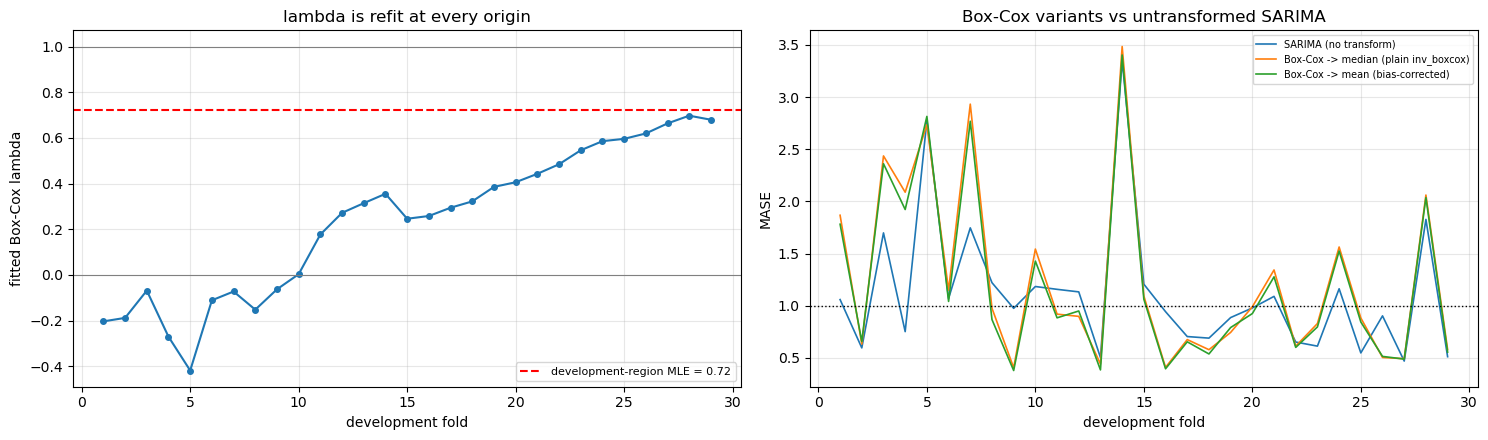

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
axes[0].plot(range(1, len(lam_s) + 1), lam_s.to_numpy(), marker="o", ms=4)
axes[0].axhline(LAMBDA_MLE_DEV, color="red", ls="--", label=f"development-region MLE = {LAMBDA_MLE_DEV:.2f}")
axes[0].axhline(0, color="gray", lw=0.8); axes[0].axhline(1, color="gray", lw=0.8)
axes[0].set_xlabel("development fold"); axes[0].set_ylabel("fitted Box-Cox lambda")
axes[0].set_title("lambda is refit at every origin"); axes[0].legend(fontsize=8)
summary.plot(ax=axes[1], lw=1.2)
axes[1].axhline(1.0, color="black", ls=":", lw=1)
axes[1].set_xlabel("development fold"); axes[1].set_ylabel("MASE")
axes[1].set_title("Box-Cox variants vs untransformed SARIMA"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

### Results of the Box-Cox forecasting comparison

| Forecasting procedure | Mean development MASE, all 29 paths |
|---|---:|
| **Raw SARIMA** | **1.117014** |
| Box-Cox: nominal median | 1.236318 |
| Box-Cox: second-order mean correction | 1.194177 |

The mean correction improved on direct inversion, but both transformed procedures remained worse than raw SARIMA. The origin-specific estimates ranged from **−0.419 to 0.697**. History length and calendar period also changed across origins, so variation in $\lambda$ alone does not explain the forecast errors.

### Did raw-selected orders constrain the transformed models?

The main Box-Cox arms reused orders selected from raw training data. I investigated that choice with an ablation that re-selected orders on the transformed histories, applying the same eligibility policy and intended common likelihood burn-in within the searches.

I compared forecasts on the **original-scale targets**. Raw- and transformed-response AIC values cannot be compared directly without the appropriate Jacobian adjustment to put likelihoods on a common response scale, as explained in Section 3.

The ablation used every third development fold, giving ten matched paths:

| Forecasting procedure | Mean MASE on ten matched folds |
|---|---:|
| **Raw SARIMA** | **1.009638** |
| Box-Cox: fixed raw-selected order | 1.294837 |
| Box-Cox: re-searched order | 1.285740 |
| **Re-search minus fixed order** | **−0.009097** |

Re-search was slightly better in this execution, but both transformed variants remained worse than raw SARIMA. The matched raw score is 1.009638, rather than the all-fold 1.117014, because it summarizes a different target set. Comparing a ten-fold variant with a 29-fold benchmark would mix procedure differences with differences in the evaluated occasions.

### What remained sensitive across executions?

An earlier execution reversed the small transformed-order contrast: re-search minus fixed-order MASE was approximately **+0.0091**, versus **−0.0091** here. The saved summaries differ by more than display rounding explains. I retained the current results and treated the relative ordering of the two transformed strategies as unresolved. Both executions nevertheless favored raw SARIMA over either transformed variant on the matched paths.

The current execution did not export full fitted parameters, per-origin candidate audits, full-precision hourly forecast arrays, or thread settings. Without those records, I cannot identify exactly which fits changed or establish the numerical cause. Optimizer or runtime sensitivity remains a plausible explanation. I did not fit repeatedly to obtain a preferred ordering. Related cross-execution sensitivity also affects the mean-arm inference in Section 13.

A separate historical fixed-parameter diagnostic illustrates the limit of convergence flags. Perturbing one seasonal AR coefficient by $+10^{-6}$ increased log-likelihood by about **0.02275**. With unchanged parameter count,

$$\Delta\mathrm{AIC}=-2\Delta\log L\approx-0.04550.$$

The objective could thus improve after the optimizer reported convergence. This example concerns a different saved Box-Cox fitting state; it neither identifies the current contrast's cause nor establishes a numerical problem with the untransformed winning procedure.

## Section 9: Feature-Based Machine Learning

I next represented history and calendar information as predictors, rather than specifying temporal dynamics directly through SARIMA. The design had to produce **all 48 hourly forecasts at once**, using information available at the origin.

### Features available for every horizon

| Feature group | Columns |
|---|---:|
| Lags 48 through 119 | 72 |
| Calendar features | 5 |
| **Total** | **77** |

Future timestamps are known, so their calendar features can be computed in advance. Lagged targets require a timestamp check. Let $o$ be the last observed time, $h\in\{1,\ldots,48\}$ the forecast horizon, and $\ell$ a lag. Its source observation is at $o+h-\ell$ and must satisfy

$$o+h-\ell\le o\quad\Longleftrightarrow\quad h\le\ell.$$

Choosing $\ell\in\{48,\ldots,119\}$ satisfies this for every horizon. Each forecast row therefore uses observations already available at $o$. 

The upper limit of **119** comes from using **72 consecutive hourly lag features**, covering three daily cycles. Starting at lag 48, the last included lag is:
$$
48+72-1=119.
$$
In the code, this is `range(48, 120)`, whose upper endpoint is excluded. The lower bound of 48 ensures availability across the entire forecast horizon; the choice of 72 lag features is a fixed modeling choice. The experiment does not establish 119 as the optimal maximum lag.

For example, if 00:00 is the last observed time, lag 1 is available for the 01:00 forecast but would require an unknown actual for 02:00. Feeding that actual into a forecast issued at 00:00 would leak future information. Feeding the 01:00 prediction back instead defines a different, recursive procedure with possible error propagation.

### Keeping preprocessing and tuning inside the information set

I checked lag source timestamps and hourly continuity: a shift by 48 rows represents 48 hours only on a continuous hourly grid. Hyperparameter tuning used fixed **48-hour inner validation blocks**.

Scaling and dimension reduction stayed inside the tuning pipelines, fitted to each inner training portion before application to its validation block. For example, a standard scaler uses $z=(x-\hat\mu)/\hat\sigma$, with training-feature mean $\hat\mu$ and standard deviation $\hat\sigma$. Fitting it before the split would allow validation observations to affect that transformation.

Inner tuning minimized **MAE**; the outer ranking used **mean per-origin MASE**, as defined in Section 2. These are related criteria, but changing historical scales across origins changes the weighting in the outer summary. All procedures used common outer forecast targets.

### Lag warm-up and matrix dimensions

The largest lag, 119, requires 119 observations preceding the first usable target. For a rolling window of $w$ training targets, the code retains $w+119$ observations when sufficient earlier history exists. The extra observations support feature construction; they are not extra training targets.

At the first origin there are 336 historical observations. Lag construction leaves $336-119=217$ usable training rows. With 77 predictors and 48 future timestamps,

$$
X_{\mathrm{train}}\in\mathbb R^{217\times77},\qquad
X_{\mathrm{forecast}}\in\mathbb R^{48\times77}.
$$

Every forecast row can be built without future target values. These safeguards define the evaluated feature-based procedure; they do not remove the broader limitations of adaptive development described in Section 1. The model configurations and grids below establish its scope. Other features, lag ranges, forecasting strategies, or tuning rules could give different results.


In [24]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from xgboost import XGBRegressor

LAG_START, LAG_END = HORIZON, HORIZON + 72          # lags 48..119; every lag >= horizon

def make_features(frame):
    x = frame[["y"]].copy()
    for i in range(LAG_START, LAG_END):
        x[f"lag_{i}"] = x["y"].shift(i)
    h, w = x.index.hour, x.index.dayofweek
    x["hour_sin"], x["hour_cos"] = np.sin(2*np.pi*h/24), np.cos(2*np.pi*h/24)
    x["weekday_sin"], x["weekday_cos"] = np.sin(2*np.pi*w/7), np.cos(2*np.pi*w/7)
    x["is_weekend"] = (w >= 5).astype(int)
    return x

def prepare_ml(train, val_dates, max_train_hours=None):
    """max_train_hours=None -> expanding window; an int -> rolling window of that length."""
    _assert_hourly_index(train.index)
    _assert_hourly_index(val_dates)
    if len(val_dates) != HORIZON or val_dates[0] != train.index[-1] + pd.Timedelta(hours=1):
        raise ValueError("Forecast dates must be the next complete 48-hour horizon")
    if max_train_hours is not None:
        if (isinstance(max_train_hours, (bool, np.bool_))
                or not isinstance(max_train_hours, (int, np.integer)) or max_train_hours < 1):
            raise ValueError("Rolling target window must be a positive integer")
        # LAG_END is exclusive: 119 history rows + w target rows, not 120 + w.
        train = train.iloc[-(max_train_hours + LAG_END - 1):]
    combined = pd.DataFrame(index=train.index.union(val_dates))
    combined["y"] = np.nan
    combined.loc[train.index, "y"] = train["y"]
    feat = make_features(combined)
    tr = feat.loc[train.index].dropna()
    X_val = feat.loc[val_dates].drop(columns=["y"])
    assert X_val.isna().sum().sum() == 0, "no prediction row may contain a NaN feature"
    assert_lag_availability(X_val, train.index[-1])
    return tr.drop(columns=["y"]), tr["y"], X_val

def _splits(n): return max(2, min(3, n // 40))

def _assert_hourly_index(index):
    if (not isinstance(index, pd.DatetimeIndex) or not len(index)
            or index.has_duplicates or not index.is_monotonic_increasing
            or (len(index) > 1 and not (index[1:] - index[:-1] == pd.Timedelta(hours=1)).all())):
        raise ValueError("Forecast features require a unique, contiguous hourly index")

def assert_lag_availability(X, origin):
    """Each lag at time t must reference t-lag <= the single forecast origin."""
    _assert_hourly_index(X.index)
    known_calendar = {"hour_sin", "hour_cos", "weekday_sin", "weekday_cos", "is_weekend"}
    for column in X.columns:
        if column in known_calendar:
            continue                       # deterministic functions of future timestamps
        if not isinstance(column, str) or not column.startswith("lag_"):
            raise ValueError(f"Feature availability has not been verified: {column!r}")
        lag = int(column[4:])
        if lag < 1 or (X.index - pd.Timedelta(hours=lag) > origin).any():
            raise ValueError(f"{column} requires observations after forecast origin {origin}")

def forecast_cv(X):
    """Fixed-origin 48-hour inner folds with the declared split count and no gap."""
    _assert_hourly_index(X.index)
    folds = list(TimeSeriesSplit(n_splits=_splits(len(X)), test_size=HORIZON, gap=0).split(X))
    for tr_idx, va_idx in folds:
        origin = X.index[tr_idx[-1]]
        if len(va_idx) != HORIZON or X.index[va_idx[0]] != origin + pd.Timedelta(hours=1):
            raise ValueError("Inner validation must begin immediately after its forecast origin")
        assert_lag_availability(X.iloc[va_idx], origin)
    return folds

_f1 = DEV_FOLDS.iloc[0]
_Xt, _yt, _Xv = prepare_ml(df.loc[df.index < _f1["validation_start"]],
                           pd.date_range(_f1["validation_start"], _f1["validation_end"], freq="h"))
print(f"fold 1 design matrix: X_train {_Xt.shape}, X_val {_Xv.shape}")
print(f"features: {LAG_END-LAG_START} lags + 5 calendar = {_Xt.shape[1]}")

fold 1 design matrix: X_train (217, 77), X_val (48, 77)
features: 72 lags + 5 calendar = 77


In [25]:
def _sk(make_est, grid=None, window=None):
    """Build a fit_predict from an sklearn estimator, optionally grid-searched."""
    def f(train, val_dates):
        X, y, Xv = prepare_ml(train, val_dates, max_train_hours=window)
        est = make_est()
        if grid:
            est = GridSearchCV(est, grid, cv=forecast_cv(X),
                               scoring="neg_mean_absolute_error").fit(X, y)
        else:
            est.fit(X, y)
        return np.asarray(est.predict(Xv)).ravel()
    return f

def pca_variance_rule(train, val_dates, threshold=0.95):
    """The classic PCR recipe: keep enough components for 95% of feature variance."""
    X, y, Xv = prepare_ml(train, val_dates)
    sc = StandardScaler().fit(X); Xs, Xvs = sc.transform(X), sc.transform(Xv)
    ev = PCA().fit(Xs).explained_variance_ratio_
    k = int(np.searchsorted(np.cumsum(ev), threshold) + 1)
    p = PCA(n_components=k).fit(Xs)
    return LinearRegression().fit(p.transform(Xs), y).predict(p.transform(Xvs))

lin = lambda: Pipeline([("s", StandardScaler()), ("m", LinearRegression())])
run_harness(_sk(lin), "Linear Regression")
run_harness(_sk(lambda: Pipeline([("s", StandardScaler()), ("m", Ridge())]),
                {"m__alpha": [0.1, 1, 3, 10, 30, 100, 300]}), "Ridge")
run_harness(_sk(lambda: Pipeline([("s", StandardScaler()), ("m", Lasso(max_iter=200000, tol=1e-3))]),
                {"m__alpha": [1, 3, 10, 30, 100, 300, 1000, 3000]}), "Lasso")
run_harness(pca_variance_rule, "PCA (95% variance rule) + Linear")
run_harness(_sk(lambda: Pipeline([("s", StandardScaler()), ("p", PCA()), ("m", LinearRegression())]),
                {"p__n_components": [2, 3, 5, 7, 10, 15, 20, 30]}), "PCA (CV-tuned k) + Linear")
run_harness(_sk(lambda: Pipeline([("s", StandardScaler()), ("m", PLSRegression())]),
                {"m__n_components": [2, 3, 5, 7, 10, 15]}), "PLS (supervised)")
print()
display(compare(BENCHMARK, "Linear Regression", "Ridge", "Lasso",
                "PCA (95% variance rule) + Linear", "PCA (CV-tuned k) + Linear",
                "PLS (supervised)").mean().round(3).to_frame("mean MASE"))

Linear Regression                            29 folds   mean MASE 1.344   [1.1s]
Ridge                                        29 folds   mean MASE 1.331   [13.2s]
Lasso                                        29 folds   mean MASE 1.277   [14.2s]
PCA (95% variance rule) + Linear             29 folds   mean MASE 1.335   [2.7s]
PCA (CV-tuned k) + Linear                    29 folds   mean MASE 1.372   [33.9s]
PLS (supervised)                             29 folds   mean MASE 1.370   [34.8s]



,mean MASE
model,
Lasso,1.277
Linear Regression,1.344
PCA (95% variance rule) + Linear,1.335
PCA (CV-tuned k) + Linear,1.372
PLS (supervised),1.370
Ridge,1.331
Seasonal naive (24h),1.393


### Regularization and Dimension Reduction

Ridge and Lasso both achieved lower mean development MASE than ordinary linear regression in this feature design.

| Forecasting procedure | Mean development MASE |
|---|---:|
| 24-hour seasonal naive benchmark | 1.393330 |
| Ordinary linear regression | 1.343600 |
| Ridge regression | 1.330805 |
| **Lasso regression** | **1.277238** |
| PCA + linear regression: 95%-variance rule | 1.334782 |
| PCA + linear regression: CV-selected components | 1.371633 |
| PLS regression | 1.370276 |

Lasso performed best among these six linear and component-based procedures. The dimension-reduction variants did not improve on it.

#### Why might regularization help?

The design contains **77 predictors, including 72 lag features**. Nearby lags can carry overlapping information, making ordinary least-squares coefficients sensitive to changes in the training sample. Regularization constrains the coefficients and can reduce this estimation sensitivity.

Writing the prediction as

$$
\hat y_i=\beta_0+\mathbf{x}_i^\top\boldsymbol{\beta},
$$

the scikit-learn objectives used here are:

**Ridge:**

$$
\min_{\beta_0,\boldsymbol{\beta}}
\left[
\sum_{i=1}^{n}(y_i-\hat y_i)^2
+\alpha_R\sum_{j=1}^{p}\beta_j^2
\right].
$$

**Lasso:**

$$
\min_{\beta_0,\boldsymbol{\beta}}
\left[
\frac{1}{2n}\sum_{i=1}^{n}(y_i-\hat y_i)^2
+\alpha_L\sum_{j=1}^{p}|\beta_j|
\right].
$$

Here, $n$ is the training-row count, $p=77$, and $\mathbf{x}_i$ contains the standardized predictors. The intercept $\beta_0$ is unpenalized. The parameters $\alpha_R$ and $\alpha_L$ control penalty strength; their numerical scales differ because the objectives use different normalizations.

Ridge generally shrinks coefficients without producing a sparse solution. Lasso can set coefficients exactly to zero, providing an embedded form of feature selection. **Both still fit a squared-error data loss**: Lasso's L1 penalty applies to coefficients, not forecast residuals. I selected their penalty strengths using inner MAE-based validation.

The observed scores support these regularized procedures on the development paths. They do not establish that Lasso improved specifically by identifying irrelevant predictors, or that its selected features were stable across origins.

#### What do PCA and PLS preserve?

**Principal Component Analysis (PCA)** replaces the predictors with orthogonal linear combinations that successively capture predictor variance. It does not use the target when constructing those components, so a high-variance direction need not be especially useful for forecasting.

Because the pipeline standardizes the predictors first, the **95% rule retains at least 95% of their standardized variance**. The threshold is fixed; the resulting component count can change with the training history.

**Partial Least Squares (PLS)** uses both predictors and the response to construct components associated with their shared variation. This supervised construction can preserve predictive information that PCA overlooks, but its forecasting benefit still depends on estimation and component selection.

Here, the 95%-variance PCA procedure outperformed CV-selected PCA. The latter searched a predefined grid of component counts, so the procedures did not necessarily consider the same representations. Their aggregate scores do not identify why the ordering occurred or establish that tuning is generally harmful.

#### Interpreting the fitted features

I retained a separately tuned probe at the last development origin to inspect coefficients and tree-based feature importances. It describes that particular fitted state, not a feature-selection pattern established across all 29 outer folds.

Correlated lags can share or exchange apparent importance as the training sample or representation changes. I therefore interpret these quantities as properties of the fitted models, without treating them as stable or causal contributions. I return to this probe after the window and encoding comparisons.

### Comparing Boosting Objectives

I next compared XGBoost with squared-error and absolute-error objectives, using the same outer development folds and the stated hyperparameter grids.

Sections 2 and 8 introduced the relevant population result: expected squared loss targets the conditional mean, while expected absolute loss targets a conditional median, under the corresponding moment conditions.

Because the outer ranking uses absolute-error-based MASE, an absolute-error training objective is worth investigating. Unlike Lasso's coefficient penalty, this choice changes the loss applied to prediction errors.

Actual boosted-tree fits use finite samples, restricted tree structures, regularization, and numerical optimization. Objective alignment therefore motivates the comparison; it does not guarantee lower forecasting error. The next results show whether it helped these particular 48-hour forecasting procedures.

In [26]:
XGB_GRID = {"n_estimators": [100, 300], "max_depth": [2, 3], "learning_rate": [0.05, 0.1]}
def _xgb(objective):
    return lambda: XGBRegressor(objective=objective, subsample=0.8, colsample_bytree=0.9,
                                random_state=SEED, n_jobs=2)

run_harness(_sk(_xgb("reg:squarederror"), XGB_GRID), "XGBoost (squared-error objective)")
run_harness(_sk(_xgb("reg:absoluteerror"), XGB_GRID), "XGBoost (absolute-error objective)")
display(compare("XGBoost (squared-error objective)", "XGBoost (absolute-error objective)")
        .mean().round(3).to_frame("mean MASE"))

XGBoost (squared-error objective)            29 folds   mean MASE 1.240   [144.6s]
XGBoost (absolute-error objective)           29 folds   mean MASE 1.331   [155.6s]


,mean MASE
model,
XGBoost (absolute-error objective),1.331
XGBoost (squared-error objective),1.240


### Comparing XGBoost Objectives: Results

Squared-error XGBoost achieved lower mean development MASE than absolute-error XGBoost:

| XGBoost objective | Mean development MASE |
|---|---:|
| **Squared error** | **1.240367** |
| Absolute error | 1.331218 |

Both procedures used the same hyperparameter grid, inner MAE-based tuning, and outer forecast paths. Nevertheless, the absolute-error training objective did not produce the lower absolute-error-based evaluation score.

This does not contradict the conditional-median result introduced in Sections 2 and 8. That result concerns unrestricted expected-loss minimization under the true conditional distribution. A finite boosted-tree model must estimate a prediction function using limited observations, constrained trees, regularization, and numerical optimization.

Approximation error, estimation variation, tuning, and systematic forecast errors could contribute to the observed ordering. This comparison does not isolate their individual contributions. It shows that objective alignment alone was insufficient to improve these particular forecasts.

### How Much History Should Each Fit Use?

I next compared expanding histories with rolling windows for **linear regression and Lasso**.

| Training strategy | Training targets used at each origin |
|---|---|
| Expanding | All usable targets in the available history |
| Three-week rolling | Up to 504 recent targets |
| Six-week rolling | Up to 1,008 recent targets |

Three weeks contain $3\times7\times24=504$ hourly observations; six weeks contain 1,008. Early origins may provide fewer usable targets than these limits.

An expanding window retains older examples as new observations arrive. This provides more data for estimating relationships, but older examples may represent conditions that have changed.

A rolling window excludes older training targets. The retained observations receive equal training weights; the emphasis on recency comes from restricting which examples enter the fit. This can make the training sample more representative of recent conditions while reducing the information available for estimation.

The experiment asks which trade-off helped the specified forecasting procedures over the 48-hour horizon.

#### Why retain additional lag history?

The predictors include lags through 119. Constructing those features for the earliest target in a rolling window therefore requires observations preceding that target.

To obtain $w$ complete training examples, I retained

$$
n_{\mathrm{history}}=w+119
$$

historical rows whenever sufficient history existed. A full three-week target window therefore required **623 rows**, and a full six-week target window required **1,127 rows**.

The additional 119 rows supply lag inputs; they do not increase the intended number of training targets. Without this allowance, lag construction would shorten the usable training window.

#### Why compare windows at common forecast origins?

Across successive origins, an expanding history becomes longer while the calendar period being forecast also changes. An error-versus-history plot therefore mixes training-sample size with changing conditions and target difficulty.

At a common origin, all window variants predict the **same next 48 observations**. This holds the forecast period fixed while changing the training history supplied to each procedure.

Sample size and sample composition still change together, and Lasso's selected penalty can also change when tuning is repeated. I therefore interpret the results as comparisons of complete window-specific forecasting procedures. They assess which strategy worked better on these development paths without establishing a universally optimal history length.

In [27]:
for w, tag in [(24*21, "3-week rolling"), (24*42, "6-week rolling")]:
    run_harness(_sk(lin, window=w), f"Linear Regression ({tag})")
    run_harness(_sk(lambda: Pipeline([("s", StandardScaler()), ("m", Lasso(max_iter=200000, tol=1e-3))]),
                    {"m__alpha": [1, 3, 10, 30, 100, 300, 1000, 3000]}, window=w), f"Lasso ({tag})")

display(compare("Linear Regression", "Linear Regression (3-week rolling)",
                "Linear Regression (6-week rolling)", "Lasso",
                "Lasso (3-week rolling)", "Lasso (6-week rolling)").mean().round(3).to_frame("mean MASE"))

Linear Regression (3-week rolling)           29 folds   mean MASE 1.364   [0.9s]
Lasso (3-week rolling)                       29 folds   mean MASE 1.248   [10.6s]
Linear Regression (6-week rolling)           29 folds   mean MASE 1.405   [1.0s]
Lasso (6-week rolling)                       29 folds   mean MASE 1.348   [12.5s]


,mean MASE
model,
Lasso,1.277
Lasso (3-week rolling),1.248
Lasso (6-week rolling),1.348
Linear Regression,1.344
Linear Regression (3-week rolling),1.364
Linear Regression (6-week rolling),1.405


### How Did Training-History Length Affect Linear Regression and Lasso?

The preferred training window depended on the estimator:

| Training window | Linear regression MASE | Lasso MASE |
|---|---:|---:|
| **Expanding history** | **1.343600** | 1.277238 |
| Three weeks: up to 504 targets | 1.364267 | **1.247865** |
| Six weeks: up to 1,008 targets | 1.405109 | 1.348092 |

Expanding history performed best among the linear-regression variants, while three-week Lasso achieved the lowest MASE among the Lasso variants. Six weeks was less favorable for both estimators.

These results support neither a universal preference for recent observations nor a rule that longer histories always improve forecasts. The useful balance between recency and sample size depended on the complete fitted procedure.

The rolling limits count usable targets after lag warm-up. During Lasso tuning, each inner fit uses an expanding subset of the supplied design matrix and predicts a subsequent 48-hour block. It therefore contains fewer targets than the final outer fit, which is refitted on the full supplied design after penalty selection.

### Encoding Hour and Weekday from Past Observations

I next added two **chronological target-encoding features** to the existing lag/calendar design:

- **Hour encoding:** the historical mean target for the same hour of day.
- **Weekday encoding:** the historical mean target for the same weekday, pooling its hourly observations.

These features express calendar categories in units of ads watched. They supplement the existing calendar predictors with summaries of previously observed activity.

#### Training encodings use strictly earlier observations

For a category $g$, the training encoding at time $t$ is

$$
\operatorname{TE}_g(t)=
\frac{\sum_{u<t,\;G(u)=g}y_u}
{\#\{u<t:G(u)=g\}},
$$

where $G(u)$ identifies the category of observation $u$. The sums include eligible observations from the supplied training history, and the denominator must be positive.

For example, suppose the earlier observations at 21:00 were 50,000, 54,000, and 58,000. The next training observation at 21:00 receives

$$
\operatorname{TE}_{21}(t)
=\frac{50{,}000+54{,}000+58{,}000}{3}
=54{,}000.
$$

Its own target value is excluded.

The code implements this rule by calculating an expanding mean within each group and shifting it by one observation: `s.expanding().mean().shift(1)`. The shift occurs within the group, so it excludes the current target and all later targets.

#### Forecast encodings are frozen at the origin

For the next 48 hours, category averages are computed from all observations in the origin's training history and then held fixed.

For example, both future occurrences of 21:00 receive the same hour encoding. The averages are not updated with actual or predicted values from within the forecast horizon.

This keeps future target observations outside the encodings used to issue that forecast.

#### Adding encodings also changes the training sample

The first observation in a category has no earlier within-group target from which to calculate an encoding. The implementation leaves that value missing and drops training rows with missing lag or encoding features.

There is no additional minimum-count requirement beyond having an earlier observation. Some affected rows already fall inside the lag warm-up period, while others can be removed specifically because an encoding is unavailable.

Consequently, this comparison changes both the **feature representation** and the **effective training sample**. Its results assess the complete target-encoded linear-regression procedure.

To isolate the contribution of the added features more directly, both designs would need to be fitted on identical eligible training rows. The current comparison does not separate that feature effect from the change in sample composition.


In [28]:
def prepare_with_target_enc(train, val_dates):
    combined = pd.DataFrame(index=train.index.union(val_dates))
    combined["y"] = np.nan
    combined.loc[train.index, "y"] = train["y"]
    feat = make_features(combined)
    hour = pd.Series(feat.index.hour, index=feat.index)
    wday = pd.Series(feat.index.dayofweek, index=feat.index)
    ty = feat.loc[train.index, "y"]
    feat["hour_te"] = np.nan; feat["wday_te"] = np.nan
    feat.loc[train.index, "hour_te"] = ty.groupby(hour.loc[train.index]).transform(
        lambda s: s.expanding().mean().shift(1))
    feat.loc[train.index, "wday_te"] = ty.groupby(wday.loc[train.index]).transform(
        lambda s: s.expanding().mean().shift(1))
    vi = feat.index.difference(train.index)
    feat.loc[vi, "hour_te"] = hour.loc[vi].map(ty.groupby(hour.loc[train.index]).mean())
    feat.loc[vi, "wday_te"] = wday.loc[vi].map(ty.groupby(wday.loc[train.index]).mean())
    tr = feat.loc[train.index].dropna()
    Xv = feat.loc[val_dates].drop(columns=["y"])
    assert Xv.isna().sum().sum() == 0
    return tr.drop(columns=["y"]), tr["y"], Xv

def linear_target_enc(train, val_dates):
    X, y, Xv = prepare_with_target_enc(train, val_dates)
    return Pipeline([("s", StandardScaler()), ("m", LinearRegression())]).fit(X, y).predict(Xv)

run_harness(linear_target_enc, "Linear Regression + target encoding")
display(compare("Linear Regression", "Linear Regression + target encoding")
        .mean().round(3).to_frame("mean MASE"))

Linear Regression + target encoding          29 folds   mean MASE 1.284   [1.1s]


,mean MASE
model,
Linear Regression,1.344
Linear Regression + target encoding,1.284


### Results of Chronological Target Encoding

The target-encoded linear procedure achieved lower mean development MASE:

| Linear-regression procedure | Mean development MASE |
|---|---:|
| Original lag/calendar design | 1.343600 |
| **Design with chronological target encodings** | **1.283543** |

As discussed above, adding the encodings also changed the eligible training rows. The observed improvement therefore belongs to the complete **encoding-plus-sample procedure** on these development paths.

The aggregate scores do not identify the mechanism behind that improvement. In particular, attributing it to reduced collinearity would require additional evidence about the fitted designs and their behavior.

### What the Fitted Features Can Explain

I next inspected Lasso coefficients, XGBoost feature importances, and PCA component weights at the **last development forecast origin**.

These probes use the **original 77-feature design**, without the added target encodings. Lasso and absolute-error XGBoost were tuned separately at that origin; PCA was fitted to the standardized predictors. The plots describe those particular representations rather than directly diagnosing the target-encoding gain.

#### Lasso: coefficients on standardized predictors

The fitted linear prediction has the form

$$
\hat y=\beta_0+\sum_{j=1}^{p}\beta_jz_j,
$$

where $z_j$ is a standardized predictor.

Holding the other inputs fixed, increasing $z_j$ by one training standard deviation changes the fitted prediction by $\beta_j$. The coefficient's sign gives the direction of that model response, while its absolute magnitude describes its size.

This is an algebraic property of the fitted prediction. With correlated predictors, isolated changes may not correspond to realistic observations, and coefficient allocation can depend on which related features are included.

The plot displays absolute coefficient magnitudes, so it does not show their signs.

#### XGBoost: normalized average split gain

For the tree model used here, `feature_importances_` reports each feature's average split gain, normalized across features.

Gain summarizes improvements to the tree-building criterion associated with splits using that feature. It measures a different quantity from a standardized regression coefficient and does not indicate whether the feature raises or lowers a prediction.

The reported percentages are normalized importance scores. They are not percentages of out-of-sample accuracy, explained target variance, or unique predictive information.

#### PCA: weights defining the components

A principal component is a weighted combination of the centered, standardized inputs:

$$
PC_k=\sum_{j=1}^{p}w_{kj}z_j.
$$

The plotted weights come from `PCA.components_`. They describe directions of predictor variation, rather than coefficients predicting the target.

The PCA panel shows the lag-feature weights for the first three components; the PCA fit itself uses all 77 predictors. Large weights can help identify shared patterns across lags, but they do not establish which inputs contribute most to forecasting accuracy.

### Why Calendar Profiles and Feature Importances Differ

Lag and calendar predictors can contain overlapping seasonal information. For example,

$$
y_{t-48}
$$

is the observation from the same hour two days earlier. It can carry information about the daily cycle alongside the explicit `hour_sin` and `hour_cos` features.

Consequently, relatively low importance for those calendar columns does not establish that the model ignored daily seasonality. Related information may already enter through the lag predictors.

The EDA hourly profile also measures a different relationship: average observed activity across hours, without conditioning on the model's other inputs. Its peak-to-trough amplitude cannot be translated into an expected percentage of model-based feature importance.

These plots help describe how particular fits use their representations. They do not establish causal effects, exclusive contributions to forecast accuracy, or stable feature rankings across all 29 forecast origins.


Lasso (alpha=3) kept 55 of 77 features
PCA needs 8 of 77 components for 95% of feature variance

Model-specific calendar-feature summaries; marginal seasonal amplitude does not determine them:
  Lasso   |coef| share : hour  24.1%   weekday+weekend  17.2%
  XGBoost gain share   : hour   5.3%   weekday+weekend   4.1%


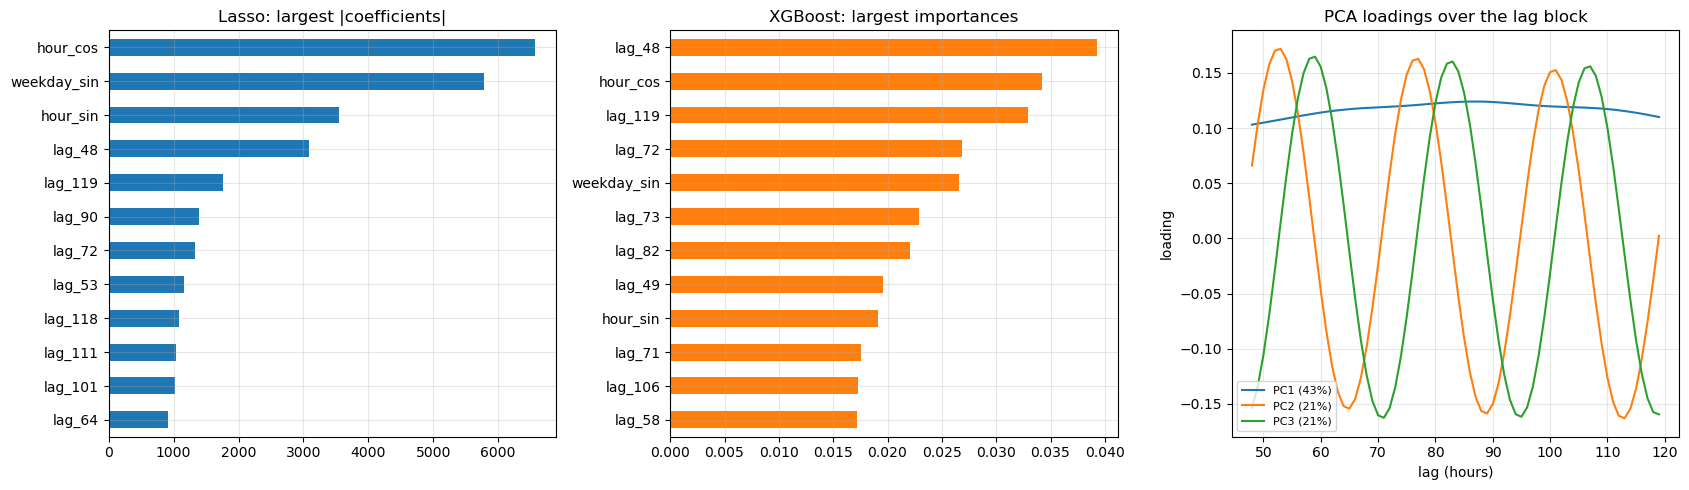

Last-development-origin probe: alpha=3; 55/77 coefficients are nonzero.


,standardized-feature coefficient,retained
hour_sin,-3553.400805,True
lag_118,-1077.202566,True
lag_101,-1020.324344,True
lag_64,-910.473269,True
lag_99,-733.726194,True
lag_102,-697.427112,True
weekday_cos,-655.207777,True
lag_104,-442.790082,True
lag_62,-411.867469,True
lag_100,-359.880501,True


This probe does not describe every outer-fold feature selection or causal effects.


In [29]:
_last = DEV_FOLDS.iloc[-1]
Xf, yf, _ = prepare_ml(df.loc[df.index < _last["validation_start"]],
                       pd.date_range(_last["validation_start"], _last["validation_end"], freq="h"))
cvf = forecast_cv(Xf)

lasso_best = GridSearchCV(Pipeline([("s", StandardScaler()), ("m", Lasso(max_iter=200000, tol=1e-3))]),
                          {"m__alpha": [1, 3, 10, 30, 100, 300, 1000, 3000]},
                          cv=cvf, scoring="neg_mean_absolute_error").fit(Xf, yf)
coefs = pd.Series(lasso_best.best_estimator_.named_steps["m"].coef_, index=Xf.columns)
xgb_best = GridSearchCV(_xgb("reg:absoluteerror")(), XGB_GRID, cv=cvf,
                        scoring="neg_mean_absolute_error").fit(Xf, yf)
imp = pd.Series(xgb_best.best_estimator_.feature_importances_, index=Xf.columns)

Xs = StandardScaler().fit_transform(Xf)
pca_probe = PCA().fit(Xs)
k95 = int(np.searchsorted(np.cumsum(pca_probe.explained_variance_ratio_), 0.95) + 1)

HOURF = ["hour_sin", "hour_cos"]; WDAYF = ["weekday_sin", "weekday_cos", "is_weekend"]
print(f"Lasso (alpha={lasso_best.best_params_['m__alpha']}) kept {(coefs != 0).sum()} of {len(coefs)} features")
print(f"PCA needs {k95} of {Xf.shape[1]} components for 95% of feature variance")
print(f"\nModel-specific calendar-feature summaries; marginal seasonal amplitude does not determine them:")
print(f"  Lasso   |coef| share : hour {coefs[HOURF].abs().sum()/coefs.abs().sum():6.1%}"
      f"   weekday+weekend {coefs[WDAYF].abs().sum()/coefs.abs().sum():6.1%}")
print(f"  XGBoost gain share   : hour {imp[HOURF].sum():6.1%}"
      f"   weekday+weekend {imp[WDAYF].sum():6.1%}")

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
coefs[coefs != 0].abs().nlargest(12).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Lasso: largest |coefficients|")
imp.nlargest(12).sort_values().plot(kind="barh", ax=axes[1], color="C1")
axes[1].set_title("XGBoost: largest importances")
lagcols = [c for c in Xf.columns if c.startswith("lag_")]
for j in range(3):
    axes[2].plot(range(LAG_START, LAG_END),
                 pca_probe.components_[j][[Xf.columns.get_loc(c) for c in lagcols]],
                 label=f"PC{j+1} ({pca_probe.explained_variance_ratio_[j]:.0%})")
axes[2].set_xlabel("lag (hours)"); axes[2].set_ylabel("loading")
axes[2].set_title("PCA loadings over the lag block"); axes[2].legend(fontsize=8)
plt.tight_layout(); plt.show()
# Read-only result reporting.
_c_show_lasso(coefs, lasso_best.best_params_)


### Results of the Last-Origin Feature-Inspection Probe

The last-development-origin probes produced the following results:

| Probe | Result |
|---|---|
| Lasso | Selected $\alpha=3$; 55 of 77 coefficients were nonzero |
| PCA | Eight components were needed to reach 95% of standardized predictor variance |

Lasso assigned zero coefficients to the remaining 22 predictors. This describes the selected fit; it does not establish that those predictors were inherently uninformative or would remain unselected at other origins.

Overlapping lag and calendar information could contribute to the observed coefficient and importance patterns, but I did not isolate that mechanism experimentally. The full coefficient table and gain/component-weight plots describe these particular representations. Detailed per-origin configuration exports are not included in this standalone notebook.

## Section 10: Prophet

I next evaluated **Prophet** as another way to represent changing trends and recurring seasonal patterns.

I compared four forecasting procedures:

| Procedure | Specification |
|---|---|
| Additive baseline | Default Prophet fitted to the original observations |
| Multiplicative seasonality | Seasonal effects expressed relative to trend |
| Box-Cox: sample median | Default additive Prophet on transformed observations; median of inverse-transformed predictive draws |
| Box-Cox: sample mean | Same construction, summarized by the mean in a separate fitting/simulation run |

### Additive and Multiplicative Seasonality

Ignoring other optional effects, the two seasonal representations can be written schematically as

$$
\text{Additive:}\qquad y_t=g(t)+s_a(t)+\epsilon_t,
$$

$$
\text{Multiplicative:}\qquad y_t=g(t)\left[1+s_m(t)\right]+\epsilon_t.
$$

Here, $g(t)$ is trend. The additive seasonal term $s_a(t)$ is measured in target units, while the multiplicative term $s_m(t)$ is a relative adjustment.

For example, an additive effect of 10,000 contributes that amount at a given seasonal position. A multiplicative effect of 20% contributes 10,000 when trend is 50,000, but 20,000 when trend is 100,000.

This distinction motivated a comparison because the development series changed in level. A changing level alone does not establish which representation will forecast better.

### Original-Scale Forecasts from Predictive Draws

At each origin, the Box-Cox procedures estimate the transformation parameter from the available training observations and fit Prophet on the transformed scale.

The code requests **1,000 predictive draws per forecast timestamp**. Valid draws are inverse-transformed individually before calculating either their sample median or sample mean on the original ads scale.

The simulation therefore provides an alternative way to summarize forecasts after a nonlinear transformation. The resulting mean and median can differ when the original-scale simulated distribution is asymmetric.

### What Uncertainty Do These Simulations Represent?

The default fitting configuration uses **maximum a posteriori (MAP) parameter estimates**, with `mcmc_samples=0`.

Predictive simulation includes observation noise and simulated future trend changes under Prophet's assumptions. It does not integrate over the full posterior uncertainty of the fitted trend and seasonal parameters.

The 1,000 draws are therefore predictive simulations under the fitted model, not 1,000 posterior parameter draws.

The mean and median arms also use **separate fitting and simulation runs**. Their observed difference can include Monte Carlo variation, and potentially numerical fitting differences, alongside the choice of summary statistic. They are not a comparison of two summaries calculated from identical draws.

### Checking the Inverse Box-Cox Domain

As explained in Section 8, the real-valued inverse requires

$$
1+\lambda z>0
$$

when $\lambda\ne0$.

The code marks draws outside this domain as missing and calculates summaries from the remaining values. **If draws are omitted**, the resulting summary describes the distribution conditional on satisfying the domain restriction.

This omission rule permits computation but does not make the original fitted predictive distribution compatible with the inverse transformation. The domain issue remains a limitation of the forecasting construction.

The printed discard-rate diagnostic tracks the median-arm runs. The mean arm applies the same validity check but does not retain its discard fractions.

The following comparison evaluates these four complete Prophet procedures on the common development forecast paths.


In [30]:
from prophet import Prophet
logging.getLogger("cmdstanpy").disabled = True      # re-armed at fit time; disable outright
logging.getLogger("cmdstanpy").propagate = False

def _pframe(train):
    return train.reset_index()[["ds", "y"]]

def prophet_baseline(train, val_dates):
    m = Prophet().fit(_pframe(train))
    return m.predict(pd.DataFrame({"ds": val_dates}))["yhat"].to_numpy()

def prophet_multiplicative(train, val_dates):
    m = Prophet(seasonality_mode="multiplicative").fit(_pframe(train))
    return m.predict(pd.DataFrame({"ds": val_dates}))["yhat"].to_numpy()

N_DRAWS = 1000

def _prophet_bc_draws(train, val_dates):
    """Back-transformed simulated predictive draws conditional on the default fitted model."""
    pdf = _pframe(train).copy()
    pdf["y"], lam = stats.boxcox(pdf["y"].to_numpy())
    m = Prophet(uncertainty_samples=N_DRAWS).fit(pdf)
    draws = m.predictive_samples(pd.DataFrame({"ds": val_dates}))["yhat"]
    # inverse Box-Cox needs lam*y + 1 > 0: a LOWER bound when lam>0, an UPPER bound when lam<0.
    ok = (lam * draws + 1) > 0
    return np.where(ok, inv_boxcox(np.where(ok, draws, 0.0), lam), np.nan), float(np.mean(~ok))

_oos_frac = []
def prophet_boxcox_median(train, val_dates):
    bt, frac = _prophet_bc_draws(train, val_dates); _oos_frac.append(frac)
    return np.nanmedian(bt, axis=1)

def prophet_boxcox_mean(train, val_dates):
    bt, _ = _prophet_bc_draws(train, val_dates)
    return np.nanmean(bt, axis=1)

run_harness(prophet_baseline, "Prophet")
run_harness(prophet_multiplicative, "Prophet (multiplicative)")
run_harness(prophet_boxcox_median, "Prophet + Box-Cox (MC median)")
run_harness(prophet_boxcox_mean, "Prophet + Box-Cox (MC mean)")
print(f"\ndraws falling outside the inverse-Box-Cox support: max {100*max(_oos_frac):.3f}% of any fold")
display(compare(BENCHMARK, "Prophet", "Prophet (multiplicative)",
                "Prophet + Box-Cox (MC median)", "Prophet + Box-Cox (MC mean)")
        .mean().round(3).to_frame("mean MASE"))

Prophet                                      29 folds   mean MASE 1.233   [5.1s]
Prophet (multiplicative)                     29 folds   mean MASE 1.201   [5.2s]
Prophet + Box-Cox (MC median)                29 folds   mean MASE 1.643   [6.1s]
Prophet + Box-Cox (MC mean)                  29 folds   mean MASE 1.784   [6.0s]

draws falling outside the inverse-Box-Cox support: max 0.000% of any fold


,mean MASE
model,
Prophet,1.233
Prophet (multiplicative),1.201
Prophet + Box-Cox (MC mean),1.784
Prophet + Box-Cox (MC median),1.643
Seasonal naive (24h),1.393


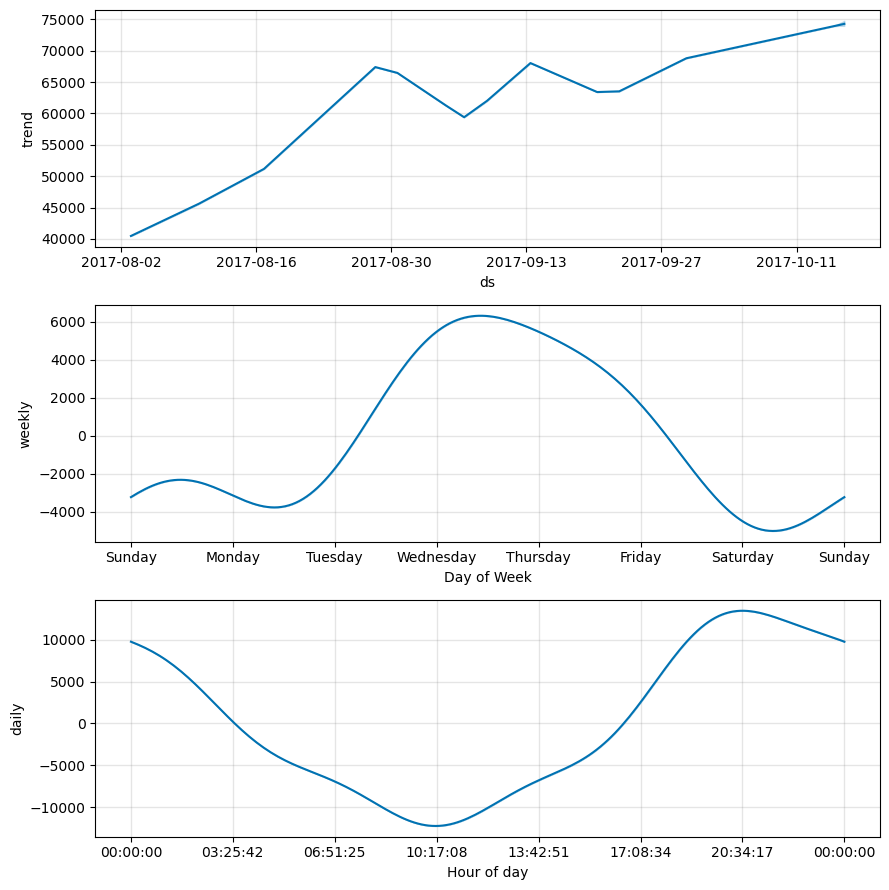

In [31]:
# Components, fitted on the development history only -- this never touches the test block.
m_comp = Prophet().fit(_pframe(df.loc[df.index <= DEV_END]))
fc_comp = m_comp.predict(m_comp.make_future_dataframe(periods=HORIZON, freq="h"))
fig = m_comp.plot_components(fc_comp); plt.show()

### Results of the Prophet Comparison

Multiplicative Prophet achieved lower mean development MASE than the additive baseline, while both Box-Cox procedures performed worse:

| Prophet procedure | Mean development MASE |
|---|---:|
| **Multiplicative seasonality** | **1.201347** |
| Additive baseline | 1.233232 |
| Box-Cox: sample median | 1.643146 |
| Box-Cox: sample mean | 1.783974 |

The median-based Box-Cox procedure outperformed the mean-based procedure here. The ordering differed from the SARIMA comparison in Section 8, which used a second-order mean correction rather than predictive-sample averaging.

These are comparisons of distinct fitted procedures. Their results do not establish a general preference for mean or median forecasts, particularly because the Prophet arms used separate fitting and simulation runs.

### Inverse-Transformation Boundaries and Simulation Stability

The inverse Box-Cox condition applies to the **transformed variable $z$**:

$$
\lambda<0:\quad z<-\frac1\lambda,
\qquad
\lambda>0:\quad z>-\frac1\lambda.
$$

For negative $\lambda$, the inverse diverges as $z$ approaches its upper boundary. For example,

$$
\lambda=-0.5
\quad\Longrightarrow\quad
g_\lambda^{-1}(z)=(1-0.5z)^{-2},
\qquad z<2.
$$

As $z\to2^-$, the original-scale value tends to infinity. The upper bound on $z$ therefore does not impose an upper bound on the predicted count.

A few valid draws near this boundary can strongly affect a Monte Carlo mean. A finite average from 1,000 draws does not establish that the underlying predictive mean exists or that its estimate is stable. However, the saved results do not establish that near-boundary draws caused the mean arm's higher forecasting error.

For positive $\lambda$, the inverse approaches zero at its lower domain boundary. When $\lambda=0$, the inverse is $e^z$ and has no finite domain boundary.

The printed exclusion-rate diagnostic covers the median arm only; corresponding mean-arm rates were not printed or exported. Even zero exclusions in a finite simulation would not prove that the predictive distribution assigns zero probability outside the valid domain. Omitting invalid draws remains a computational handling rule, with the limitations discussed above.

## Section 11: Forecast Combination

I next investigated whether combining forecasts could exploit complementary errors across a **fixed pool of ten named configurations**.

The pool included seasonal naive, Holt-Winters, raw SARIMA, the weekly-Fourier hybrid, linear regression, Ridge, Lasso, PLS, absolute-error XGBoost, and additive Prophet. Several broad families therefore contributed more than one member.

### Three Combination Rules

Let $\hat y_{j,h}$ be member $j$'s forecast at horizon $h$, with $M=10$ members.

**Equal weights** average the forecasts:

$$
\hat y_{\mathrm{equal},h}
=\frac1M\sum_{j=1}^{M}\hat y_{j,h}.
$$

Each configuration receives weight 0.1, without estimating relative performance weights.

**Component-wise median** takes the median across member forecasts separately for each horizon:

$$
\hat y_{\mathrm{median},h}
=\operatorname{Median}
\{\hat y_{1,h},\ldots,\hat y_{M,h}\}.
$$

With ten members, this averages the two middle forecasts after sorting. It limits the influence of extreme predictions from a minority of members, but can still be inaccurate when the central group is biased.

**Inverse-MAE weighting** gives greater weight to members with lower average historical MAE:

$$
w_{j,i}
=
\frac{1/\overline{\operatorname{MAE}}_{j,<i}}
{\sum_{k=1}^{M}1/\overline{\operatorname{MAE}}_{k,<i}},
\qquad
\hat y_{\mathrm{inverse},i,h}
=\sum_{j=1}^{M}w_{j,i}\hat y_{j,i,h}.
$$

Here, $\overline{\operatorname{MAE}}_{j,<i}$ is member $j$'s mean MAE over development folds strictly preceding fold $i$. Each origin's weights are held fixed throughout its 48-hour forecast.

### When Were the Weights Determined?

During development, the implementation uses equal weights for the **first two folds**. From the third fold onward, inverse-MAE weights use all strictly earlier development-fold losses.

Validation weights are calculated from development losses and remain fixed across validation origins. They are not updated using validation errors.

If a combination is selected for final deployment, the deployment helper refits every component on the complete available history. Any inverse-MAE weights remain development-derived. This distinguishes updating the component fits from updating their combination weights.

These chronological rules govern weight calculation; the pool's design and the decision to investigate combinations remain part of the broader adaptive development process.

### Why Different Models Do Not Guarantee a Better Combination

For a linear combination with fixed weights summing to one, let $\mathbf e$ contain the member errors, $\mathbf b=E[\mathbf e]$ their biases, and $\Sigma=\operatorname{Cov}(\mathbf e)$ their error covariance matrix.

Assuming finite second moments,

$$
\operatorname{Var}(e_{\mathrm{combined}})
=\mathbf w^\top\Sigma\mathbf w,
$$

$$
\operatorname{MSE}_{\mathrm{combined}}
=\mathbf w^\top\Sigma\mathbf w
+(\mathbf w^\top\mathbf b)^2.
$$

The covariance term explains why partially offsetting errors can help. The bias term explains why averaging similarly biased forecasts can retain substantial systematic error.


<details>
<summary><strong><span style="color:red">Understanding the Variance and MSE of a Combined Forecast</span></strong></summary>

A combination can benefit when its members make errors that partially offset one another. To understand when this helps, we need to distinguish **error variability** from **systematic error**.

#### 1. The combined error is a weighted average of member errors

Let model $j$ produce forecast $\hat y_j$, with error

$$
e_j=y-\hat y_j.
$$

For fixed weights satisfying $\sum_j w_j=1$, the combined forecast is

$$
\hat y_{\mathrm{combined}}=\sum_j w_j\hat y_j.
$$

Its error is therefore

$$
e_{\mathrm{combined}}
=y-\hat y_{\mathrm{combined}}
=\sum_j w_je_j.
$$

For example, an equal-weight combination of two models has error

$$
e_{\mathrm{combined}}=\frac12e_1+\frac12e_2.
$$

Errors in opposite directions can cancel. Errors in the same direction can persist.

#### 2. What does the covariance matrix contain?

The matrix $\Sigma$ summarizes how the member errors vary:

- Its diagonal entries are individual error variances.
- Its off-diagonal entries are covariances between different models' errors.

For two models,

$$
\Sigma=
\begin{pmatrix}
\sigma_1^2 & c_{12}\\
c_{12} & \sigma_2^2
\end{pmatrix},
$$

where $\sigma_j^2=\operatorname{Var}(e_j)$ and
$c_{12}=\operatorname{Cov}(e_1,e_2)$.

Positive covariance means the errors tend to move together around their respective averages. Negative covariance means those movements tend to offset each other.

#### 3. Expanding the combined-error variance

For two models, the variance formula is

$$
\operatorname{Var}(e_{\mathrm{combined}})
=
w_1^2\sigma_1^2
+w_2^2\sigma_2^2
+2w_1w_2c_{12}.
$$

The first two terms represent the weighted individual variances. The final term accounts for how the errors move together.

With many models, matrix notation collects all these terms into

$$
\boxed{
\operatorname{Var}(e_{\mathrm{combined}})
=\mathbf w^\top\Sigma\mathbf w
}.
$$

Here, $\mathbf w$ is the column vector of weights, and $\top$ denotes its transpose.

**Numerical illustration:** Suppose two models each have error standard deviation 10, giving error variance 100. If their errors are uncorrelated, $c_{12}=0$. Equal weighting gives

$$
\operatorname{Var}(e_{\mathrm{combined}})
=
\left(\frac12\right)^2 100
+\left(\frac12\right)^2 100
=50.
$$

The combined error standard deviation is therefore

$$
\sqrt{50}\approx7.07,
$$

compared with 10 for either member.

If their errors instead move together perfectly, with the same variance, averaging provides no variance reduction. Thus, the relationship between member errors matters alongside their individual sizes.

#### 4. Why does MSE also include squared bias?

Variance measures fluctuations **around the average error**. A forecast can fluctuate little while consistently predicting too high or too low.

Define each member's mean error as

$$
b_j=E[e_j].
$$

Under our error convention, positive mean error indicates average underprediction. Collecting these means into $\mathbf b$, the combined mean error is

$$
E[e_{\mathrm{combined}}]=\mathbf w^\top\mathbf b.
$$

For any error variable with a finite second moment,

$$
\operatorname{Var}(e)=E[e^2]-(E[e])^2.
$$

Rearranging gives the familiar decomposition

$$
\operatorname{MSE}=E[e^2]
=\operatorname{Var}(e)+(E[e])^2.
$$

Substituting the combined variance and mean error yields

$$
\boxed{
\operatorname{MSE}_{\mathrm{combined}}
=
\underbrace{\mathbf w^\top\Sigma\mathbf w}_{\text{error variance}}
+
\underbrace{(\mathbf w^\top\mathbf b)^2}_{\text{squared mean error}}
}.
$$

Returning to the numerical illustration, suppose both models also underpredict by 20 on average. Their equal-weight combination still underpredicts by 20:

$$
\frac12(20)+\frac12(20)=20.
$$

Although averaging reduced the error variance to 50, its total MSE is

$$
\operatorname{MSE}_{\mathrm{combined}}
=50+20^2=450.
$$

Averaging reduced fluctuations but preserved the shared systematic error.

These identities explain why error variances, covariances, biases, and weights must be considered together. They concern **fixed-weight linear combinations and squared error**; the project's MASE ranking still requires evaluation on the common absolute-error-based forecast scores.

</details>


Individual error magnitudes and weights also matter: low pairwise correlations alone cannot establish an improvement over the strongest member.

These are fixed-weight, linear-combination identities for **MSE**. They provide intuition without determining the performance of the nonlinear median, the adaptive weighting procedure, or the project's MAE-based MASE ranking.

I therefore evaluated all three rules on the common development paths. The **equal-weight combination** was the designated ensemble candidate for the later shortlist; this designation does not imply that it had the lowest development error among the combination rules.

For the later validation shortlist, I retained the equal-weight combination
as a simple ensemble reference. Its aggregation weights were fixed rather
than estimated from historical forecast losses.

This was a design choice, not a rule selecting the best-performing combination.
Inverse-MAE weighting achieved lower development MASE: 1.098480, compared with
1.115981 for equal weights. The component-wise median also avoided
performance-estimated weights; the arithmetic average was the designated
reference among these alternatives.

The choice of this reference and its component pool remained part of the
exploratory development process.

In [32]:
# Retain the fixed named configuration pool. Broad families have multiple members.
# Pool design is part of the historical adaptive research, even when no score is used here.
COMBINATION_POOL = [
    BENCHMARK, "Holt-Winters", "SARIMA", "SARIMA + weekly Fourier",
    "Linear Regression", "Ridge", "Lasso", "PLS (supervised)",
    "XGBoost (absolute-error objective)", "Prophet",
]
COMBINATION_POOL = [m for m in COMBINATION_POOL if m in dev_curves]
print(f"pool ({len(COMBINATION_POOL)} models):")
for m in COMBINATION_POOL: print("   ", m)

# (fold, h) -> prediction matrix for the pool
P = (pd.concat([dev_curves[m] for m in COMBINATION_POOL], ignore_index=True)
       .pipe(_assert_unique).pivot(index=["fold", "h"], columns="model", values="pred")[COMBINATION_POOL])
truth = dev_curves[COMBINATION_POOL[0]].set_index(["fold", "h"])["actual"].reindex(P.index)

fold_order = sorted(dev_curves[COMBINATION_POOL[0]]["fold"].unique())
fold_mae = {m: dev_results[m].set_index("fold")["MAE"] for m in COMBINATION_POOL}

def _combine(kind):
    out = {}
    for i, fd in enumerate(fold_order):
        block = P.xs(fd, level="fold")
        if kind == "equal":
            out[fd] = block.mean(axis=1).to_numpy()
        elif kind == "median":
            out[fd] = block.median(axis=1).to_numpy()
        else:                                     # inverse-MAE using STRICTLY EARLIER folds only
            prior = fold_order[:i]
            if len(prior) < 2:
                out[fd] = block.mean(axis=1).to_numpy()
            else:
                w = np.array([1.0 / fold_mae[m].loc[prior].mean() for m in COMBINATION_POOL])
                out[fd] = block.to_numpy() @ (w / w.sum())
    return out

def _register_combination(kind, name):
    preds = _combine(kind)
    rows, curves = [], []
    for fd in fold_order:
        act = truth.xs(fd, level="fold").to_numpy()
        p = preds[fd]
        r = DEV_FOLDS.set_index("fold").loc[fd]
        rows.append({"model": name, "fold": fd, "block": "development",
                     "n_train": int(r["n_train"]), **point_scores(act, p, mase_scale(df.loc[df.index < r['validation_start']]))})
        curves.append(pd.DataFrame({"model": name, "fold": fd, "block": "development",
                                    "ds": pd.date_range(r["validation_start"], periods=len(p), freq="h"),
                                    "h": np.arange(1, len(p) + 1), "actual": act, "pred": p,
                                    "abs_err": np.abs(act - p)}))
    dev_results[name] = pd.DataFrame(rows)
    dev_curves[name] = pd.concat(curves, ignore_index=True)
    print(f"{name:<44s} {len(rows)} folds   mean MASE {dev_results[name]['MASE'].mean():.3f}")

_register_combination("equal",   "Combination (equal weights)")
_register_combination("median",  "Combination (median)")
_register_combination("invmae",  "Combination (inverse-MAE, expanding)")
print()
display(compare(BENCHMARK, "SARIMA + weekly Fourier", "Combination (equal weights)",
                "Combination (median)", "Combination (inverse-MAE, expanding)")
        .mean().round(3).to_frame("mean MASE"))

pool (10 models):
    Seasonal naive (24h)
    Holt-Winters
    SARIMA
    SARIMA + weekly Fourier
    Linear Regression
    Ridge
    Lasso
    PLS (supervised)
    XGBoost (absolute-error objective)
    Prophet
Combination (equal weights)                  29 folds   mean MASE 1.116
Combination (median)                         29 folds   mean MASE 1.125
Combination (inverse-MAE, expanding)         29 folds   mean MASE 1.098



,mean MASE
model,
Combination (equal weights),1.116
"Combination (inverse-MAE, expanding)",1.098
Combination (median),1.125
SARIMA + weekly Fourier,0.955
Seasonal naive (24h),1.393


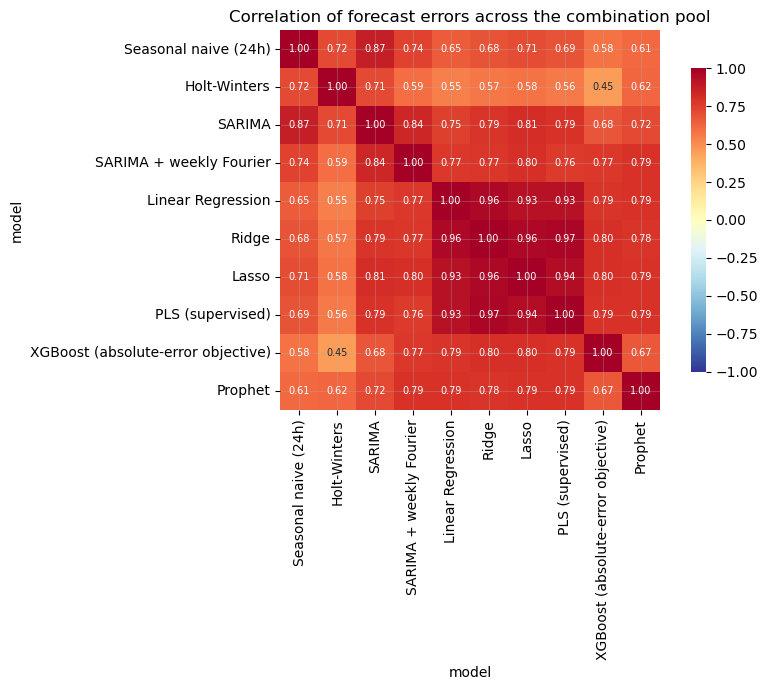

mean pairwise error correlation: 0.748   (min 0.450, max 0.973)
Error covariance, magnitudes, biases and weights jointly determine combination performance.
Observed accuracy and fold variability are separate quantities; lower SD alone is not better forecasting.


,mean_MASE,median_MASE,fold_MASE_sd,mean_dMASE,folds_below_benchmark,n_folds,sd_rank_all_configurations
model,,,,,,,
SARIMA + weekly Fourier,0.954947,0.825188,0.463503,-0.438383,25,29,1.0
DHR (Fourier replaces seasonal diff),1.047932,0.812393,0.600785,-0.345398,22,29,4.0
"Combination (inverse-MAE, expanding)",1.098480,0.959673,0.615634,-0.294850,23,29,5.0
Combination (equal weights),1.115981,0.955790,0.625455,-0.277349,23,29,6.0
SARIMA,1.117014,0.978051,0.652196,-0.276316,22,29,9.0
Combination (median),1.124796,0.955129,0.654565,-0.268534,20,29,10.0
SARIMA + Box-Cox (mean-corrected),1.194177,0.883418,0.815449,-0.199153,17,29,24.0
Prophet (multiplicative),1.201347,1.125303,0.519399,-0.191983,17,29,2.0
Prophet,1.233232,1.179146,0.579088,-0.160098,18,29,3.0


In [33]:
# Combination weights are only useful if the members disagree. Quantify that.
err = (pd.concat([dev_curves[m] for m in COMBINATION_POOL], ignore_index=True)
         .assign(err=lambda d: d["actual"] - d["pred"])
         .pipe(_assert_unique).pivot(index=["fold", "h"], columns="model", values="err")[COMBINATION_POOL])
corr = err.corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={"shrink": .8}, annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation of forecast errors across the combination pool")
plt.tight_layout(); plt.show()
iu = np.triu_indices_from(corr.to_numpy(), k=1)
print(f"mean pairwise error correlation: {corr.to_numpy()[iu].mean():.3f}   "
      f"(min {corr.to_numpy()[iu].min():.3f}, max {corr.to_numpy()[iu].max():.3f})")
print("Error covariance, magnitudes, biases and weights jointly determine combination performance.")
# Read-only result reporting.
_c_show_model_spread(dev_results, BENCHMARK)


### Results of the Forecast-Combination Comparison

All three combinations achieved lower mean development MASE than seasonal naive, but none outperformed the weekly-Fourier hybrid.

| Forecasting procedure | Mean development MASE | Fold-MASE standard deviation |
|---|---:|---:|
| **Weekly-Fourier hybrid** | **0.954947** | **0.463503** |
| Expanding inverse-MAE weights | 1.098480 | 0.615634 |
| Equal-weight combination | 1.115981 | 0.625455 |
| Component-wise median | 1.124796 | 0.654565 |
| Seasonal naive | 1.393330 | 0.718711 |

Inverse-MAE weighting performed best among the three combination rules. Nevertheless, combining the selected members did not improve on the strongest individual procedure.

The pooled hourly-error correlations averaged **0.748**, ranging from **0.450 to 0.973**. These describe shared variation in the observed errors; they do not establish why the combinations achieved their particular rankings.

Pearson correlation centers each error series, so it does not measure constant mean bias. Pooling across origins and horizons can also mix changing error scales and time-varying systematic patterns.

### Average Accuracy and Variation Across Folds

Mean MASE summarizes average scaled error. Its sample standard deviation describes how much that loss varied across the 29 development origins.

The weekly-Fourier procedure had the smallest observed fold-MASE standard deviation across the evaluated configurations. An ensemble was therefore not automatically the least variable procedure by this measure.

This is variation in **fold-level forecasting loss**, rather than variation in the predicted series itself. A procedure could produce consistently poor forecasts and still have a small loss standard deviation, so spread must be read alongside average accuracy.

The saved table retains means, medians, sample standard deviations, paired benchmark differences, and spread ranks calculated from unrounded scores.

## Section 12: Residual Intervals and Proper Scoring

A point forecast gives one predicted value. Prediction intervals address how far the future observation might lie from that prediction.

I used errors from earlier forecast paths to construct two different uncertainty summaries: **pointwise intervals** and **simultaneous path bands**.

### Two Different Coverage Targets

For a nominal 80% pointwise interval, the objective is approximately 80% coverage at each fixed horizon across repeated forecast occasions.

For a nominal 80% simultaneous band, the objective is approximately 80% coverage of the **entire 48-hour path**.

| Construction | Coverage is assessed by asking |
|---|---|
| Pointwise interval | Did the observation at this horizon fall inside its interval? |
| Simultaneous path band | Did all 48 observations fall inside their corresponding bands? |

If 47 hourly observations are covered and one is missed, the path contributes 47 hourly successes to pointwise evaluation but fails simultaneous coverage.

The notebook reports pointwise coverage by averaging horizon-specific hit rates. Path coverage counts a forecast occasion as successful only when all 48 observations are covered.

These are intended coverage targets, not established guarantees for this study.

### What Information Enters Calibration?

At each rolling evaluation origin, calibration uses only earlier forecast paths.

The first **eight paths** estimate horizon-specific mean absolute-error scales for simultaneous bands. Subsequent earlier paths supply calibration scores for both interval constructions. Evaluation begins once at least **eight additional calibration paths** are available.

At a fixed horizon, $m$ calibration paths supply $m$ residual scores. The 48 errors within a path are not treated as 48 independent calibration replications. The simultaneous construction instead uses one summary score for each complete path.

Paths can also remain dependent across origins. Their count is therefore not an estimate of the number of independent observations.

### Why This Is Conformal-Inspired Calibration

The construction borrows a corrected calibration rank from conformal prediction.

Usual conformal coverage arguments require suitable **exchangeability** of calibration and future scores: their joint distribution must be unchanged by permuting their order.

Chronological separation defines which information is available, but does not establish this symmetry. Temporal dependence, changing conditions, and repeated model fitting leave exchangeability unverified here.

Consequently, using the rank formula does not supply a demonstrated distribution-free coverage guarantee for these forecasts. Their coverage is evaluated empirically.

### Selecting a Supported Calibration Rank

With $m$ calibration scores and nominal miscoverage $\alpha$, the code uses

$$
k=\left\lceil(m+1)(1-\alpha)\right\rceil.
$$

The ceiling rounds upward. When $k\le m$, the threshold is the $k$-th smallest calibration score.

For example, the earliest evaluated calibration set contains eight paths:

| Nominal coverage | Required rank | Result with eight scores |
|---|---:|---|
| 80% | $\lceil9(0.80)\rceil=8$ | Use the largest observed score |
| 90% | $\lceil9(0.90)\rceil=9$ | No finite threshold at that rank |

When $k>m$, the implementation returns an infinite threshold. The resulting unbounded band is marked **unsupported for finite-band evaluation** and excluded from those coverage summaries.

The code does not replace an unavailable rank with the largest observed score. When $k=m$, that maximum is legitimately selected, but it still describes historical errors rather than an absolute bound on future errors. A later change in forecasting conditions can produce larger errors.

### Comparing Methods on Common Forecast Paths

The illustrative forecasting procedures are listed explicitly in `INTERVAL_TARGETS`. The variable `lead` means its first entry—currently the weekly-Fourier procedure—not a model selected automatically from the eventual ranking.

Classical and residual-based pointwise methods are evaluated on the **same eligible forecast paths within each nominal level**.

However, higher nominal levels can require more calibration paths before a finite band becomes available. Their evaluation can therefore begin later and use a different set of target paths.

On identical observations, nested 90% intervals cannot cover fewer targets than nested 80% intervals. Aggregate coverage can nevertheless decrease when the two levels are evaluated on different forecast periods.

I therefore retain scored-path counts alongside coverage rates. These counts describe the forecasts evaluated; they are distinct from the calibration-path counts used to construct their intervals.

Coverage is also read alongside interval width. Very wide bands can achieve high coverage while providing little precision. The proper scores introduced in Section 2 provide additional ways to assess the issued uncertainty summaries.

In [34]:
ALPHA_LEVELS = [0.5, 0.2, 0.1, 0.05]     # nominal 50%, 80%, 90%, 95%
N_SCALE_FOLDS = 8                         # folds used to estimate the horizon scale
MIN_CAL_FOLDS = 8                         # further folds used purely as calibration scores

def conformal_quantile(scores, alpha):
    """
    Finite-sample rank ceil((m+1)(1-alpha)). Returns inf when the calibration set is too small
    to support the level -- an honest 'not estimable', never a silently clipped quantile.
    """
    scores = np.asarray(scores, dtype=float); m = len(scores)
    k = int(np.ceil((m + 1) * (1 - alpha)))
    return np.inf if k > m else float(np.partition(scores, k - 1)[k - 1])

def residual_matrix(curve_df, signed=False):
    """(n_folds, H) residual matrix, folds in chronological order."""
    rows = []
    for _, g in curve_df.groupby("fold", sort=True):
        g = g.sort_values("h")
        r = g["actual"].to_numpy() - g["pred"].to_numpy()
        rows.append(r if signed else np.abs(r))
    return np.vstack(rows)

def ensemble_crps(y, samples):
    """
    CRPS of an empirical ensemble (Gneiting-Raftery energy form).

    Used here to score the empirical signed-residual predictive distribution, which is a
    DIFFERENT object from the conformal bands: those are interval constructions scored by
    coverage and interval score, this is a full predictive distribution scored by CRPS.
    Built from an ensemble rather than conformal order statistics because extreme conformal
    ranks are legitimately infinite when calibration is small, and an infinite proper score
    is unusable.
    """
    samples = np.asarray(samples, dtype=float)
    return float(np.mean(np.abs(samples - y))
                 - 0.5 * np.mean(np.abs(samples[:, None] - samples[None, :])))

# ---------------------------------------------------------------------------------------------
# TWO band types, because a band and its evaluation must match.
#
#   PATH band      - score is max_h |resid_h| / s_h, ONE per 48-hour path. The band is
#                    SIMULTANEOUS target, without a proven nominal guarantee here. Evaluated by
#                    asking whether the entire path stayed inside, then averaging over folds.
#   POINTWISE band - for each horizon h, one calibration residual per fold. The band is
#                    MARGINAL at each h. Evaluated per horizon, then macro-averaged over the 48.
#
# The 48 hours within a fold are strongly dependent, so neither construction treats them as
# independent calibration observations: both use exactly one observation per fold per quantity.
# ---------------------------------------------------------------------------------------------

def _split(R, n_scale, min_cal=2):
    """Split folds into a scale-estimation block and a calibration block, with no overlap."""
    if len(R) < n_scale + min_cal:
        raise ValueError(
            f"{len(R)} development fold-paths available; reserving {n_scale} for the horizon "
            f"scale leaves {max(0, len(R) - n_scale)} for calibration, below the minimum of "
            f"{min_cal}. An empty calibration block yields NaN coverage rather than an error, "
            f"so this is raised explicitly.")
    scale = R[:n_scale].mean(axis=0)
    if np.any(scale <= 0):
        raise FloatingPointError("degenerate horizon scale")
    return scale, R[n_scale:]

def path_bands(pred, scale, cal_abs, alphas):
    """cal_abs: (n_cal, H) absolute residuals -> one max-normalised score per fold."""
    scores = np.max(cal_abs / scale, axis=1)
    out = {}
    for a in alphas:
        q = conformal_quantile(scores, a)
        out[a] = (pred - q * scale, pred + q * scale)
    return out, len(scores)

def pointwise_bands(pred, cal_abs, alphas):
    """One calibration residual per fold at each fixed horizon; quantile taken per horizon."""
    n_cal, H = cal_abs.shape
    out = {}
    for a in alphas:
        q_h = np.array([conformal_quantile(cal_abs[:, h], a) for h in range(H)])
        out[a] = (pred - q_h, pred + q_h)
    return out, n_cal

def rolling_interval_eval(model_name, alphas=ALPHA_LEVELS,
                          n_scale=N_SCALE_FOLDS, min_cal=MIN_CAL_FOLDS, curves=None):
    """Rolling development evaluation: fold i is scored using only folds < i."""
    cur = (curves if curves is not None else dev_curves)[model_name]
    folds = sorted(cur["fold"].unique())
    if len(folds) <= n_scale + min_cal:
        n_scale = max(2, len(folds) // 3); min_cal = max(2, len(folds) // 3)

    path_hit = {a: [] for a in alphas}                 # one bool per fold
    pt_hit   = {a: [] for a in alphas}                 # (n_fold, H) bools
    pt_width = {a: [] for a in alphas}
    scored_folds = {a: [] for a in alphas}             # WHICH folds each level actually scored
    n_eligible, n_cal_last = 0, 0
    for i, f in enumerate(folds):
        prior = folds[:i]
        if len(prior) < n_scale + min_cal:
            continue
        n_eligible += 1
        R = residual_matrix(cur[cur["fold"].isin(prior)])
        scale, cal = _split(R, n_scale)
        n_cal_last = len(cal)
        blk = cur[cur["fold"] == f].sort_values("h")
        pred, act = blk["pred"].to_numpy(), blk["actual"].to_numpy()
        pb, _ = path_bands(pred, scale, cal, alphas)
        qb, _ = pointwise_bands(pred, cal, alphas)
        for a in alphas:
            lo, hi = pb[a]
            path_hit[a].append(bool(np.all((act >= lo) & (act <= hi))) if np.isfinite(hi).all() else None)
            lo, hi = qb[a]
            if np.isfinite(hi).all():
                pt_hit[a].append((act >= lo) & (act <= hi)); pt_width[a].append((hi - lo) / 2)
                scored_folds[a].append(f)
    rows = []
    for a in alphas:
        ph = [x for x in path_hit[a] if x is not None]
        rows.append({
            "model": model_name, "nominal": f"{int((1-a)*100)}%",
            "path_coverage": float(np.mean(ph)) if ph else np.nan,
            "pointwise_coverage": float(np.mean(np.vstack(pt_hit[a]))) if pt_hit[a] else np.nan,
            "pointwise_half_width": float(np.mean(np.vstack(pt_width[a]))) if pt_width[a] else np.nan,
            "n_paths_scored": len(scored_folds[a]),
            "eligible_folds": n_eligible, "n_calibration": n_cal_last})
    return pd.DataFrame(rows), scored_folds

INTERVAL_TARGETS = [m for m in ["SARIMA + weekly Fourier", "SARIMA", "Lasso", "Prophet",
                                "Combination (equal weights)"] if m in dev_curves]
_res = {m: rolling_interval_eval(m) for m in INTERVAL_TARGETS}
dev_intervals = pd.concat([r[0] for r in _res.values()], ignore_index=True)
SCORED_FOLDS = _res[INTERVAL_TARGETS[0]][1]        # folds the first illustrative target's bands actually scored

print("Rolling development evaluation. Each band type is scored against ITS OWN target:")
print("  path_coverage      = fraction of 48h paths contained ENTIRELY (simultaneous claim)")
print("  pointwise_coverage = marginal coverage per horizon, macro-averaged over the 48 steps")
print("    (finer numerical granularity than path coverage, but NOT a corresponding independent sample count --")
print("     hours and adjacent paths can be dependent; the fold count is not a known effective sample size)")
print(f"  eligible target folds: {int(dev_intervals['eligible_folds'].iloc[0])}"
      f"   calibration paths at the last fold: {int(dev_intervals['n_calibration'].iloc[0])}")
print("\nA level shows n/a when the calibration set cannot support its finite-sample rank, so the")
print("number of paths actually scored DIFFERS BY LEVEL -- higher levels need larger calibration")
print("sets and are therefore reached later:")
for a in ALPHA_LEVELS:
    print(f"  {int((1-a)*100):>3d}% : {len(SCORED_FOLDS[a]):>3d} paths scored")
print()
display(dev_intervals.pivot(index="model", columns="nominal",
                            values=["path_coverage", "pointwise_coverage"])
        .round(3).fillna("n/a"))

Rolling development evaluation. Each band type is scored against ITS OWN target:
  path_coverage      = fraction of 48h paths contained ENTIRELY (simultaneous claim)
  pointwise_coverage = marginal coverage per horizon, macro-averaged over the 48 steps
    (finer numerical granularity than path coverage, but NOT a corresponding independent sample count --
     hours and adjacent paths can be dependent; the fold count is not a known effective sample size)
  eligible target folds: 13   calibration paths at the last fold: 20

A level shows n/a when the calibration set cannot support its finite-sample rank, so the
number of paths actually scored DIFFERS BY LEVEL -- higher levels need larger calibration
sets and are therefore reached later:
   50% :  13 paths scored
   80% :  13 paths scored
   90% :  12 paths scored
   95% :   2 paths scored



path_coverage                  pointwise_coverage  \
nominal                               50%    80%  90%  95%                50%   
model                                                                           
Combination (equal weights)         0.846  1.000  1.0  1.0              0.635   
Lasso                               0.769  0.923  1.0  1.0              0.649   
Prophet                             0.692  1.000  1.0  1.0              0.663   
SARIMA                              0.846  1.000  1.0  1.0              0.598   
SARIMA + weekly Fourier             0.692  1.000  1.0  1.0              0.601   

                                                  
nominal                        80%    90%    95%  
model                                             
Combination (equal weights)  0.934  0.990  1.000  
Lasso                        0.925  0.984  0.990  
Prophet                      0.893  0.957  0.990  
SARIMA                       0.907  0.969  0.979  
SARIMA + weekly Fourier      0.872  0.944  0.990

In [35]:
# The classical model-derived methods, measured the same way. Both Brutlag bands and Prophet's
# native intervals are POINTWISE constructions -- they make a claim at each hour, not about the
# path as a whole -- so they are scored against pointwise coverage, matching construction to
# target exactly as Section 12 requires.
def brutlag_bands(alphas=ALPHA_LEVELS, folds=None):
    folds = DEV_FOLDS if folds is None else folds
    out = []
    for _, r in folds.iterrows():
        tr = df.loc[df.index < r["validation_start"], "y"].to_numpy()
        vd = pd.date_range(r["validation_start"], r["validation_end"], freq="h")
        a, b, g = tune_holt_winters(tr, horizon=len(vd))
        m = HoltWinters(tr, SEASON, a, b, g, n_preds=len(vd)).fit()
        k = len(vd); pred, dev = m.result[-k:], m.deviation[-k:]
        rec = {"fold": int(r["fold"]), "actual": df.loc[vd, "y"].to_numpy(), "pred": pred}
        for al in alphas:
            z = sps.norm.ppf(1 - al / 2)
            rec[al] = (pred - z * dev, pred + z * dev)
        out.append(rec)
    return out

def prophet_bands(alphas=ALPHA_LEVELS, folds=None):
    folds = DEV_FOLDS if folds is None else folds
    out = []
    for _, r in folds.iterrows():
        tr = df.loc[df.index < r["validation_start"]]
        vd = pd.date_range(r["validation_start"], r["validation_end"], freq="h")
        m = Prophet(uncertainty_samples=N_DRAWS).fit(_pframe(tr))
        fut = pd.DataFrame({"ds": vd})
        draws = m.predictive_samples(fut)["yhat"]
        rec = {"fold": int(r["fold"]), "actual": df.loc[vd, "y"].to_numpy(),
               "pred": m.predict(fut)["yhat"].to_numpy()}
        for al in alphas:
            rec[al] = (np.quantile(draws, al / 2, axis=1), np.quantile(draws, 1 - al / 2, axis=1))
        out.append(rec)
    return out

def eval_pointwise(bands, label, alphas=ALPHA_LEVELS, restrict=None):
    """
    Marginal coverage per horizon, macro-averaged across horizons; one observation per fold
    per horizon. `restrict` maps alpha -> the fold ids to score, so every method can be held
    to the SAME target paths at each level. Without it the rolling-residual band (which only
    becomes available once enough calibration folds exist) would be compared against classical
    methods evaluated on all 29 folds -- different targets, not a comparison.
    """
    rows = []
    for a in alphas:
        sel = [b for b in bands if restrict is None or b["fold"] in set(restrict[a])]
        if not sel:
            rows.append({"method": label, "nominal": f"{int((1-a)*100)}%",
                         "pointwise_coverage": np.nan, "pointwise_half_width": np.nan,
                         "interval_score": np.nan, "n_paths": 0}); continue
        hit = np.vstack([(b["actual"] >= b[a][0]) & (b["actual"] <= b[a][1]) for b in sel])
        half = np.vstack([(b[a][1] - b[a][0]) / 2 for b in sel])
        isc = np.mean([interval_score(b["actual"], b[a][0], b[a][1], a) for b in sel])
        rows.append({"method": label, "nominal": f"{int((1-a)*100)}%",
                     "pointwise_coverage": float(hit.mean()),
                     "pointwise_half_width": float(half.mean()),
                     "interval_score": float(isc), "n_paths": len(sel)})
    return pd.DataFrame(rows)

t0 = time.time()
classical = pd.concat([eval_pointwise(brutlag_bands(), "Holt-Winters (Brutlag)", restrict=SCORED_FOLDS),
                       eval_pointwise(prophet_bands(), "Prophet (native)", restrict=SCORED_FOLDS)],
                      ignore_index=True)
print(f"[{time.time()-t0:.0f}s]  Classical pointwise methods vs the pointwise rolling-residual band.")
print("All three are pointwise constructions, so all three are scored pointwise -- and all three")
print("are restricted to the SAME target paths at each level, since the rolling-residual band is")
print("only available once its calibration block exists. Paths scored per level:")
for a in ALPHA_LEVELS:
    print(f"  {int((1-a)*100):>3d}% : {len(SCORED_FOLDS[a]):>3d}")
print()

lead = INTERVAL_TARGETS[0]
lead_pt = (dev_intervals[dev_intervals["model"] == lead]
           .assign(method=f"Rolling residual (pointwise): {lead}")
           [["method", "nominal", "pointwise_coverage", "pointwise_half_width", "n_paths_scored"]]
           .rename(columns={"n_paths_scored": "n_paths"}))
comparison = pd.concat([classical[["method", "nominal", "pointwise_coverage",
                                   "pointwise_half_width", "n_paths"]],
                        lead_pt], ignore_index=True)
display(comparison.pivot(index="method", columns="nominal", values="pointwise_coverage")
        .round(3).fillna("n/a").style.set_caption("Pointwise empirical coverage, development folds"))
display(comparison.pivot(index="method", columns="nominal", values="pointwise_half_width")
        .round(0).fillna("n/a").style.set_caption("Mean pointwise half-width (ads watched)"))
_np = comparison.pivot(index="method", columns="nominal", values="n_paths").fillna(0).astype(int)
# Fail loudly if the restriction did not take: an unequal column means the methods were scored
# on different target folds, which would prevent a matched comparison.
for _lvl in _np.columns:
    assert _np[_lvl].nunique() == 1, (
        f"methods scored on different fold counts at {_lvl}: {_np[_lvl].to_dict()}")
display(_np.style.set_caption("Paths scored -- asserted identical across methods at every level"))
print("\nSupport by level (identical for all three methods):",
      {lv: int(_np[lv].iloc[0]) for lv in _np.columns})
print("Levels resting on very few paths cannot rank these methods; the count is reported so the")
print("reader can see which columns carry weight.")

[39s]  Classical pointwise methods vs the pointwise rolling-residual band.
All three are pointwise constructions, so all three are scored pointwise -- and all three
are restricted to the SAME target paths at each level, since the rolling-residual band is
only available once its calibration block exists. Paths scored per level:
   50% :  13
   80% :  13
   90% :  12
   95% :   2



nominal,50%,80%,90%,95%
method,,,,
Holt-Winters (Brutlag),0.115000,0.204000,0.273000,0.135000
Prophet (native),0.391000,0.705000,0.800000,0.938000
Rolling residual (pointwise): SARIMA + weekly Fourier,0.601000,0.872000,0.944000,0.990000


nominal,50%,80%,90%,95%
method,,,,
Holt-Winters (Brutlag),1318.000000,2504.000000,3467.000000,4354.000000
Prophet (native),3125.000000,5931.000000,7563.000000,8783.000000
Rolling residual (pointwise): SARIMA + weekly Fourier,3804.000000,8233.000000,13427.000000,14410.000000


nominal,50%,80%,90%,95%
method,,,,
Holt-Winters (Brutlag),13,13,12,2
Prophet (native),13,13,12,2
Rolling residual (pointwise): SARIMA + weekly Fourier,13,13,12,2



Support by level (identical for all three methods): {'50%': 13, '80%': 13, '90%': 12, '95%': 2}
Levels resting on very few paths cannot rank these methods; the count is reported so the
reader can see which columns carry weight.


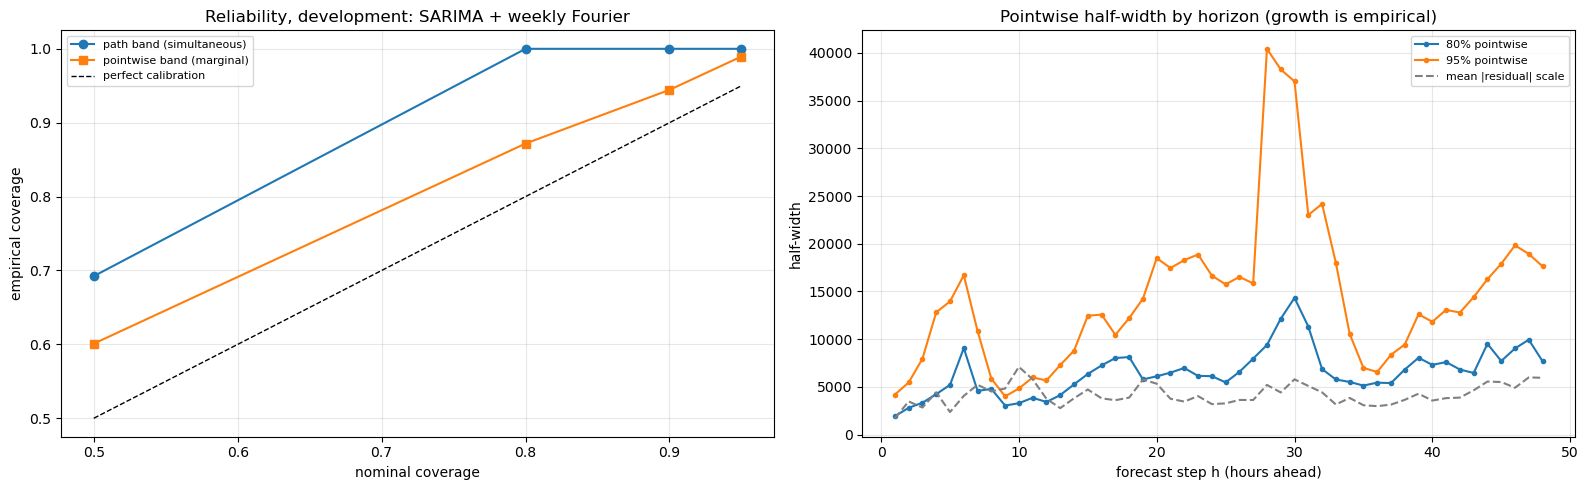

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
lead = INTERVAL_TARGETS[0]
sub = dev_intervals[dev_intervals["model"] == lead]
nom = [int(s.strip("%")) / 100 for s in sub["nominal"]]
axes[0].plot(nom, sub["path_coverage"], marker="o", label="path band (simultaneous)")
axes[0].plot(nom, sub["pointwise_coverage"], marker="s", label="pointwise band (marginal)")
axes[0].plot([0.5, 0.95], [0.5, 0.95], "k--", lw=1, label="perfect calibration")
axes[0].set_xlabel("nominal coverage"); axes[0].set_ylabel("empirical coverage")
axes[0].set_title(f"Reliability, development: {lead}"); axes[0].legend(fontsize=8)

cur = dev_curves[lead]
R = residual_matrix(cur)
scale, cal = _split(R, N_SCALE_FOLDS)
for a in (0.2, 0.05):
    q_h = np.array([conformal_quantile(cal[:, h], a) for h in range(R.shape[1])])
    if np.isfinite(q_h).all():
        axes[1].plot(np.arange(1, len(q_h) + 1), q_h, marker=".", label=f"{int((1-a)*100)}% pointwise")
axes[1].plot(np.arange(1, len(scale) + 1), scale, color="gray", ls="--", label="mean |residual| scale")
axes[1].set_xlabel("forecast step h (hours ahead)"); axes[1].set_ylabel("half-width")
axes[1].set_title("Pointwise half-width by horizon (growth is empirical)"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Matching Coverage to the Question

The pointwise intervals and simultaneous bands use historical forecast errors differently because they target different coverage events.

#### Simultaneous Bands: Calibrating the Largest Scaled Error

Let $R_{i,h}$ denote the forecast error at horizon $h$ on historical path $i$, and let $s_h>0$ be the estimated error scale for that horizon.

Each calibration path contributes one score:

$$
S_i=\max_{h=1,\ldots,48}\frac{|R_{i,h}|}{s_h}.
$$

Dividing by $s_h$ expresses errors relative to their horizon-specific scales. Taking the maximum records the worst scaled error across the entire path.

After selecting an order-statistic threshold $q$, the band is

$$
I_h^{\mathrm{sim}}
=[\hat y_h-q s_h,\ \hat y_h+q s_h].
$$

The reason for using the maximum becomes clear from

$$
S_i\le q
\quad\Longleftrightarrow\quad
|R_{i,h}|\le q s_h
\quad\text{for every }h.
$$

One threshold therefore addresses containment of the complete path. A path counts as covered only when **all 48 actual observations** lie inside their corresponding bands.

#### Pointwise Intervals: Calibrating Each Horizon Separately

For pointwise intervals, I select a threshold $q_h$ from the historical absolute errors at each fixed horizon:

$$
|R_{1,h}|,\ldots,|R_{m,h}|.
$$

The resulting interval is

$$
I_h^{\mathrm{point}}
=[\hat y_h-q_h,\ \hat y_h+q_h].
$$

Each horizon receives its own threshold. The reported coverage averages the horizon-specific hit rates; with equally many evaluated paths at every horizon, this equals the fraction of covered hourly targets.

These intervals answer an individual-hour question. The simultaneous bands answer an all-hours-together question.

### Weekly-Fourier Coverage Results

At nominal 80% coverage, the weekly-Fourier procedure produced:

| Construction | Empirical coverage | Evaluation count |
|---|---:|---|
| Pointwise residual intervals | **87.179%** | 544 of 624 hourly targets |
| Simultaneous residual bands | **100.000%** | 13 of 13 complete paths |

The 624 hourly targets come from $13\times48$ observations. They are not 624 independent forecasting replications.

The 100% simultaneous rate concerns a **separate band construction**. It does not mean that the pointwise intervals covered every hour, nor establish that every future path will be covered.

At nominal 95%, only **two paths** were eligible. Simultaneous coverage on two paths can take only the values 0%, 50%, or 100%. Its high observed value therefore provides very little replication. The dependence and exchangeability qualifications discussed earlier also remain relevant.

### Comparing Pointwise Coverage and Width

I compared the residual intervals with Brutlag-style Holt-Winters bands and native Prophet intervals on the same eligible paths within each nominal level.

At 80%, the saved rounded results were:

| Forecast-and-interval procedure | Pointwise coverage | Mean half-width, ads |
|---|---:|---:|
| Weekly-Fourier forecast + residual intervals | 87.2% | 8,233 |
| Holt-Winters + Brutlag-style bands | 20.4% | 2,504 |
| Prophet + native intervals | 70.5% | 5,931 |

Half-width here means $(u-l)/2$.

The residual procedure covered more observations and also produced the widest intervals by this summary. Its higher coverage therefore needs to be interpreted alongside that greater width.

The procedures also use different underlying point forecasts. This comparison assesses their complete forecast-and-interval constructions; it does not isolate the interval method while holding the central forecast fixed.

Brutlag's coverage was substantially below the nominal target. Its deviation scale is heuristic, but these aggregate results do not establish how much of the undercoverage arose from the scale, the point forecasts, or other aspects of the procedure.

This comparison is pointwise. The classical constructions were not assessed here as simultaneous 48-hour path bands.

### What the Scoring Results Can Establish

Coverage counts whether observations fall inside intervals. Width measures their precision. Neither alone determines overall interval quality.

The **interval score**, defined in Section 2, combines interval width with penalties for the distance of observations beyond the bounds. However, this section does not publish a matched classical-versus-residual interval-score ranking, even though classical scores are computed internally. The coverage table therefore cannot establish which procedure would win that comparison.

Section 14 reports interval scores for its specified validation targets. It also reports CRPS for a different forecasting object: an **empirical signed-residual predictive distribution**.

At horizon $h$, that distribution assigns equal probability to residual-adjusted values of the form

$$
\hat y_h+R_{1,h},\ldots,\hat y_h+R_{m,h}.
$$

Signed residuals retain error direction and can produce an asymmetric distribution around the point forecast. The absolute-residual bands above instead use error magnitudes to set symmetric interval widths.

CRPS evaluates that empirical predictive distribution. It does not score or validate the separately constructed absolute-residual bands. The two objects share historical errors as inputs, but their evaluations answer different questions.

## Section 13: Development Comparison and Statistical Evidence

I ranked all **32 forecasting procedures by mean per-origin MASE** across the
development folds. Median MASE, fold-MASE standard deviation, MAE, and RMSE
provided complementary descriptions of accuracy and observed variation.

The ranking describes which procedures performed best on average. I then
examined paired losses to assess the uncertainty surrounding those differences.

The development evaluation contained **29 nonoverlapping, 48-hour forecast
paths**. Each path contributes one aggregate loss per procedure, producing
29 paired loss differences—not 1,392 independent hourly observations.
Dependence may also remain between paths because neighboring fits share
training observations and encounter persistent forecasting conditions.

### Understanding the Two RMSE Aggregations

The results table reports both mean fold RMSE and pooled RMSE. They use the
same errors but aggregate them in a different order.

Let \(e_{i,h}\) denote the forecast error at horizon \(h\) on fold \(i\).
With \(H=48\) hours per fold, its RMSE is

$$
r_i=\sqrt{\frac{1}{H}\sum_{h=1}^{H}e_{i,h}^{2}}.
$$

For \(n\) equally sized folds,

$$
\overline{\operatorname{RMSE}}_{\mathrm{fold}}
=\frac{1}{n}\sum_{i=1}^{n}r_i,
$$

whereas

$$
\operatorname{RMSE}_{\mathrm{pooled}}
=\sqrt{\frac{1}{nH}\sum_{i=1}^{n}\sum_{h=1}^{H}e_{i,h}^{2}}
=\sqrt{\frac{1}{n}\sum_{i=1}^{n}r_i^{2}}.
$$

Thus, mean fold RMSE is the **arithmetic mean** of the fold RMSEs;
pooled RMSE is their **root mean square**. Consequently,

$$
\operatorname{RMSE}_{\mathrm{pooled}}
\geq \overline{\operatorname{RMSE}}_{\mathrm{fold}},
$$

with equality when every fold has the same RMSE. Uneven performance across
folds creates a gap between these summaries.

The column `RMSE_understated_%` calculates

$$
100\,
\frac{
\operatorname{RMSE}_{\mathrm{pooled}}
-\overline{\operatorname{RMSE}}_{\mathrm{fold}}
}{
\overline{\operatorname{RMSE}}_{\mathrm{fold}}
}.
$$

For the selected procedure, pooled RMSE was **10.044% larger than mean fold
RMSE**, using mean fold RMSE as the denominator.

Both are valid summaries of different aggregations. The word `understated`
is a retained column label, not an estimator-bias claim. **Model selection
remains based on mean per-origin MASE.**

### Paired Loss Differences and HAC Inference

For candidate procedure \(A\) and benchmark \(B\), define

$$
d_i=L_{A,i}-L_{B,i},
\qquad
\bar d=\frac{1}{n}\sum_{i=1}^{n}d_i,
$$

where \(L_{A,i}\) and \(L_{B,i}\) are their MASE values on the same fold.

A **negative** difference favors the candidate; a positive difference favors
the benchmark. Pairing compares procedures under the same forecasting conditions.

To estimate uncertainty in \(\bar d\), I used a **heteroskedasticity and
autocorrelation consistent (HAC)** variance estimator. Unlike an independence
calculation, it includes estimated relationships between loss differences
at neighboring folds.

The implementation first estimates autocovariances:

$$
\hat\gamma_k
=\frac{1}{n}\sum_{i=k+1}^{n}
(d_i-\bar d)(d_{i-k}-\bar d).
$$

Here, \(k\) is a lag measured in **folds**. Every term uses the full-sample
mean \(\bar d\), and the denominator is \(n\), including at positive lags.

The Bartlett-weighted long-run variance estimate is

$$
\hat\Omega
=\hat\gamma_0+
2\sum_{k=1}^{L}
\left(1-\frac{k}{L+1}\right)\hat\gamma_k.
$$

The lag-zero term measures ordinary variation. The remaining terms account
for estimated temporal covariance, with decreasing weights at larger lags.
The default bandwidth rule gives **\(L=3\)** for these 29 folds.

The estimated standard error and implemented adjusted statistic are

$$
\widehat{SE}(\bar d)=\sqrt{\frac{\hat\Omega}{n}},
\qquad
T_{\mathrm{adj}}
=\sqrt{\frac{n-1}{n}}\,
\frac{\bar d}{\widehat{SE}(\bar d)}.
$$

The multiplier is the implementation's **HLN-style correction with
`h_fold=1`**. This convention concerns aggregate fold losses; it does not
change the forecasting horizon from 48 hours to one hour. Two-sided p-values
use a Student \(t\) reference with \(n-1=28\) degrees of freedom.

These finite-sample conventions do not establish exact calibration for this
loss sequence. HAC justification still requires suitable dependence, moment,
stability, and bandwidth conditions. The code raises an error for a
nonpositive or numerically negligible long-run variance instead of forcing
a positive variance floor.

### Circular-Block Bootstrap Intervals

I also estimated uncertainty using a **circular-block bootstrap**.

Instead of resampling individual folds independently, this method samples
blocks of adjacent folds with replacement. A block can wrap around the end:
with length three, \((d_{28},d_{29},d_1)\) is a possible block. Sampled blocks
are concatenated and truncated to the original sequence length.

This retains observed relationships within blocks while introducing artificial
joins between them. Circular sampling gives each fold equal **expected**
representation, although individual resamples contain unequal counts.

The primary calculation used **10,000 resamples and blocks of three folds**.
For bootstrap mean differences \(\bar d^{*(b)}\), define

$$
\Delta^{*(b)}=\bar d^{*(b)}-\bar d.
$$

The nominal 95% **basic bootstrap interval** is

$$
\left[
\bar d-Q_{0.975}(\Delta^*),
\quad
\bar d-Q_{0.025}(\Delta^*)
\right].
$$

The quantiles are reversed and subtracted from the observed mean: a large
positive bootstrap deviation contributes to the lower endpoint.

An interval entirely below zero favors the candidate under this calculation.
These are individual comparison intervals, not simultaneous 95% intervals
for the entire testing family.

Bootstrap validity depends on whether the observed blocks adequately represent
the relevant dependence and whether the loss process is sufficiently stable.
For the eight leading procedures, I examined HAC lags **0, 2, 3, 5, and 8**
and alternative interval-bootstrap block lengths **2, 4, 6, and 8**.
Sensitivity describes the influence of these settings; it does not establish
the assumptions required for valid inference.

### Accounting for Multiple Comparisons

Each of the **31 nonbenchmark procedures** was compared with the
**24-hour seasonal-naive benchmark**. I applied Holm and Benjamini–Hochberg
adjustments to this family of **HAC p-values**, using a 5% significance level.

| Adjustment | Error criterion | Conditions for its usual interpretation |
|---|---|---|
| Holm | Familywise error: the probability of at least one false rejection | Valid marginal p-values; independence is not required |
| Benjamini–Hochberg | False discovery rate: the expected fraction of false rejections among all rejections, taking that fraction as zero when there are none | Valid p-values and independence or suitable positive dependence |

Neither adjustment repairs invalid underlying p-values. They address the
specified comparison family, rather than every feature, specification,
tuning, and analysis choice made during development.

### Looking for a Set of Competitive Procedures

A ranking always places one procedure first, even when the available evidence
cannot reliably separate it from several competitors. The **Model Confidence
Set (MCS)** examines this distinction through comparisons within the current
candidate set.

For procedures \(i\) and \(j\), let \(\bar d_{ij}\) be their mean paired MASE
difference. The implementation calculates

$$
t_{ij}
=\frac{\bar d_{ij}}{\widehat{SE}(\bar d_{ij})},
\qquad
T_R=\max_{i\ne j\in\mathcal M}|t_{ij}|,
$$

where \(\mathcal M\) is the current set and the standard errors come from
centered block-bootstrap calculations.

The statistic \(t_{ij}\) expresses a loss difference relative to its estimated
uncertainty. A positive value indicates higher loss for \(i\). The range
statistic \(T_R\) takes the largest absolute standardized difference to assess
**equal predictive ability within the current set**.

All model columns use the same resampled fold indices, preserving the paired
comparison. Bootstrap mean differences are recentered under the
equal-predictive-ability null.

The corresponding elimination rule is

$$
e_R=\arg\max_{i\in\mathcal M}
\max_{\substack{j\in\mathcal M\\j\ne i}}t_{ij}.
$$

It selects the procedure with the largest standardized loss disadvantage
against another remaining procedure—not necessarily the one with the
largest unstandardized mean loss.

The code computes the complete elimination sequence. Each eliminated
procedure receives the **running maximum of the round p-values** through
its elimination step; the final survivor receives \(p=1\) by convention.
The reported nominal 90% set contains procedures with MCS p-values
**at least 0.10**.

Membership therefore means survival under this testing rule. It does not
assign a 90% probability of being best, prove equality of forecasting risks,
or establish practical equivalence.

The primary MCS used **10,000 resamples and block length three**.
Sensitivity calculations used **4,000 resamples** at block lengths
**2, 3, 4, 6, and 8**. Their intersection and union summarize membership
across the examined settings; I assign no separate calibrated coverage
claim to those summaries.

For numerical integrity, exactly identical observed loss columns are grouped
during calculation and restored afterward with equal p-values and membership.
This does not establish identical algorithms or population risks. Nonzero
constant differences and other degenerate bootstrap variances raise an error
instead of being treated as equality.

### Interpreting the Evidence

These calculations describe an **adaptive development comparison**: the same
29 folds also informed the candidate specifications. Dependence, changing
conditions, limited replication, and data-driven choices restrict the strength
of formal inference. A confirmatory MCS coverage interpretation would require
appropriate regularity, bootstrap validity, and a suitable fixed testing setup.

I therefore interpret the statistical evidence alongside **effect sizes,
observed fold variation, and sensitivity to analysis settings**.

A small p-value does not establish operational value, and nonsignificance
does not establish practical equivalence. No operational cost threshold or
practical-equivalence margin was prespecified in this project.

In [37]:
master = pd.concat(dev_results.values(), ignore_index=True)
curves_all = pd.concat(dev_curves.values(), ignore_index=True)
print(f"{master['model'].nunique()} models x {master['fold'].nunique()} development folds")

rank = (master.groupby("model")
        .agg(MASE_mean=("MASE", "mean"), MASE_median=("MASE", "median"),
             MASE_sd=("MASE", "std"), MAE_mean=("MAE", "mean"))
        .sort_values("MASE_mean"))

# Pooled vs mean-of-fold RMSE. sqrt is concave, so mean-of-RMSE understates the pooled value,
# and it does so MORE for models with erratic folds -- which distorts comparisons, not just levels.
pooled = (curves_all.assign(se=lambda d: (d["actual"] - d["pred"])**2)
          .groupby("model")["se"].mean().pow(0.5).rename("RMSE_pooled"))
mean_rmse = master.groupby("model")["RMSE"].mean().rename("RMSE_mean_of_folds")
rank = rank.join(mean_rmse).join(pooled)
rank["RMSE_understated_%"] = (100 * (rank["RMSE_pooled"] / rank["RMSE_mean_of_folds"] - 1))
display(rank.round(3).style.set_caption("Development ranking. MASE > 1 exceeds the training seasonal-difference scale; compare benchmark losses directly."))

32 models x 29 development folds


,MASE_mean,MASE_median,MASE_sd,MAE_mean,RMSE_mean_of_folds,RMSE_pooled,RMSE_understated_%
model,,,,,,,
SARIMA + weekly Fourier,0.955000,0.825000,0.464000,4121.231000,5239.816000,5766.111000,10.044000
DHR (Fourier replaces seasonal diff),1.048000,0.812000,0.601000,4488.556000,5663.591000,6397.064000,12.951000
"Combination (inverse-MAE, expanding)",1.098000,0.960000,0.616000,4739.047000,5985.623000,6723.227000,12.323000
Combination (equal weights),1.116000,0.956000,0.625000,4814.251000,6062.848000,6804.693000,12.236000
SARIMA,1.117000,0.978000,0.652000,4844.053000,6164.388000,6998.220000,13.527000
Combination (median),1.125000,0.955000,0.655000,4843.888000,6041.626000,6808.220000,12.689000
SARIMA + Box-Cox (mean-corrected),1.194000,0.883000,0.815000,5052.091000,6224.011000,7255.054000,16.566000
Prophet (multiplicative),1.201000,1.125000,0.519000,5321.062000,6411.706000,6996.224000,9.116000
Prophet,1.233000,1.179000,0.579000,5414.923000,6479.862000,7110.916000,9.739000


In [38]:
from statsmodels.stats.multitest import multipletests

loss = master.pivot(index="fold", columns="model", values="MASE").sort_index()
base = loss[BENCHMARK]

def hac_mean_test(d, max_lag=None, h_fold=1, hln=True):
    """Exploratory HAC mean test on chronological aggregate fold-loss differences.

    Full-sample centering and division by n define the retained Bartlett estimator.
    Segment-specific centering is a different estimator, with no universal direction
    of bias. The PSD estimator can still be degenerate; fail rather than floor it.
    The retained t reference and HLN-style factor are conventions, not exact finite-
    sample calibration for dependent, nonstationary or adaptively selected losses.
    See Section 13 for assumptions.
    """
    d = np.asarray(d, dtype=float); d = d[np.isfinite(d)]; n = d.size
    if n < 3:
        raise ValueError("too few observations")
    if max_lag is None:
        max_lag = int(np.floor(4 * (n / 100.0) ** (2 / 9)))
    if not 0 <= max_lag < n:
        raise ValueError("max_lag out of range")

    dbar = d.mean(); x = d - dbar
    lrv = np.dot(x, x) / n
    for lag in range(1, max_lag + 1):
        lrv += 2.0 * (1.0 - lag / (max_lag + 1)) * (np.dot(x[lag:], x[:-lag]) / n)

    tol = np.finfo(float).eps * max(np.dot(x, x) / n, 1.0) * 100
    if lrv <= tol:
        raise FloatingPointError(f"degenerate HAC long-run variance ({lrv:g}); do not clamp it")

    stat = dbar / np.sqrt(lrv / n)
    if hln:
        stat *= np.sqrt((n + 1 - 2 * h_fold + h_fold * (h_fold - 1) / n) / n)
    return stat, float(2 * sps.t.sf(abs(stat), df=n - 1)), lrv, max_lag


def circular_block_indices(n, block, n_boot, rng):
    """Circular blocks give equal expected inclusion; individual resamples have unequal counts."""
    n_blocks = int(np.ceil(n / block))
    starts = rng.integers(0, n, size=(n_boot, n_blocks))
    return ((starts[..., None] + np.arange(block)) % n).reshape(n_boot, -1)[:, :n]


def block_bootstrap_ci(d, alpha=0.05, n_boot=10_000, block=3, seed=SEED):
    """Circular-block BASIC (reverse-percentile) interval for the mean difference."""
    d = np.asarray(d, dtype=float); d = d[np.isfinite(d)]; n = len(d)
    rng = np.random.default_rng(seed)
    boot = d[circular_block_indices(n, block, n_boot, rng)].mean(axis=1)
    delta = boot - d.mean()
    q_lo, q_hi = np.quantile(delta, [alpha / 2, 1 - alpha / 2])
    return np.array([d.mean() - q_hi, d.mean() - q_lo])


rows = []
for m in loss.columns:
    if m == BENCHMARK:
        continue
    d = (loss[m] - base).to_numpy()
    stat, p_hac, lrv, L = hac_mean_test(d)
    lo, hi = block_bootstrap_ci(d)
    rows.append({"model": m, "mean_dMASE": d.mean(), "sd": d.std(ddof=1),
                 "better_in": int((d < 0).sum()),
                 "p_paired_t": sps.ttest_rel(loss[m], base)[1],
                 "p_HAC": p_hac, "HAC_lag": L, "boot_lo": lo, "boot_hi": hi})
paired = pd.DataFrame(rows).sort_values("mean_dMASE").reset_index(drop=True)
for meth, col in [("holm", "p_holm"), ("fdr_bh", "p_BH")]:
    paired[col] = multipletests(paired["p_HAC"], alpha=0.05, method=meth)[1]
paired["boot_excludes_0"] = (paired["boot_lo"] > 0) | (paired["boot_hi"] < 0)

print(f"Exploratory comparison against '{BENCHMARK}', {len(loss)} development folds")
print(f"  Holm-adjusted p < 0.05 and better: "
      f"{int(((paired['p_holm'] < 0.05) & (paired['mean_dMASE'] < 0)).sum())}")
print(f"  Holm-adjusted p < 0.05 and worse : "
      f"{int(((paired['p_holm'] < 0.05) & (paired['mean_dMASE'] > 0)).sum())}")
print("\nPOST-SELECTION: these same folds designed the models being tested. Read this as a")
print("sensitivity analysis on a descriptive ranking, not as confirmatory evidence.")
_pcols = ["p_paired_t", "p_HAC", "p_holm", "p_BH"]
display(show_p(paired.round({"mean_dMASE": 3, "sd": 3, "boot_lo": 3, "boot_hi": 3}), _pcols))

Exploratory comparison against 'Seasonal naive (24h)', 29 development folds
  Holm-adjusted p < 0.05 and better: 6
  Holm-adjusted p < 0.05 and worse : 5

POST-SELECTION: these same folds designed the models being tested. Read this as a
sensitivity analysis on a descriptive ranking, not as confirmatory evidence.


,model,mean_dMASE,sd,better_in,p_paired_t,p_HAC,HAC_lag,boot_lo,boot_hi,p_holm,p_BH,boot_excludes_0
0,SARIMA + weekly Fourier,-0.438000,0.455000,25,<0.0001,<0.0001,3,-0.558000,-0.306000,<0.0001,<0.0001,True
1,DHR (Fourier replaces seasonal diff),-0.345000,0.497000,22,0.0008,0.0009,3,-0.500000,-0.168000,0.0183,0.0025,True
2,"Combination (inverse-MAE, expanding)",-0.295000,0.381000,23,0.0003,<0.0001,3,-0.424000,-0.172000,0.0006,0.0001,True
3,Combination (equal weights),-0.277000,0.385000,23,0.0006,<0.0001,3,-0.410000,-0.151000,0.0022,0.0004,True
4,SARIMA,-0.276000,0.449000,22,0.0025,<0.0001,3,-0.401000,-0.147000,0.0014,0.0003,True
5,Combination (median),-0.269000,0.409000,20,0.0014,0.0002,3,-0.408000,-0.137000,0.0041,0.0006,True
6,SARIMA + Box-Cox (mean-corrected),-0.199000,0.595000,17,0.0820,0.0841,3,-0.414000,0.013000,1.0000,0.1991,False
7,Prophet (multiplicative),-0.192000,0.612000,17,0.1023,0.0899,3,-0.403000,0.028000,1.0000,0.1991,False
8,Prophet,-0.160000,0.567000,18,0.1393,0.0658,3,-0.337000,0.007000,1.0000,0.1700,False
9,SARIMA + Box-Cox (median),-0.157000,0.617000,18,0.1815,0.1850,3,-0.381000,0.060000,1.0000,0.3268,False


In [39]:
# The HAC lag and the bootstrap block length are judgement calls, so show what they do.
top = paired.head(8)["model"].tolist()
sens = []
for m in top:
    d = (loss[m] - base).to_numpy()
    row = {"model": m}
    for L in (0, 2, 3, 5, 8):
        if L >= len(d):                       # lag must be < n
            row[f"p(L={L})"] = np.nan; continue
        try:
            row[f"p(L={L})"] = hac_mean_test(d, max_lag=L)[1]
        except FloatingPointError:
            row[f"p(L={L})"] = np.nan         # non-positive HAC variance: reported, never clamped
    for blk in (2, 4, 6, 8):
        if blk >= len(d):
            row[f"CI(b={blk})"] = "n/a"; continue
        lo, hi = block_bootstrap_ci(d, block=blk)
        row[f"CI(b={blk})"] = "excl 0" if (lo > 0 or hi < 0) else "incl 0"
    sens.append(row)
print("Sensitivity of the exploratory inference to HAC lag and bootstrap block length.")
print("Sensitivity is limited to these examined settings; stability does not establish valid assumptions.\n")
_sens = pd.DataFrame(sens).set_index("model")
display(show_p(_sens, [c for c in _sens.columns if c.startswith("p(")]))

Sensitivity of the exploratory inference to HAC lag and bootstrap block length.
Sensitivity is limited to these examined settings; stability does not establish valid assumptions.



,p(L=0),p(L=2),p(L=3),p(L=5),p(L=8),CI(b=2),CI(b=4),CI(b=6),CI(b=8)
model,,,,,,,,,
SARIMA + weekly Fourier,<0.0001,<0.0001,<0.0001,<0.0001,<0.0001,excl 0,excl 0,excl 0,excl 0
DHR (Fourier replaces seasonal diff),0.0008,0.0004,0.0009,0.0019,0.0017,excl 0,excl 0,excl 0,excl 0
"Combination (inverse-MAE, expanding)",0.0003,<0.0001,<0.0001,<0.0001,<0.0001,excl 0,excl 0,excl 0,excl 0
Combination (equal weights),0.0006,0.0003,<0.0001,<0.0001,<0.0001,excl 0,excl 0,excl 0,excl 0
SARIMA,0.0025,0.0002,<0.0001,<0.0001,<0.0001,excl 0,excl 0,excl 0,excl 0
Combination (median),0.0014,0.0006,0.0002,0.0001,<0.0001,excl 0,excl 0,excl 0,excl 0
SARIMA + Box-Cox (mean-corrected),0.0820,0.0765,0.0841,0.1050,0.1189,incl 0,incl 0,incl 0,incl 0
Prophet (multiplicative),0.1023,0.0951,0.0899,0.0942,0.0759,incl 0,incl 0,incl 0,incl 0


In [40]:
def model_confidence_set(loss_df, alpha=0.10, n_boot=10_000, block=3, seed=SEED):
    """
    Hansen-Lunde-Nason Model Confidence Set using the range statistic T_R.

    Two requirements for a coherent implementation:
      * the T_R elimination rule is argmax_i ( max_j t_ij ) -- the eliminated model is the one
        with the largest single standardised excess loss against any rival. Averaging
        already-standardised pairwise statistics is a different quantity and can remove the
        wrong model, breaking coherence between the test statistic and the elimination rule.
      * MCS p-values are the RUNNING MAXIMUM of the round p-values, which is what makes them
        monotone and interpretable per model.
    Circular blocks give each fold equal expected inclusion in the bootstrap.
    """
    if not isinstance(loss_df, pd.DataFrame):
        raise ValueError("MCS requires a DataFrame with model columns")
    if loss_df.empty or len(loss_df) < 2:
        raise ValueError("MCS requires at least two folds and one model")
    if loss_df.columns.has_duplicates:
        raise ValueError("MCS loss matrix has duplicate model names")
    _L = loss_df.to_numpy(dtype=float)
    if not np.isfinite(_L).all():
        raise ValueError("MCS loss matrix must contain only finite values")
    if not np.isfinite(alpha) or not 0 < alpha < 1:
        raise ValueError("MCS alpha must lie strictly between zero and one")
    for label, value, minimum in [("n_boot", n_boot, 2), ("block", block, 1)]:
        if (isinstance(value, (bool, np.bool_))
                or not isinstance(value, (int, np.integer)) or value < minimum):
            raise ValueError(f"MCS {label} must be an integer >= {minimum}")
    if block >= len(loss_df):
        raise ValueError("MCS block must be smaller than the number of folds")

    # Exact duplicate vectors are aliases of one tested model.
    # Restore EVERY alias to the representative's p-value and membership after testing.
    # A nonzero constant difference instead has a nonzero numerator and zero standard
    # error. It is not equality of predictive ability: do not drop it as a duplicate or
    # silently invent a finite-variance t statistic. Fail explicitly for independent review.
    _names = list(loss_df.columns)
    alias_of = {}
    keep_idx = []
    for j in range(_L.shape[1]):
        identical = next((i for i in keep_idx if np.array_equal(_L[:, i], _L[:, j])), None)
        if identical is None:
            keep_idx.append(j)
            alias_of[_names[j]] = _names[j]
        else:
            alias_of[_names[j]] = _names[identical]
    for pos, j in enumerate(keep_idx):
        for i in keep_idx[:pos]:
            difference = _L[:, i] - _L[:, j]
            if np.all(difference == difference[0]):
                raise FloatingPointError(
                    f"MCS nonzero constant loss difference: {_names[i]!r}, {_names[j]!r}; "
                    "finite-variance range statistic is undefined")
    loss_df = loss_df.iloc[:, keep_idx]

    L = loss_df.to_numpy(dtype=float); n, k = L.shape
    names = list(loss_df.columns)
    rng = np.random.default_rng(seed)
    boot_idx = circular_block_indices(n, block, n_boot, rng)

    alive, pvalues, history, running = list(range(k)), {}, [], 0.0
    while len(alive) > 1:
        sub = L[:, alive]
        means = sub.mean(axis=0)
        D = means[:, None] - means[None, :]
        bm = sub[boot_idx].mean(axis=1)
        Zb = bm[:, :, None] - bm[:, None, :] - D
        var = np.mean(Zb ** 2, axis=0)
        off = ~np.eye(len(alive), dtype=bool)
        if np.any(var[off] <= np.finfo(float).eps):
            raise FloatingPointError("degenerate pairwise bootstrap variance in MCS")
        se = np.sqrt(var); np.fill_diagonal(se, np.inf)
        tij, tij_b = D / se, Zb / se
        stat = np.max(np.abs(tij[off]))
        raw_p = (1 + np.sum(np.max(np.abs(tij_b[:, off]), axis=1) >= stat)) / (n_boot + 1)
        running = max(running, raw_p)
        worst = int(np.argmax(np.max(tij, axis=1)))
        pvalues[names[alive[worst]]] = running
        history.append((names[alive[worst]], raw_p, running))
        alive.pop(worst)
    pvalues[names[alive[0]]] = 1.0
    expanded = {nm: pvalues[alias_of[nm]] for nm in _names}
    return [nm for nm in _names if expanded[nm] >= alpha], expanded, history


PRIMARY_BLOCK = 3            # prespecified; the MCS reported below is THIS one
mcs_set, mcs_p, mcs_hist = model_confidence_set(loss, alpha=0.10, block=PRIMARY_BLOCK)
mcs_set = sorted(mcs_set, key=lambda m: rank.loc[m, "MASE_mean"])
print(f"Nominal 90% exploratory MCS at the fixed block length ({PRIMARY_BLOCK}): "
      f"{len(mcs_set)} of {loss.shape[1]} models\n")
for m in mcs_set:
    tag = "   <- benchmark" if m == BENCHMARK else ""
    print(f"   MASE {rank.loc[m,'MASE_mean']:.3f}   MCS p {fmt_p(mcs_p[m]):>8s}   {m}{tag}")
print(f"\nbenchmark retained: {BENCHMARK in mcs_set}")

# Descriptive robustness check ONLY. The MCS reported above (block=3) is the one with a
# nominal MCS rule; its coverage assumptions and adaptive-selection limits still apply.
# Re-running at other block lengths and intersecting the results does
# NOT produce a valid 90% set, and nothing below should be read as if it did. Membership rather
# than count is shown because two sets of equal size can share no members.
print("\nDescriptive sensitivity of MCS membership to block length (NOT a confidence set):\n")
sens_sets = {}
for blk in (2, 3, 4, 6, 8):
    # A block at or above the sample size makes every circular resample a rotation of the full
    # sample: all bootstrap means coincide and the bootstrap carries no information.
    if blk >= len(loss):
        print(f"  block={blk}: skipped (>= n = {len(loss)}; every resample is the full sample)")
        continue
    try:
        s_, _p, _h = model_confidence_set(loss, alpha=0.10, block=blk, n_boot=4000)
    except FloatingPointError as exc:
        print(f"  block={blk}: skipped ({exc})")
        continue
    sens_sets[blk] = sorted(s_, key=lambda mm: rank.loc[mm, "MASE_mean"])
    print(f"  block={blk}: {len(s_):2d} models -> {sens_sets[blk]}")

_k = lambda mm: rank.loc[mm, "MASE_mean"]
if sens_sets:
    always = set.intersection(*(set(v) for v in sens_sets.values()))
    ever = set.union(*(set(v) for v in sens_sets.values()))
    print(f"\n  appear at EVERY block length ({len(always)}): {sorted(always, key=_k)}")
    print(f"  appear at SOME but not all ({len(ever - always)}): {sorted(ever - always, key=_k)}")
    print("\n  Read descriptively: membership in the first group is insensitive to a tuning")
    print("  choice, membership in the second is not. Neither group is itself a 90% confidence")
    print(f"  set; the primary block={PRIMARY_BLOCK} rule above remains exploratory.")
else:
    print("\n  No feasible alternative block length at this sample size; the prespecified")
    print(f"  block={PRIMARY_BLOCK} set above stands without a robustness check.")

print("\nPOST-SELECTION: the same folds designed these models, so this is a sensitivity")
print("analysis. It is not a confidence set in the confirmatory sense.")

# ---------------------------------------------------------------------------
# Within a clean run these names are computed from development before validation scoring.
# Historical exposure remains; this ordering does not restore prospective independence.
FINAL_MODEL = rank.index[0]                                   # lowest development mean MASE
# Section 1 named "the forecast combination" as a candidate; the equal-weights variant is the
# one with no performance-based selection anywhere in its construction, so it is the candidate.
COMBINATION_CANDIDATE = "Combination (equal weights)"
PREREGISTERED = {FINAL_MODEL} | set(mcs_set) | {BENCHMARK} | {COMBINATION_CANDIDATE}
print(f"\nFROZEN before validation:")
print(f"  deployment model     : {FINAL_MODEL}")
print(f"  combination candidate: {COMBINATION_CANDIDATE}")
print(f"  validation shortlist : {sorted(PREREGISTERED)}")

Nominal 90% exploratory MCS at the fixed block length (3): 2 of 32 models

   MASE 0.955   MCS p   1.0000   SARIMA + weekly Fourier
   MASE 1.048   MCS p   0.1380   DHR (Fourier replaces seasonal diff)

benchmark retained: False

Descriptive sensitivity of MCS membership to block length (NOT a confidence set):

  block=2:  2 models -> ['SARIMA + weekly Fourier', 'DHR (Fourier replaces seasonal diff)']
  block=3:  2 models -> ['SARIMA + weekly Fourier', 'DHR (Fourier replaces seasonal diff)']
  block=4:  2 models -> ['SARIMA + weekly Fourier', 'DHR (Fourier replaces seasonal diff)']
  block=6:  2 models -> ['SARIMA + weekly Fourier', 'DHR (Fourier replaces seasonal diff)']
  block=8:  2 models -> ['SARIMA + weekly Fourier', 'DHR (Fourier replaces seasonal diff)']

  appear at EVERY block length (2): ['SARIMA + weekly Fourier', 'DHR (Fourier replaces seasonal diff)']
  appear at SOME but not all (0): []

  Read descriptively: membership in the first group is insensitive to a tuning
  cho

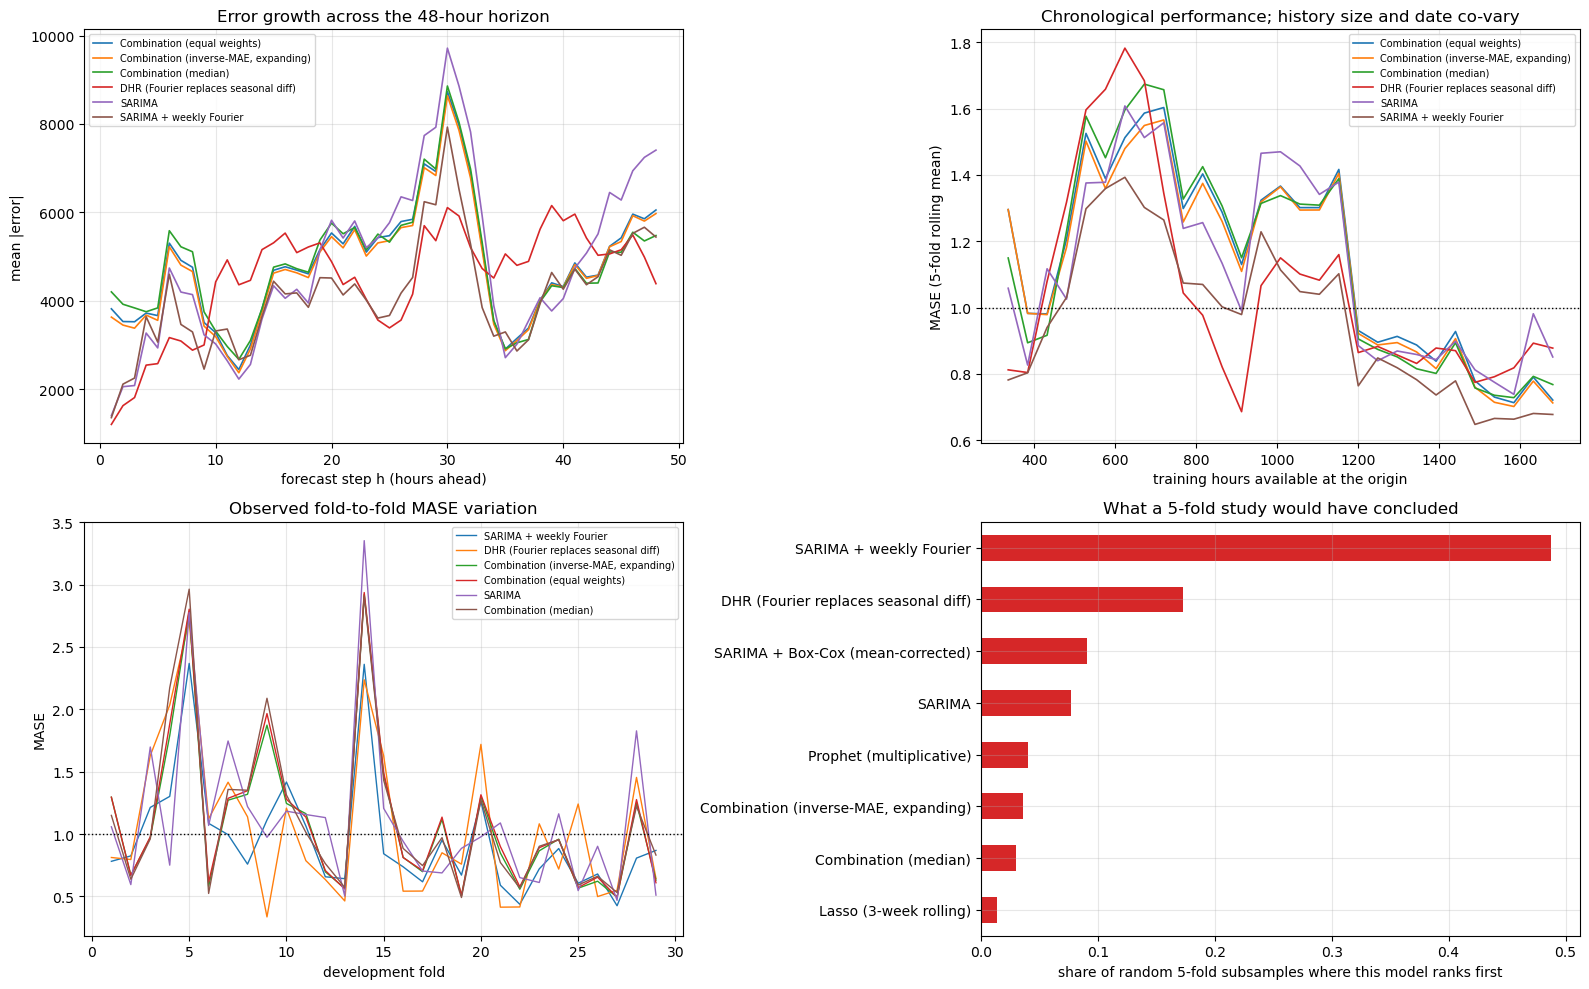

Across 3,000 random 5-fold subsamples, 'SARIMA + weekly Fourier' ranked first 49% of the time, and 19 different models took first place.
The full-sample-selected leader had naive paired-t p<0.05 in 28.9% of those subsamples.

horizon decay (mean |error|, first vs last 12 hours):
   SARIMA + weekly Fourier                         2,963 ->    4,697   (1.6x)
   DHR (Fourier replaces seasonal diff)            2,966 ->    5,329   (1.8x)
   Combination (inverse-MAE, expanding)            3,674 ->    4,847   (1.3x)
   Combination (equal weights)                     3,767 ->    4,884   (1.3x)
   SARIMA                                          2,993 ->    5,423   (1.8x)
   Combination (median)                            4,012 ->    4,653   (1.2x)


In [41]:
SHORTLIST = [m for m in rank.index[:6]]
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# (a) error growth across the horizon
dec = (curves_all[curves_all["model"].isin(SHORTLIST)]
       .groupby(["model", "h"])["abs_err"].mean().unstack(0))
dec.plot(ax=axes[0,0], lw=1.2)
axes[0,0].set_xlabel("forecast step h (hours ahead)"); axes[0,0].set_ylabel("mean |error|")
axes[0,0].set_title("Error growth across the 48-hour horizon"); axes[0,0].legend(fontsize=7)

# (b) chronological trajectory: calendar time and training size are confounded
lc = master[master["model"].isin(SHORTLIST)]
for m, g in lc.groupby("model"):
    g = g.sort_values("n_train")
    axes[0,1].plot(g["n_train"], g["MASE"].rolling(5, min_periods=1).mean(), label=m, lw=1.2)
axes[0,1].axhline(1.0, color="black", ls=":", lw=1)
axes[0,1].set_xlabel("training hours available at the origin")
axes[0,1].set_ylabel("MASE (5-fold rolling mean)")
axes[0,1].set_title("Chronological performance; history size and date co-vary"); axes[0,1].legend(fontsize=7)

# (c) MASE by fold
loss[SHORTLIST].plot(ax=axes[1,0], lw=1.0)
axes[1,0].axhline(1.0, color="black", ls=":", lw=1)
axes[1,0].set_xlabel("development fold"); axes[1,0].set_ylabel("MASE")
axes[1,0].set_title("Observed fold-to-fold MASE variation"); axes[1,0].legend(fontsize=7)

# (d) what a 5-fold study would have concluded
rng = np.random.default_rng(SEED)
winners, sig_any = [], 0
for _ in range(3000):
    pick = rng.choice(loss.index.to_numpy(), size=5, replace=False)
    sub = loss.loc[pick]
    winners.append(sub.mean().idxmin())
    d = (sub[rank.index[0]] - sub[BENCHMARK]).to_numpy()
    if sps.ttest_rel(sub[rank.index[0]], sub[BENCHMARK])[1] < 0.05: sig_any += 1
wc = pd.Series(winners).value_counts(normalize=True).head(8)
wc.sort_values().plot(kind="barh", ax=axes[1,1], color="C3")
axes[1,1].set_xlabel("share of random 5-fold subsamples where this model ranks first")
axes[1,1].set_title("What a 5-fold study would have concluded")
plt.tight_layout(); plt.show()

print(f"Across 3,000 random 5-fold subsamples, {wc.index[0]!r} ranked first "
      f"{wc.iloc[0]:.0%} of the time, and {len(set(winners))} different models took first place.")
print(f"The full-sample-selected leader had naive paired-t p<0.05 in {sig_any/3000:.1%} of those subsamples.")
print(f"\nhorizon decay (mean |error|, first vs last 12 hours):")
for m in SHORTLIST:
    g = dec[m]; print(f"   {m:<44s} {g.iloc[:12].mean():>8,.0f} -> {g.iloc[-12:].mean():>8,.0f}"
                      f"   ({g.iloc[-12:].mean()/g.iloc[:12].mean():.1f}x)")

### What the Comparisons Taught Me

The development comparison addressed three questions: which procedure had
the lowest average loss, how consistently it improved on the benchmark, and
how sensitive the ranking was to the forecast occasions included.

The selected **SARIMA + weekly Fourier** procedure achieved mean development
MASE **0.954947** and lower loss than the **24-hour seasonal-naive benchmark
on 25 of 29 paths**.

Its paired comparison with the benchmark was:

| Quantity | Observed result |
|---|---:|
| Mean paired MASE difference | Approximately **−0.438** |
| HAC p-value | **< 0.0001** |
| Nominal 95% basic bootstrap interval | **[−0.558, −0.306]** |

The negative difference favors the weekly-Fourier procedure. It represents
approximately **0.438 fewer MASE units per fold on average**, rather than
a percentage reduction in error.

The win count and mean difference describe different aspects of the result:
the advantage occurred on most evaluated paths, and the average paired
difference also favored the selected procedure. The bootstrap interval lay
entirely below zero under the implemented calculation.

These findings support its observed development advantage. Their inferential
interpretation remains subject to the dependence, bootstrap, and adaptive
selection qualifications explained above.

### Which Other Procedures Remained Competitive?

At the displayed **Holm-adjusted 0.05 criterion**, six configurations had
lower observed mean MASE than seasonal naive and five had higher observed
mean MASE. The comparisons therefore identified evidence in both directions
within the specified testing family.

The nominal **90% Model Confidence Set** retained:

| Procedure | Displayed MCS p-value |
|---|---:|
| `SARIMA + weekly Fourier` | **1.0000** |
| `DHR (Fourier replaces seasonal diff)` | **0.1380** |

Membership remained unchanged across the examined block lengths:
**2, 3, 4, 6, and 8 folds**. This describes stability with respect to those
settings; it does not verify the bootstrap assumptions.

The final survivor's p-value of 1 is an implementation convention, not
certainty that it is best. Retaining both procedures also does not establish
equal forecasting risks or practical equivalence. I interpret the surviving
pair alongside their observed losses and the exploratory nature of the study.

### How Sensitive Was the Ranking to the Target Occasions?

I reused the stored development losses to draw **3,000 random five-fold
subsets**, without refitting the models. Each draw contained five distinct
folds, but different draws could overlap.

For each subset, I recalculated the ranking across all procedures and
compared the fixed, full-sample-selected leader with seasonal naive.

| Subset-analysis result | Observed value |
|---|---:|
| Subsets where the weekly-Fourier leader ranked first | **49%** |
| Different procedures ranked first at least once | **19** |
| Subsets where the leader's naive paired-t p-value was below 0.05 | **28.9%** |

A procedure can have the lowest average loss across all 29 paths while being
outperformed on many smaller collections of forecast occasions. These results
show how much the observed ordering could change when evaluation was reduced
to five paths.

The exercise reused observed losses, did not preserve contiguous temporal
blocks, and kept the leader selected from the complete development sample.
Consequently, **49% is not a probability of future first-place performance**,
and **28.9% is not an estimate of prospective statistical power**. Both are
descriptive sensitivity results for this particular loss matrix.

### How Did Error Vary Across the Forecast Horizon?

Averaged across development paths, the selected procedure's absolute errors
were larger in the final 12 hours than in the first 12:

| Horizon segment | Mean absolute error, in ads watched |
|---|---:|
| Hours 1–12 | Approximately **2,963** |
| Hours 37–48 | Approximately **4,697** |

This describes poorer average accuracy in the later segment. The full
horizon-error curve was **not monotonically increasing**, so it does not
show deterioration at every successive hour. Calendar position and the
observations being predicted also differ across horizon steps.

### What Did the Training-History Plot Show?

The performance plot against available training history uses a five-fold
rolling mean of MASE. As history grows, the forecast date also advances.

It therefore mixes changes in training-sample size with changes in the
evaluation period. Target difficulty, series level, temporal structure, and
the origin-specific MASE scaling denominator may also change.

I interpret this plot as a **chronological performance trajectory**, rather
than an isolated learning curve measuring the benefit of additional data.
The earlier rolling-window comparisons provide more targeted evidence about
window choices for their particular estimators at matched forecast origins.

### The Numerically Sensitive SARIMA Box–Cox Mean-Corrected Procedure

For `SARIMA + Box-Cox (mean-corrected)`, the current comparison against
seasonal naive gave:

| Quantity | Observed result |
|---|---:|
| Mean paired MASE difference | **−0.199** |
| HAC p-value | **0.0841** |
| Holm-adjusted p-value | **1.0000** |
| BH-adjusted p-value | **0.1991** |
| Nominal 95% basic bootstrap interval | **[−0.414, +0.013]** |

Its observed average loss was lower than the benchmark's, but neither the
HAC nor adjusted p-values met the 0.05 criterion, and the bootstrap interval
included zero.

Section 8 also documented cross-execution changes in the transformed-model
comparisons, including this mean arm's inference. The numerical cause was
not established. I therefore retain the current results without claiming
stable superiority.

Including zero establishes neither an absent effect nor practical
equivalence. It leaves uncertainty about the mean difference under the
implemented inference procedure. Moreover, as Section 8 showed, the
mean-corrected transformed procedure still had higher development MASE
than untransformed SARIMA.

## Section 14: Historical Temporal Validation

I evaluated the selected procedures over **six later, nonoverlapping
48-hour forecast paths**.

I had already examined these validation outcomes during the broader research.
This section therefore extends the descriptive comparison to a later period;
it does not provide an untouched confirmatory test of the entire development
process. **Chronological separation does not establish independence from
earlier research decisions.**

### Which Procedures Entered the Comparison?

Within the implemented run, development results determine the winner and
shortlist before validation begins.

The reported comparison contains **four procedures**:

| Procedure | Reason for inclusion |
|---|---|
| `SARIMA + weekly Fourier` | Lowest mean development MASE; retained by the MCS |
| `DHR (Fourier replaces seasonal diff)` | Retained by the MCS |
| `Seasonal naive (24h)` | Benchmark |
| `Combination (equal weights)` | Designated combination candidate |

Generating the combination requires forecasts from its component pool.
Consequently, the implementation refits **11 individual configurations at
each origin**, including **eight supporting configurations** that are not
individually ranked.

The equal-weight combination is constructed from component predictions and
appears as one shortlisted procedure. Supporting component fits do not
automatically become additional candidates in the reported ranking or
statistical comparison.

This ordering defines the implemented workflow. It does not undo the
researcher's earlier exposure to the validation outcomes.

### Refitting as New Observations Become Available

At each validation origin $o_i$, the required procedures receive the
observations available through that point:

$$
\mathcal H_i=\{y_t:t\le o_i\}.
$$

They then forecast the next **48 hours**, using no actual target observations
from that upcoming path.

Once an earlier validation path has elapsed, its observations can enter the
training history for a later origin. This is **expanding-history
rolling-origin evaluation**: the forecasting rules stay fixed while their
fitted states update as observations become available.

Using earlier validation observations in later refits respects the
information available at each forecast's issuance. It differs from using
validation scores to redesign or select the forecasting rules.

A fixed rule need not have fixed fitted parameters or a fixed selected
configuration. For example, the weekly-Fourier procedure repeats its
prespecified AIC comparison on each origin's training history. That
training-based selection remains part of the forecasting procedure.

Within this evaluation:

- Winner and shortlist selection remain development-derived.
- The shortlisted combination retains equal weights.
- The additional inverse-MAE combination calculation uses development
  losses for its weights and is excluded from the reported shortlist.
- Validation scores do not change these selection or weighting rules.

### Uncertainty Calibration Remains Development-Based

Although point-forecast models are refitted at later origins, the uncertainty
calculations retain their development-based calibration.

The interval scales, calibration scores, and signed-residual predictive
ensembles are derived only from development residuals and kept fixed
throughout validation. Validation residuals are not added to those objects.

This separates **updating the forecasting model with newly available
observations** from **updating uncertainty calibration using evaluation
errors**.

### What Can Six Validation Paths Tell Us?

The paired comparisons contain **six fold-level MASE differences**, rather
than 288 independent hourly observations. Dependence may remain both within
and between forecast paths.

I retained ordinary paired-t tests and applied **Holm adjustment to the
three shortlisted comparisons against seasonal naive**. Their interpretation
is limited by the small number of paths, possible dependence, and prior
exposure to the outcomes.

Holm adjustment addresses the specified testing family when the underlying
p-values are valid. It does not repair unsuitable test assumptions or account
for the complete adaptive research history. I therefore read these statistics
alongside the observed losses and path-level differences.

A previously unexamined later block, evaluated under a protocol fixed before
its outcomes are inspected, could provide new evidence. It could come from
the same series. That protocol would specify the candidates, refitting and
selection rules, weighting rules, calibration procedure, metrics, and
reporting decisions in advance.

In [42]:
# PREREGISTERED is the retained identifier for a development-derived shortlist.
# The within-run order does not undo historical validation exposure. Pool refits build combinations.
assert "PREREGISTERED" in dir() and "FINAL_MODEL" in dir(), "shortlist must be frozen in Section 13"
# Pool members are refit only because the combination cannot be built without them. They are
# NOT candidates: their individual validation scores are excluded from the published ranking
# and from the multiplicity family below.
TEST_MODELS = sorted(PREREGISTERED | set(COMBINATION_POOL))
TEST_MODELS = [m for m in TEST_MODELS if m in MODEL_REGISTRY]
print(f"Development-derived frozen shortlist: {sorted(PREREGISTERED)}")
print(f"refitting {len(TEST_MODELS)} models at {len(TEST_FOLDS)} validation origins "
      f"(shortlist + the pool required to build the combination)\n")

test_results, test_curves = {}, {}
t0 = time.time()
for m in TEST_MODELS:
    s, c = _run(MODEL_REGISTRY[m], m, TEST_FOLDS)
    test_results[m], test_curves[m] = s, c
    print(f"  {m:<44s} val MASE {s['MASE'].mean():.3f}")
print(f"\n[{time.time()-t0:.0f}s]")

Development-derived frozen shortlist: ['Combination (equal weights)', 'DHR (Fourier replaces seasonal diff)', 'SARIMA + weekly Fourier', 'Seasonal naive (24h)']
refitting 11 models at 6 validation origins (shortlist + the pool required to build the combination)

  DHR (Fourier replaces seasonal diff)         val MASE 1.230
  Holt-Winters                                 val MASE 1.418
  Lasso                                        val MASE 1.298
  Linear Regression                            val MASE 1.296
  PLS (supervised)                             val MASE 1.286
  Prophet                                      val MASE 1.230
  Ridge                                        val MASE 1.295
  SARIMA                                       val MASE 1.251
  SARIMA + weekly Fourier                      val MASE 1.016
  Seasonal naive (24h)                         val MASE 1.319
  XGBoost (absolute-error objective)           val MASE 1.552

[858s]


In [43]:
# Combinations on the test folds, using exactly the rules fixed in Section 11.
# Inverse-MAE weights come from the DEVELOPMENT folds only -- never from test performance.
pool_test = [m for m in COMBINATION_POOL if m in test_curves]
Pt = (pd.concat([test_curves[m] for m in pool_test], ignore_index=True)
        .pipe(_assert_unique).pivot(index=["fold", "h"], columns="model", values="pred")[pool_test])
truth_t = test_curves[pool_test[0]].set_index(["fold", "h"])["actual"].reindex(Pt.index)
w_dev = np.array([1.0 / dev_results[m]["MAE"].mean() for m in pool_test]); w_dev /= w_dev.sum()

for kind, name in [("equal", "Combination (equal weights)"),
                   ("median", "Combination (median)"),
                   ("invmae", "Combination (inverse-MAE, expanding)")]:
    rows, curves = [], []
    for fd in sorted(Pt.index.get_level_values("fold").unique()):
        blk = Pt.xs(fd, level="fold")
        p = (blk.mean(axis=1).to_numpy() if kind == "equal" else
             blk.median(axis=1).to_numpy() if kind == "median" else blk.to_numpy() @ w_dev)
        act = truth_t.xs(fd, level="fold").to_numpy()
        r = TEST_FOLDS.set_index("fold").loc[fd]
        rows.append({"model": name, "fold": fd, "block": "test",
                     "n_train": int(r["n_train"]), **point_scores(act, p, mase_scale(df.loc[df.index < r['validation_start']]))})
        curves.append(pd.DataFrame({"model": name, "fold": fd, "block": "test",
                                    "ds": pd.date_range(r["validation_start"], periods=len(p), freq="h"),
                                    "h": np.arange(1, len(p)+1), "actual": act, "pred": p,
                                    "abs_err": np.abs(act - p)}))
    test_results[name] = pd.DataFrame(rows); test_curves[name] = pd.concat(curves, ignore_index=True)

# Restrict reporting to the frozen candidate set. Everything else was fitted as combination
# machinery and are outside the frozen published candidate set.
published = PREREGISTERED | {COMBINATION_CANDIDATE}
test_master = pd.concat(test_results.values(), ignore_index=True)
test_master = test_master[test_master["model"].isin(published)]
print(f"published candidates ({len(published)}): {sorted(published)}")
print(f"fitted as combination machinery, excluded from the published ranking/comparison: "
      f"{sorted(set(test_results) - published)}\n")
final = (test_master.groupby("model").agg(val_MASE=("MASE", "mean"), test_MAE=("MAE", "mean"))
         .join(rank[["MASE_mean"]].rename(columns={"MASE_mean": "dev_MASE"}))
         .assign(in_MCS=lambda d: d.index.isin(mcs_set))
         .sort_values("val_MASE"))
final["dev_rank"] = final["dev_MASE"].rank().astype("Int64")
final["val_rank"] = final["val_MASE"].rank().astype(int)
display(final.round(3).style.set_caption("Previously exposed temporal validation: descriptive results"))
print(f"rank correlation between development and test: "
      f"{final['dev_MASE'].corr(final['val_MASE'], method='spearman'):.3f} (Spearman)")
# Read-only result reporting.
_c_show_candidate_counts(TEST_MODELS, published, test_results)


published candidates (4): ['Combination (equal weights)', 'DHR (Fourier replaces seasonal diff)', 'SARIMA + weekly Fourier', 'Seasonal naive (24h)']
fitted as combination machinery, excluded from the published ranking/comparison: ['Combination (inverse-MAE, expanding)', 'Combination (median)', 'Holt-Winters', 'Lasso', 'Linear Regression', 'PLS (supervised)', 'Prophet', 'Ridge', 'SARIMA', 'XGBoost (absolute-error objective)']



,val_MASE,test_MAE,dev_MASE,in_MCS,dev_rank,val_rank
model,,,,,,
SARIMA + weekly Fourier,1.016000,4657.369000,0.955000,True,1,1
Combination (equal weights),1.106000,5067.558000,1.116000,False,3,2
DHR (Fourier replaces seasonal diff),1.230000,5632.802000,1.048000,True,2,3
Seasonal naive (24h),1.319000,6032.656000,1.393000,False,4,4


rank correlation between development and test: 0.800 (Spearman)
Counts distinguish refits from derived combinations and the published candidate set:


,count
registered configurations refitted,11
published candidates,4
refitted supporting configurations only,8
constructed combinations,3
constructed combinations not published,2


Supporting refits: ['Holt-Winters', 'Lasso', 'Linear Regression', 'PLS (supervised)', 'Prophet', 'Ridge', 'SARIMA', 'XGBoost (absolute-error objective)']


In [44]:
# Retained exploratory paired comparison; small dependent paths and prior exposure limit inference.
bt = test_master.pivot(index="fold", columns="model", values="MASE")
rows = []
for m in bt.columns:
    if m == BENCHMARK or m not in published: continue
    d = (bt[m] - bt[BENCHMARK]).to_numpy()
    t, p = sps.ttest_rel(bt[m], bt[BENCHMARK])
    rows.append({"model": m, "mean_dMASE": d.mean(), "better_in": int((d < 0).sum()),
                 "of": len(d), "p_paired_t": p})
test_paired = pd.DataFrame(rows).sort_values("mean_dMASE").reset_index(drop=True)
# Multiplicity family = the frozen candidates only; pool members were never candidates.
test_paired["p_holm"] = multipletests(test_paired["p_paired_t"], method="holm")[1]
display(show_p(test_paired.round({"mean_dMASE": 4}), ["p_paired_t", "p_holm"]))
print(f"\nInterpret {len(bt)} dependent validation paths descriptively; achieved power is not established.")
print("Nonsignificance is not equivalence. Prior exposure and adaptive research limit nominal inference.")
print("Section 13 is also exploratory; its power is not established by the iid illustration.")

,model,mean_dMASE,better_in,of,p_paired_t,p_holm
0,SARIMA + weekly Fourier,-0.302800,4,6,0.3150,0.9449
1,Combination (equal weights),-0.212900,4,6,0.4217,0.9449
2,DHR (Fourier replaces seasonal diff),-0.088900,4,6,0.7128,0.9449



Interpret 6 dependent validation paths descriptively; achieved power is not established.
Nonsignificance is not equivalence. Prior exposure and adaptive research limit nominal inference.
Section 13 is also exploratory; its power is not established by the iid illustration.


In [45]:
# Validation intervals: calibration FROZEN on development folds only. No validation residual
# enters the scale or the calibration scores, and the calibration set is fixed before the first
# validation fold is scored.
def validation_intervals(model_name, alphas=ALPHA_LEVELS, n_scale=N_SCALE_FOLDS):
    R = residual_matrix(dev_curves[model_name])
    scale, cal = _split(R, n_scale)          # raises if calibration would be empty
    assert len(cal) >= 2, "validation calibration block must be non-empty"
    Rs = residual_matrix(dev_curves[model_name], signed=True)[n_scale:]   # for the CRPS ensemble

    path_hit = {a: [] for a in alphas}
    pt_hit   = {a: [] for a in alphas}
    pt_width = {a: [] for a in alphas}
    pt_iscore= {a: [] for a in alphas}
    crps_vals = []
    for fold, g in test_curves[model_name].groupby("fold", sort=True):
        g = g.sort_values("h")
        pred, act = g["pred"].to_numpy(), g["actual"].to_numpy()
        pb, _ = path_bands(pred, scale, cal, alphas)
        qb, _ = pointwise_bands(pred, cal, alphas)
        for a in alphas:
            lo, hi = pb[a]
            if np.isfinite(hi).all():
                path_hit[a].append(bool(np.all((act >= lo) & (act <= hi))))
            lo, hi = qb[a]
            if np.isfinite(hi).all():
                pt_hit[a].append((act >= lo) & (act <= hi))
                pt_width[a].append((hi - lo) / 2)
                pt_iscore[a].append(interval_score(act, lo, hi, a))
        # CRPS of the EMPIRICAL SIGNED-RESIDUAL PREDICTIVE DISTRIBUTION at each horizon:
        # the ensemble pred_h + {signed development residuals at h}. This evaluates that
        # predictive distribution -- NOT the conformal bands above, which are a separate
        # construction. Always finite, unlike a conformal rank beyond what calibration supports.
        crps_vals.append(np.mean([ensemble_crps(act[h], pred[h] + Rs[:, h]) for h in range(len(act))]))

    rows = []
    for a in alphas:
        rows.append({
            "model": model_name, "nominal": f"{int((1-a)*100)}%",
            "path_coverage": float(np.mean(path_hit[a])) if path_hit[a] else np.nan,
            "pointwise_coverage": float(np.mean(np.vstack(pt_hit[a]))) if pt_hit[a] else np.nan,
            "pointwise_half_width": float(np.mean(np.vstack(pt_width[a]))) if pt_width[a] else np.nan,
            "interval_score": float(np.mean(pt_iscore[a])) if pt_iscore[a] else np.nan})
    return pd.DataFrame(rows), float(np.mean(crps_vals)), len(cal)

def validation_pointwise_band(model_name, alpha=0.2, n_scale=N_SCALE_FOLDS):
    """Per-fold pointwise band for plotting, using the same frozen development calibration."""
    R = residual_matrix(dev_curves[model_name])
    scale, cal = _split(R, n_scale)
    out = {}
    for fold, g in test_curves[model_name].groupby("fold", sort=True):
        g = g.sort_values("h"); pred = g["pred"].to_numpy()
        qb, _ = pointwise_bands(pred, cal, [alpha])
        out[fold] = {"h": g["h"].to_numpy(), "lo": qb[alpha][0], "hi": qb[alpha][1]}
    return out

band_targets = [m for m in dict.fromkeys([FINAL_MODEL, "Combination (equal weights)"])
                if m in test_curves]
val_tabs, crps_rows = [], []
for m in band_targets:
    tab, crps, n_cal = validation_intervals(m)
    val_tabs.append(tab); crps_rows.append({"model": m, "CRPS": crps, "n_calibration": n_cal})
val_intervals = pd.concat(val_tabs, ignore_index=True)

print(f"Calibration frozen on {crps_rows[0]['n_calibration']} development fold-paths; no validation")
print("residual enters the scale, the calibration scores, or the CRPS ensemble.\n")
print(f"RESOLUTION: path coverage is measured over {len(TEST_FOLDS)} validation paths, so it can only")
print(f"take values in multiples of 1/{len(TEST_FOLDS)} = {100/len(TEST_FOLDS):.1f} percentage points.")
print(f"Pointwise coverage has finer NUMERICAL granularity (1/{48*len(TEST_FOLDS)}), but that is not")
print(f"{48*len(TEST_FOLDS)} independent observations: the 48 hours inside a path are strongly")
print(f"dependent; there are {len(TEST_FOLDS)} path clusters, not a known effective sample size. The")
print("uncertainty also depends on dependence between paths; no coverage confidence interval is computed.\n")
display(val_intervals.pivot(index="model", columns="nominal",
                            values=["path_coverage", "pointwise_coverage"]).round(3).fillna("n/a"))
display(val_intervals.pivot(index="model", columns="nominal",
                            values=["pointwise_half_width", "interval_score"]).round(0).fillna("n/a"))
print("\nCRPS of the empirical signed-residual predictive distribution (ads watched; lower is")
print("better). This scores that ensemble, not the path or pointwise bands reported above.")
display(pd.DataFrame(crps_rows).round({"CRPS": 0}))

Calibration frozen on 21 development fold-paths; no validation
residual enters the scale, the calibration scores, or the CRPS ensemble.

RESOLUTION: path coverage is measured over 6 validation paths, so it can only
take values in multiples of 1/6 = 16.7 percentage points.
Pointwise coverage has finer NUMERICAL granularity (1/288), but that is not
288 independent observations: the 48 hours inside a path are strongly
dependent; there are 6 path clusters, not a known effective sample size. The
uncertainty also depends on dependence between paths; no coverage confidence interval is computed.



path_coverage                pointwise_coverage  \
nominal                               50%  80%  90%  95%                50%   
model                                                                         
Combination (equal weights)         0.333  1.0  1.0  1.0              0.427   
SARIMA + weekly Fourier             0.167  1.0  1.0  1.0              0.427   

                                                  
nominal                        80%    90%    95%  
model                                             
Combination (equal weights)  0.760  0.941  0.993  
SARIMA + weekly Fourier      0.708  0.885  0.983

pointwise_half_width                            \
nominal                                      50%     80%      90%      95%   
model                                                                        
Combination (equal weights)               3594.0  8312.0  11768.0  16748.0   
SARIMA + weekly Fourier                   3363.0  6553.0   9770.0  14423.0   

                            interval_score                             
nominal                                50%      80%      90%      95%  
model                                                                  
Combination (equal weights)        16464.0  21287.0  24509.0  33999.0  
SARIMA + weekly Fourier            14575.0  19637.0  23363.0  29664.0


CRPS of the empirical signed-residual predictive distribution (ads watched; lower is
better). This scores that ensemble, not the path or pointwise bands reported above.


,model,CRPS,n_calibration
0,SARIMA + weekly Fourier,3057.0,21
1,Combination (equal weights),3478.0,21


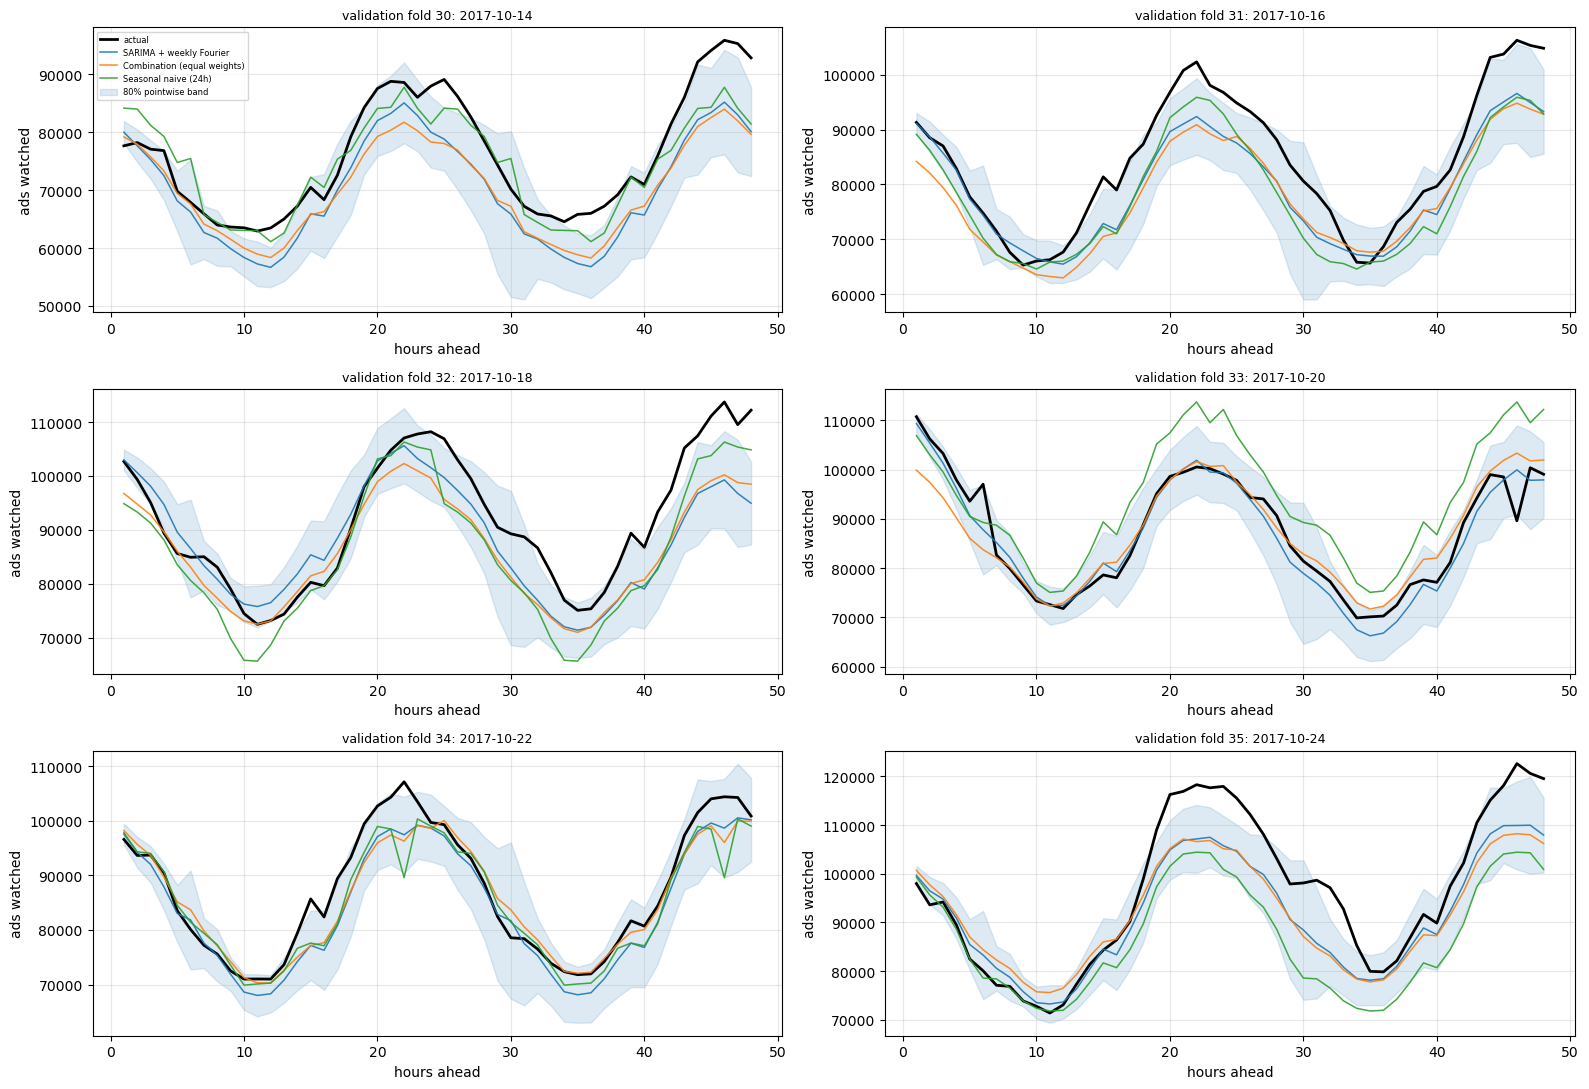

In [46]:
fig, axes = plt.subplots(3, 2, figsize=(16, 11))
show = [m for m in dict.fromkeys([FINAL_MODEL, "Combination (equal weights)", BENCHMARK])
        if m in test_curves]
ref = band_targets[0]
bands = validation_pointwise_band(ref, alpha=0.2)

for ax, fd in zip(axes.ravel(), sorted(TEST_FOLDS["fold"])):
    s0 = test_curves[show[0]]
    s0 = s0[s0["fold"] == fd].sort_values("h")
    ax.plot(s0["h"], s0["actual"], color="black", lw=2, label="actual")
    for m in show:
        g = test_curves[m]
        g = g[g["fold"] == fd].sort_values("h")
        ax.plot(g["h"], g["pred"], lw=1.1, alpha=0.9, label=m)
    if fd in bands:
        bnd = bands[fd]
        ax.fill_between(bnd["h"], bnd["lo"], bnd["hi"], alpha=0.15, color="C0",
                        label="80% pointwise band")
    start = TEST_FOLDS.set_index("fold").loc[fd, "validation_start"]
    ax.set_title(f"validation fold {fd}: {start.date()}", fontsize=9)
    ax.set_xlabel("hours ahead"); ax.set_ylabel("ads watched")
axes[0, 0].legend(fontsize=6)
plt.tight_layout(); plt.show()

### Point Accuracy and Uncertainty Gave Different Answers

The weekly-Fourier procedure again had the lowest mean MASE among the
four reported validation candidates:

| Procedure | Mean validation MASE |
|---|---:|
| **SARIMA + weekly Fourier** | **1.016** |
| Equal-weight combination | 1.106 |
| DHR (Fourier replaces seasonal diff) | 1.230 |
| Seasonal naive (24h) | 1.319 |

It beat seasonal naive on **four of six paths**. Its paired-t p-value was
**0.3150**, and the Holm-adjusted value was **0.9449**.

The observed average difference favored the weekly-Fourier procedure, but
the population contrast remains unresolved. Nonsignificance does not establish
equivalence, and these results do not identify low power as its sole explanation.
The six potentially dependent paths and prior exposure to their outcomes
limit formal interpretation.

### Why Could MASE Exceed One While Beating Seasonal Naive?

MASE divides each path's forecasting MAE by a scale calculated from its
training history:

$$
\operatorname{MASE}_i
=\frac{\operatorname{MAE}_i}{c_i},
\qquad
c_i=\frac{1}{n_i-24}
\sum_{t=25}^{n_i}|y_t-y_{t-24}|,
$$

where $n_i$ is the number of historical observations available at origin $i$.

The denominator summarizes **historical lag-24 absolute differences**.
It is not the seasonal-naive procedure's actual MAE on the upcoming
48-hour path.

Consequently, MASE above one does not automatically imply worse performance
than the explicitly evaluated seasonal-naive forecast. Here, the procedures
shared the origin-specific scaling denominators, and the weekly-Fourier
procedure's mean MASE of **1.016** was lower than the benchmark's **1.319**.

### What Happened to Prediction-Interval Coverage?

Calibration scores and the signed-residual predictive ensemble remained
frozen on **21 development paths**, with no validation residuals added.
Point models continued to be refitted at each origin.

This design requires development errors to remain informative about later
forecast errors; chronological separation alone does not establish that
transfer.

| Validation summary | Weekly-Fourier SARIMA | Equal-weight combination |
|---|---:|---:|
| Pointwise coverage, nominal 80% | **70.83% (204/288)** | **76.04% (219/288)** |
| Mean half-width, 80% interval | 6,553 | 8,312 |
| Interval score, 80% interval | **19,637** | 21,287 |
| Signed-residual ensemble CRPS | **3,057** | 3,478 |

The coverage counts are uniquely recoverable from the saved three-decimal
rates, **0.708** and **0.760**, and the 288 scored hours. Widths and scores
retain the saved whole-unit precision; the complete four-level tables
remain above.

Both pointwise coverage rates fell below the nominal 80% target. This is
**empirical undercoverage in this evaluation**, rather than proof of a
persistent population coverage deficit.

### Why Higher Coverage Was Not the Only Criterion

The combination covered more hours, but its intervals were also wider.
The reported half-width is half the distance between the lower and upper
bounds.

To evaluate width and misses together, I used the interval score:

$$
IS_\alpha(l,u;y)
=(u-l)
+\frac{2}{\alpha}(l-y)\mathbf{1}(y<l)
+\frac{2}{\alpha}(y-u)\mathbf{1}(y>u).
$$

Here, $l$ and $u$ are the interval bounds, $y$ is the observation, and
$\mathbf{1}(\cdot)$ is an indicator. For nominal 80% coverage,
$\alpha=0.20$.

The first term penalizes width. If an observation falls outside the interval,
the score adds a penalty proportional to its distance beyond the relevant
bound. **Lower scores are better.**

Weekly-Fourier achieved the lower observed interval score despite covering
fewer hours. The combination's higher coverage therefore did not translate
into a better score on these targets. The aggregate summaries do not isolate
how much of the difference came from width versus miss penalties.

Conversely, the weekly procedure's better score does not remove its observed
undercoverage. Relative scoring performance and achievement of nominal
coverage are separate questions.

### What Did CRPS Evaluate?

CRPS evaluated a **different uncertainty construction**: an empirical
signed-residual predictive distribution.

At each horizon $h$, the implementation used all 21 calibration residuals
to form equally weighted ensemble members:

$$
x_{j,h}=\hat y_h+R^{\mathrm{dev}}_{j,h},
\qquad j=1,\ldots,21,
$$

where $R^{\mathrm{dev}}_{j,h}$ is an actual-minus-forecast development
residual. Positive residuals represent underprediction; negative residuals
represent overprediction.

This construction retains the observed signs and asymmetry of the historical
residuals. The absolute-residual bands instead use error magnitudes to set
symmetric distances around the point forecast.

CRPS scores the full empirical predictive distribution, rather than one
pair of interval bounds. Weekly-Fourier had the lower observed CRPS,
**3,057 versus 3,478**, but that result does not establish calibration of
its separate absolute-residual intervals.

No confidence intervals for the score differences or coverage rates were
computed, so these comparisons remain descriptive.

### Why the Direction of the Misses Matters

The validation plots show several pronounced **upper-sided misses**:
actual peaks exceeded the weekly-Fourier forecasts and their upper
pointwise limits.

A symmetric interval has equal geometric distances above and below its
forecast. That symmetry does not establish equal representation of the
two error tails.

The saved outputs do not provide exact directional-miss counts, and
full-precision hourly forecast arrays were not exported. I therefore
describe the pattern qualitatively, without assigning a directional
frequency or identifying its cause.

The coverage evaluation contains **six 48-hour paths**, rather than
288 independent coverage trials. Dependence may occur within and between
paths, and their effective sample size was not established.

At nominal 80%, the separate, wider simultaneous bands contained all six
paths. Those bands target whole-path containment. Their observed success
does not change the coverage achieved by the narrower pointwise intervals,
and six successes do not establish future reliability.

Development and validation also differed in target periods, rolling versus
frozen calibration, available paths, and model refits. Their coverage
difference cannot identify calibration drift or another single mechanism.

The central finding is therefore specific: **the procedure with the best
reported point accuracy covered 70.83% of validation hours with its nominal
80% pointwise intervals**. Its lower interval score and CRPS were favorable
comparisons, while operational uncertainty reliability remained unestablished.

### Development–Validation Ranking Consistency

The four reported candidates had the following rankings by mean MASE:

| Procedure | Development rank | Validation rank |
|---|---:|---:|
| SARIMA + weekly Fourier | 1 | 1 |
| DHR (Fourier replaces seasonal diff) | 2 | 3 |
| Equal-weight combination | 3 | 2 |
| Seasonal naive (24h) | 4 | 4 |

The weekly-Fourier procedure remained first and seasonal naive remained
fourth, while the middle two procedures exchanged positions.

For $m$ procedures without tied ranks, Spearman's rank correlation is

$$
\rho_s
=1-\frac{6\sum_{j=1}^{m}(\Delta r_j)^2}{m(m^2-1)},
$$

where $\Delta r_j$ is the difference between procedure $j$'s two ranks.
Here, $m=4$ and the squared differences sum to two:

$$
\rho_s=1-\frac{6(2)}{4(4^2-1)}=\mathbf{0.800}.
$$

This describes similar ordering across these two observed periods. It does
not measure the size of the forecasting improvements or establish that the
ranking will persist. Only four candidates were compared, and the validation
outcomes had already been examined during the broader research.

I kept the final selection tied to **mean development MASE**, preserving
the implemented selection rule without reopening it using validation scores.
That decision does not erase the earlier validation exposure.

## Section 15: Forecast Beyond the Observed Data

I next applied the selected **SARIMA(1,0,0)(0,1,1)[24] plus weekly Fourier
procedure** beyond the available observations.

The full-history refit used all **2,085 observations**, including the final
tail excluded from the evaluation targets. The saved dispatch record confirms
that `SARIMA + weekly Fourier` was both the selected procedure and the
procedure used to generate the final forecast.

### Refitting the Selected Procedure

The weekly Fourier regressors represent a recurring weekly component with
period **168 hours**. The SARIMA error model represents the remaining temporal
dynamics, including daily seasonal differencing at lag 24.

As in development, the procedure compared eligible fits with

$$
K\in\{2,3,4\}
$$

weekly harmonics and selected the lower-AIC configuration. Each harmonic
adds one sine and one cosine regressor, giving $2K$ Fourier columns.

The selection rule remained fixed while its fitted coefficients and selected
$K$ could change with the available history.

The saved final report does **not separately identify the selected value
of $K$**. I therefore report the selection procedure without substituting
the most frequently selected development value for the unreported final one.

### The Final Forecasting Period

| Forecast property | Timestamp or value |
|---|---|
| Final observed timestamp and forecast origin | **2017-10-28 20:00** |
| First forecast timestamp | **2017-10-28 21:00** |
| Last forecast timestamp | **2017-10-30 20:00** |
| Forecast horizon | **48 hours** |

The corresponding actual observations are unavailable in the project data.
This is therefore an application of the selected forecasting procedure,
rather than another measured accuracy result.

### Transferring Calibration to a Different Issue Time

The final forecast introduced a scheduling difference:

| Property | Development calibration and validation | Final forecast |
|---|---|---|
| Forecast origin clock time | 23:00 | 20:00 |
| First forecast-hour clock time | 00:00 | 21:00 |

The pointwise intervals use a separate historical absolute-residual threshold
$q_h$ for each forecast horizon:

$$
I_h=[\hat y_h-q_h,\ \hat y_h+q_h].
$$

During calibration, **horizon 1 corresponded to 00:00**. In the final forecast,
**horizon 1 corresponds to 21:00**. Matching the horizon therefore no longer
matches the clock hour.

If forecast-error distributions depend on clock hour or its interaction with
forecast distance, the historical threshold at a given horizon may transfer
imperfectly to the new schedule. Daily variation in the observations makes
this worth examining, but does not itself establish hour-specific differences
in forecast errors.

The final pointwise thresholds retained the **21 development calibration
paths following the initial eight paths**. Those first eight paths estimated
scales for the separate simultaneous-band construction; those scales do not
enter this final pointwise band.

I did not recalibrate for the 21:00 start time or evaluate transfer between
the two schedules. The construction therefore assumes that the historical
horizon-specific errors remain informative under the new issue schedule.

The accompanying nominal 80% intervals remain **empirical uncertainty
estimates**. Their interpretation includes the observed validation
undercoverage, the absence of an established distribution-free coverage
guarantee, and this additional schedule-transfer assumption. With no final
actuals available, their realized coverage is also unknown.

All timestamps follow the dataset's **timezone-naive clock**; no geographical
timezone or UTC offset is specified.

Deployment dispatch: {'selected_model': 'SARIMA + weekly Fourier', 'deployed_model': 'SARIMA + weekly Fourier', 'rule': 'individual', 'components': ['SARIMA + weekly Fourier'], 'weights': None, 'weight_source': None, 'n_train': 2085, 'horizon': 48}


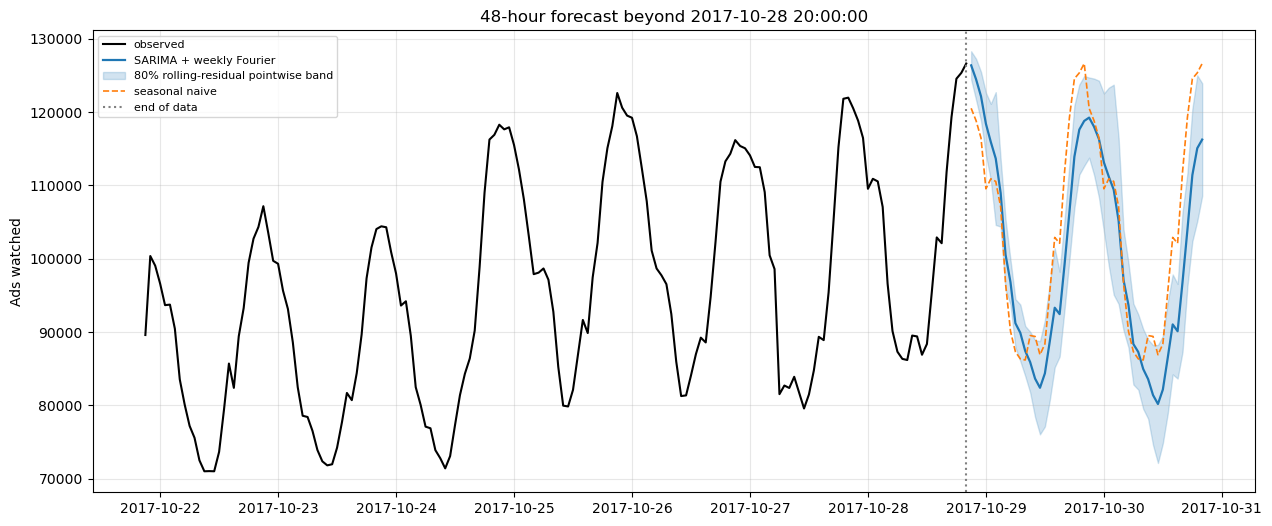

forecast model     : SARIMA + weekly Fourier
horizon            : 2017-10-28 21:00:00 -> 2017-10-30 20:00:00
point range        : 80,180 to 126,393
mean 80% half-width: 6,553  (from 21 calibration paths)
all values finite and positive: True


,computed value
point forecast minimum,80179.516281
point forecast maximum,126392.848154
mean pointwise half-width,6553.095108
calibration paths,21
benchmark steps inside pointwise band,24
forecast steps,48
benchmark containment fraction,0.5
entire benchmark path inside pointwise band,False
calibration origin hours,[23]
deployment origin hour,20


Benchmark containment is not actual future coverage or evidence of forecast equivalence.
A new origin hour requires an unverified transfer assumption for these horizon-specific bands.


In [47]:
# Selected-specification deployment dispatch.
"""Deploy the selected specification with development-only weights.

This helper is embedded in the final forecast cell. It does not select a model,
change a registry, update weights from validation, or fit anything on import.
"""
import numpy as np


DEPLOYMENT_COMBINATION_RULES = {
    "Combination (equal weights)": "equal",
    "Combination (median)": "median",
    "Combination (inverse-MAE, expanding)": "invmae",
}


def development_combination_weights(component_names, development_results):
    """The same inverse-mean-development-MAE rule already used for validation."""
    means = []
    for name in component_names:
        values = development_results[name]["MAE"].to_numpy(dtype=float)
        if not len(values) or not np.isfinite(values).all() or (values < 0).any():
            raise ValueError(f"Invalid development MAE values for {name!r}")
        mean = development_results[name]["MAE"].mean()
        if not mean > 0:
            raise ValueError(f"Inverse-MAE weights require positive development mean MAE: {name!r}")
        means.append(mean)
    weights = np.array([1.0 / mean for mean in means])
    total = weights.sum()
    if not np.isfinite(weights).all() or not np.isfinite(total) or not total > 0:
        raise ValueError("Development inverse-MAE weights are not finite and normalizable")
    weights /= total
    return weights


def deploy_selected_model(selected_name, train, forecast_dates, registry,
                          combination_pool, development_results):
    """Return the selected model's forecast and an explicit dispatch audit.

    Individual models call their registered forecaster exactly once. Combination
    components refit on the supplied complete observed history, once per member,
    in the established pool order. Inverse-MAE weights remain frozen on development
    losses, matching the existing validation rule. Unknown names never fall back.
    """
    horizon = len(forecast_dates)
    if not horizon:
        raise ValueError("Deployment requires nonempty forecast dates")

    def checked_forecast(name):
        forecast = np.asarray(registry[name](train, forecast_dates), dtype=float)
        if forecast.shape != (horizon,) or not np.isfinite(forecast).all():
            raise ValueError(f"{name!r}: expected {horizon} finite deployment predictions")
        return forecast

    if selected_name in DEPLOYMENT_COMBINATION_RULES:
        rule = DEPLOYMENT_COMBINATION_RULES[selected_name]
        members = list(combination_pool)
        if not members or len(members) != len(set(members)):
            raise ValueError("Deployment combination pool must be nonempty with unique identifiers")
        missing = [name for name in members if name not in registry]
        if missing:
            raise KeyError(f"Deployment combination components are not registered: {missing}")
        weights = (development_combination_weights(members, development_results)
                   if rule == "invmae" else
                   np.full(len(members), 1.0 / len(members)) if rule == "equal" else None)
        predictions = np.asarray([checked_forecast(name) for name in members])
        if rule == "equal":
            point = np.mean(predictions, axis=0)  # equal-weight combination
        elif rule == "median":
            point = np.median(predictions, axis=0)
        else:
            point = predictions.T @ weights
    elif selected_name in registry:
        rule, members, weights = "individual", [selected_name], None
        point = checked_forecast(selected_name)
    else:
        raise KeyError(f"Selected model has no supported deployment specification: {selected_name!r}")
    if point.shape != (horizon,) or not np.isfinite(point).all():
        raise ValueError(f"{selected_name!r}: combination produced invalid deployment predictions")
    audit = {
        "selected_model": selected_name, "deployed_model": selected_name, "rule": rule,
        "components": members,
        "weights": None if weights is None else dict(zip(members, map(float, weights))),
        "weight_source": "development mean MAE" if rule == "invmae" else
                         "equal weights" if rule == "equal" else None,
        "n_train": len(train), "horizon": horizon,
    }
    return point, audit

# FINAL_MODEL was frozen in Section 13 from development results. Re-deriving it here would
# reopen the door to validation-informed selection.
future = pd.date_range(df.index.max() + pd.Timedelta(hours=1), periods=HORIZON, freq="h")
point, deployment_audit = deploy_selected_model(
    FINAL_MODEL, df, future, MODEL_REGISTRY, COMBINATION_POOL, dev_results)
print("Deployment dispatch:", deployment_audit)
bench_fc = seasonal_naive(df, future)

# 80% POINTWISE construction: calibration scores follow the disjoint early scale block,
# although pointwise_bands does not use that scale. Transfer to a new origin hour is unverified.
# The quantile at each
# horizon is the finite-sample order statistic over one residual per fold. Pooling the 48
# horizons and taking a plain percentile would treat 48
# correlated hours as independent calibration observations and is not used.
src = dev_curves[FINAL_MODEL]
R_dep = residual_matrix(src)
scale_dep, cal_dep = _split(R_dep, N_SCALE_FOLDS)
qb_dep, n_cal_dep = pointwise_bands(point, cal_dep, [0.2])
lo, hi = qb_dep[0.2]
assert np.isfinite(hi).all(), "80% level unsupported by the calibration block"

plt.figure(figsize=(15, 6))
hist = df["y"].iloc[-24*7:]
plt.plot(hist.index, hist.to_numpy(), color="black", label="observed")
plt.plot(future, point, color="C0", lw=1.6, label=f"{FINAL_MODEL}")
plt.fill_between(future, lo, hi, color="C0", alpha=0.2, label="80% rolling-residual pointwise band")
plt.plot(future, bench_fc, color="C1", ls="--", lw=1.2, label="seasonal naive")
plt.axvline(df.index.max(), color="gray", ls=":", label="end of data")
plt.title(f"48-hour forecast beyond {df.index.max()}")
plt.ylabel("Ads watched"); plt.legend(fontsize=8); plt.show()

print(f"forecast model     : {FINAL_MODEL}")
print(f"horizon            : {future.min()} -> {future.max()}")
print(f"point range        : {point.min():,.0f} to {point.max():,.0f}")
print(f"mean 80% half-width: {np.mean(hi-lo)/2:,.0f}  (from {n_cal_dep} calibration paths)")
print(f"all values finite and positive: {np.all(np.isfinite(point)) and np.all(point > 0)}")
# Read-only result reporting.
_c_show_forecast(point, bench_fc, lo, hi, n_cal_dep, future, DEV_FOLDS)


### Final Forecast Results and Comparison with Seasonal Naive

The final forecast covers **2017-10-28 21:00 through 2017-10-30 20:00**.

| Final forecast summary | Value |
|---|---:|
| Minimum point forecast | Approximately **80,180** |
| Maximum point forecast | Approximately **126,393** |
| Mean nominal 80% pointwise half-width | Approximately **6,553** |
| Seasonal-naive forecasts inside the pointwise band | **24 of 48 steps (50.0%)** |

Forecast magnitudes are rounded here for readability; full precision remains
in the saved outputs. The minimum and maximum describe the 48 point forecasts,
not the limits of their uncertainty bands. The half-width is averaged across
horizons and need not be identical at every step.

The seasonal-naive containment statistic compares **two forecasts**:
it checks whether the benchmark prediction falls inside the weekly-Fourier
interval. Actual interval coverage would instead require checking the
corresponding realized observation.

Because those future observations are unavailable, **50.0% is not an
empirical coverage rate or evidence that either forecast is more accurate**.
Likewise, a nonsignificant historical loss comparison does not require the
two procedures to issue similar future prediction paths.

## Section 16: Limitations and What I Learned

### The Boundaries of This Investigation

- **Research history and scope.** This study used one short hourly series,
  a 48-hour forecasting task, and a specific collection of candidate
  procedures. Development was adaptive, and the historical validation
  outcomes had previously been examined. Chronological implementation
  preserves the stated information boundaries within the run, but does
  not erase that research history. Multiple-testing adjustments address
  specified testing families rather than every earlier modeling decision.

- **Dependence and statistical interpretation.** Nonoverlapping forecast
  paths are not necessarily independent replications. The effective sample
  size was not established, and HAC, bootstrap, and MCS interpretations
  remain conditional on assumptions about the loss process. Diagnostic
  tests also have narrower roles: ADF/KPSS informed candidate differencing
  choices, while Ljung–Box assessed autocorrelations jointly through each
  reported lag using the disclosed approximate fitted-model adjustment.

- **Attribution of improvements.** Some Fourier comparisons changed
  several specification choices together. Target encoding also changed
  the eligible training sample, and the transformed Prophet summaries
  used separate simulation runs. These comparisons describe complete
  procedures without isolating every component's contribution. Explanations
  involving bias, redundancy, or regime change remain hypotheses. The
  STL/interpolation exercise was retrospective; the primary forecasting
  comparisons used raw observations.

- **Uncertainty and transfer.** Calibration relied on small, potentially
  dependent collections of historical errors. Some extreme order-statistic
  ranks were unsupported, and validation showed upper-sided misses and
  pointwise undercoverage. Interval scores, signed-residual CRPS, and
  simultaneous coverage evaluate different aspects or constructions;
  favorable results for one do not establish calibration of another.
  Transfer to the final forecast's different issue time was untested,
  and its actual outcomes remain unavailable.

- **Numerical reproducibility and reporting.** Optimizer convergence was
  an eligibility check, rather than a guarantee of precise or global
  optimality. A small Box–Cox order-search contrast reversed across
  executions, and secondary inference changed; incomplete fit-level
  exports leave the cause unresolved. The final selected Fourier harmonic
  count is not separately reported in the saved outputs. Recorded NumPy
  and Matplotlib runtime and distribution metadata disagree, and a clean
  installation has not been tested. The README documents the environment,
  data-access, and third-party reuse limitations.

### What I Take from the Results

The **48-hour horizon shaped the whole forecasting design**. It determined
which target lags were available at issuance, how temporal tuning represented
the task, and which origins and targets made benchmark comparisons fair.
Those choices gave the reported scores their meaning.

Among the **32 development procedures**, the specified weekly-Fourier SARIMA
procedure achieved the lowest mean development MASE. It also had the lowest
reported mean MASE among the four historical validation candidates.

Some transformations, feature representations, tuning choices, and combinations
improved particular comparisons, but none displaced that procedure under the
primary development criterion. This is evidence about the implementations
and targets examined here. It does not establish a general advantage of
classical models over machine learning or of simpler models over more
elaborate ones.

The comparisons that did not win were still informative. They exposed
ranking sensitivity, representation-dependent interpretations, and numerical
questions that a single leaderboard would have hidden.

The uncertainty evaluation also changed the practical meaning of the
favorable ranking. The selected procedure's nominal **80% pointwise intervals
covered 70.83% of validation hours**. Its better observed interval score and
CRPS did not remove that coverage deficit, and the final forecast required
an additional untested transfer across issue schedules.

### What I Would Investigate Next

The most useful follow-up would evaluate a fixed forecasting and calibration
protocol on a previously unexamined chronological period, using the intended
forecast issue schedule. It should assess point accuracy, directional errors,
coverage, widths, and scores together.

Preserving full-precision forecasts, residuals, selected configurations,
fit diagnostics, and environment records would also make numerical differences
easier to investigate. A tested clean installation would strengthen the
reproducibility evidence.

I leave this study with a specific seasonal procedure worth developing
further and clear questions about its uncertainty estimates. The central
lesson is to evaluate forecasting as a complete procedure: **what information
is available when the forecast is issued, how it performs against a relevant
benchmark, and how its uncertainty behaves on the same task**.

## References

**Design and evaluation**

1. Hyndman, R.J. & Athanasopoulos, G. [*Forecasting: Principles and Practice*](https://otexts.com/fpp3/) (3rd ed.). Rolling-origin evaluation, MASE, the Box-Cox mean back-transform, and dynamic harmonic regression (Section 7).
2. Hyndman, R.J. & Koehler, A.B. ["Another look at measures of forecast accuracy."](https://doi.org/10.1016/j.ijforecast.2006.03.001) *International Journal of Forecasting*, 22(4), 679–688 (2006). MASE.
3. Diebold, F.X. & Mariano, R.S. ["Comparing Predictive Accuracy."](https://doi.org/10.1080/07350015.1995.10524599) *Journal of Business & Economic Statistics*, 13(3), 253–263 (1995).
4. Newey, W.K. & West, K.D. ["A Simple, Positive Semi-Definite, Heteroskedasticity and Autocorrelation Consistent Covariance Matrix."](https://doi.org/10.2307/1913610) *Econometrica*, 55(3), 703–708 (1987).
5. Hansen, P.R., Lunde, A. & Nason, J.M. ["The Model Confidence Set."](https://doi.org/10.3982/ECTA5771) *Econometrica*, 79(2), 453–497 (2011). Section 13.
6. Holm, S. ["A Simple Sequentially Rejective Multiple Test Procedure."](https://www.jstor.org/stable/4615733) *Scandinavian Journal of Statistics*, 6(2), 65–70 (1979).
7. Benjamini, Y. & Hochberg, Y. ["Controlling the False Discovery Rate."](https://doi.org/10.1111/j.2517-6161.1995.tb02031.x) *JRSS B*, 57(1), 289–300 (1995).
8. Gneiting, T. & Raftery, A.E. ["Strictly Proper Scoring Rules, Prediction, and Estimation."](https://doi.org/10.1198/016214506000001437) *JASA*, 102(477), 359–378 (2007). CRPS and the interval score.
9. Künsch, H.R. ["The Jackknife and the Bootstrap for General Stationary Observations."](https://doi.org/10.1214/aos/1176347265) *Annals of Statistics*, 17(3), 1217–1241 (1989). The moving-block bootstrap, the antecedent of the scheme used here.
10. Politis, D.N. & Romano, J.P. ["A Circular Block-Resampling Procedure for Stationary Data."](https://www.jstor.org/stable/4355655) In *Exploring the Limits of Bootstrap* (1992). The **circular**-block bootstrap actually implemented in Section 13, which gives every observation equal resampling weight.

**Uncertainty quantification**

11. Vovk, V., Gammerman, A. & Shafer, G. *Algorithmic Learning in a Random World.* Springer (2005). Conformal prediction.
12. Lei, J., G'Sell, M., Rinaldo, A., Tibshirani, R.J. & Wasserman, L. ["Distribution-Free Predictive Inference for Regression."](https://doi.org/10.1080/01621459.2017.1307116) *JASA*, 113(523), 1094–1111 (2018). Split conformal.
13. Brutlag, J.D. ["Aberrant Behavior Detection in Time Series for Network Monitoring."](https://www.usenix.org/legacy/publications/library/proceedings/lisa00/brutlag.html) *USENIX LISA* (2000). Section 12's heuristic band.

**Models**

14. Winters, P.R. ["Forecasting Sales by Exponentially Weighted Moving Averages."](https://doi.org/10.1287/mnsc.6.3.324) *Management Science*, 6(3), 324–342 (1960).
15. Box, G.E.P. & Jenkins, G.M. *Time Series Analysis: Forecasting and Control.* Holden-Day (1970). ARIMA/SARIMA.
16. Taylor, S.J. & Letham, B. ["Forecasting at Scale."](https://doi.org/10.1080/00031305.2017.1380080) *The American Statistician*, 72(1), 37–45 (2018). Prophet.
17. Chen, T. & Guestrin, C. ["XGBoost: A Scalable Tree Boosting System."](https://doi.org/10.1145/2939672.2939785) *KDD* (2016).
18. Wold, H. ["Estimation of principal components and related models by iterative least squares."](https://doi.org/10.1016/B978-0-12-426653-7.50032-6) In *Multivariate Analysis* (1966). PLS, Section 9.
19. Bates, J.M. & Granger, C.W.J. ["The Combination of Forecasts."](https://doi.org/10.1057/jors.1969.103) *Journal of the Operational Research Society*, 20(4), 451–468 (1969). Section 11.
20. Timmermann, A. ["Forecast Combinations."](https://doi.org/10.1016/S1574-0706(05)01004-9) *Handbook of Economic Forecasting*, vol. 1, 135–196 (2006).

**Tests and diagnostics**

21. Dickey, D.A. & Fuller, W.A. ["Distribution of the Estimators for Autoregressive Time Series with a Unit Root."](https://doi.org/10.2307/2286348) *JASA*, 74(366), 427–431 (1979).
22. Kwiatkowski, D., Phillips, P.C.B., Schmidt, P. & Shin, Y. ["Testing the null hypothesis of stationarity..."](https://doi.org/10.1016/0304-4076(92)90104-Y) *Journal of Econometrics*, 54(1–3), 159–178 (1992). KPSS.
23. Ljung, G.M. & Box, G.E.P. ["On a Measure of Lack of Fit in Time Series Models."](https://doi.org/10.1093/biomet/65.2.297) *Biometrika*, 65(2), 297–303 (1978).
24. Cleveland, R.B., Cleveland, W.S., McRae, J.E. & Terpenning, I. ["STL: A Seasonal-Trend Decomposition Procedure Based on Loess."](https://www.scb.se/contentassets/ca21efb41fee47d293bbee5bf7be7fb3/stl-a-seasonal-trend-decomposition-procedure-based-on-loess.pdf) *Journal of Official Statistics*, 6(1), 3–73 (1990). Section 3.
25. Box, G.E.P. & Cox, D.R. ["An Analysis of Transformations."](https://doi.org/10.1111/j.2517-6161.1964.tb00553.x) *JRSS B*, 26(2), 211–252 (1964).
26. Taylor, L.R. ["Aggregation, Variance and the Mean."](https://doi.org/10.1038/189732a0) *Nature*, 189, 732–735 (1961). Taylor's law, Section 3.

**Source material**

27. Sergeyev, D. [*Topic 9, Part 1: Time series analysis in Python*](https://mlcourse.ai/book/topic09/topic9_part1_time_series_python.html), mlcourse.ai.
28. Polusmak, E. [*Topic 9, Part 2: Predicting the future with Facebook Prophet*](https://mlcourse.ai/book/topic09/topic9_part2_facebook_prophet.html), mlcourse.ai.
29. Sergeyev, D. / mlcourse.ai, [*Linear models and feature engineering for time series analysis*](https://mlcourse.ai/book/topic09/bonus_assignment09.html). Source of the Zeptolab dataset and initial lag/PCA setup. Third-party material and data retain their own terms. Public redistribution permission for this specific CSV has not been independently established.

**Software.** [statsmodels](https://www.statsmodels.org/) · [scikit-learn](https://scikit-learn.org/) · [XGBoost](https://xgboost.readthedocs.io/) · [Prophet](https://facebook.github.io/prophet/) · [SciPy](https://scipy.org/). Imported runtime versions are printed in Section 0; this is not dependency pinning.

**Interpretation and implementation references**

- [statsmodels ADF documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.adfuller.html) and [KPSS documentation](https://www.statsmodels.org/stable/generated/statsmodels.tsa.stattools.kpss.html): null hypotheses, deterministic terms and bounded KPSS tabulation.
- [statsmodels Ljung-Box documentation](https://www.statsmodels.org/stable/generated/statsmodels.stats.diagnostic.acorr_ljungbox.html): the `lag-model_df` reference and its ARMA convention. The notebook's generalized parameter count is disclosed rather than presented as a universal theorem.
- Gneiting & Raftery's [author-hosted scoring-rule paper](https://sites.stat.washington.edu/people/raftery/Research/PDF/Gneiting2007jasa.pdf): distinguish quantile-endpoint scoring from full-distribution scoring and finite empirical rankings from expected-score properties.
- Lei et al.'s [author-hosted conformal paper](https://www.stat.cmu.edu/~ryantibs/papers/conformal.pdf): exchangeability and the scope of finite-sample prediction guarantees.

I use these references for the general theory and implementation conventions. The empirical conclusions follow the saved comparisons and their stated assumptions. Software documentation describes interfaces; the imported runtime versions and embedded source identify the implementation, while the README discusses environment reproduction.
